# BÁO CÁO THỰC NGHIỆM & PIPELINE TỔNG HỢP HOÀN CHỈNH (END-TO-END MASTER NOTEBOOK)
## Đề tài: Ước lượng Đồng thời Tham số Mô hình Chuyển động Brown ($\mu, \sigma$) trên Cây Phả hệ Họ Kiến (Formicidae, 148 Loài) Bằng Mạng Nơ-ron Đồ thị (Graph Neural Networks) và Tiêu chuẩn Vàng `phylolm`

---

### 1. Ba Nguyên tắc Phương pháp luận Cốt lõi của Khung Nghiên cứu
1. **Giải Trực tiếp & Độc lập Bài toán Chính — Ước lượng Đồng thời Hai Tham số** $(\mu, \sigma) \mid \mathbf{x}$ ($147\,\mathrm{DOF}$):
   - Toàn bộ quy trình mô hình hóa, huấn luyện và đánh giá giải trực tiếp bài toán đồng thời 2 tham số $(\mu _ k, \sigma _ k)$ trên mỗi vector tính trạng lá $\mathbf{x} _ k \in \mathbb{R}^{148}$ (khi cả $\mu _ k$ và $\sigma _ k$ đều ẩn hoàn toàn, bậc tự do nội bộ $\mathrm{df} = n - 1 = 147$) mà **không phụ thuộc vào bài toán phụ ước lượng từng tham số đơn lẻ**.
2. **Định vị `phylolm` làm Tiêu chuẩn Vàng Cổ điển Duy nhất (`phylolm Gold Standard`):**
   - Các phương pháp đại số đóng chuyên biệt cho Chuyển động Brown (như nghịch đảo ma trận hiệp phương sai $\mathbf{S}^{-1}$ qua nhân tử Cholesky hay tương phản độc lập Felsenstein PIC) tuy đạt độ chính xác giải tích trên BM nhưng **không đảm bảo tính thống nhất và khả năng mở rộng trực tiếp** sang các phương trình vi phân ngẫu nhiên (SDE) tiến hóa phức tạp hơn (như Ornstein–Uhlenbeck có lực kéo hồi quy $\alpha$, BM phản xạ có rào cản sinh thái, hay quá trình nhảy Lévy).
   - Do đó, nghiên cứu chỉ đề cập ngắn gọn cơ sở toán học của chúng ở mức tham chiếu lý thuyết, và sử dụng thuật toán **Cắt tỉa 3 điểm tuyến tính** $\mathcal{O}(n)$ **của `phylolm` (Ho & Ané, 2014)** làm **Tiêu chuẩn Vàng Cổ điển (`phylolm Gold Standard`)** cùng với đường cơ sở mù cấu trúc cây **`Star Baseline`** để đối sánh trực tiếp với **6 kiến trúc mạng GNN** ($\mathcal{M} _ 1 \to \mathcal{M} _ {5B}$).
3. **Đánh giá Đa Cặp Tham số Đa Quy mô** ($10,000$ cặp gốc và $N \in \{100, 1,000, 10,000, 100,000\}$ cặp tự mô phỏng) **& Hệ thống Tiêu chí / Biểu đồ Phân tán (Scatter Plots) Tái sử dụng Cao:**
   - Thay vì đánh giá trên một cặp $(\mu^{\star}, \sigma^{\star})$ cố định duy nhất, toàn bộ các mô hình được kiểm chứng toàn diện trên:
     1. **Tập hiệu chuẩn chuẩn hóa** gồm $10,000$ cặp $(\mu _ k, \sigma _ k)$ độc lập của bộ dữ liệu `calib_123.csv` (`Train_8000`, `Val_1000`, `Test_1000`, và `Full_10000`, `seed = 42`).
     2. **Bốn quy mô tự mô phỏng hoàn toàn mới** gồm $N \in \{100, 1,000, 10,000, 100,000\}$ cặp $(\mu _ k, \sigma _ k)$ rút ngẫu nhiên trên toàn bộ không gian tiên nghiệm $\mu _ k \sim \mathcal{U}[-5, 5]$ và $\sigma _ k \sim \mathrm{TruncatedLogNormal}[0.1, 5.0]$.
   - Hệ thống **11 chỉ số đánh giá sai số & định lượng bất định** ($\mathrm{MSE}$, $\mathrm{RMSE}$, $\mathrm{MAE}$, $\mathrm{MedianAE}$, $P _ {95}\text{-}\mathrm{AE}$, $\mathrm{MAPE}(\%)$, chỉ số bất biến tỷ lệ $\mathrm{NRMSE} _ {\sigma}$, hệ số xác định $R^2$, tương quan Pearson $r$, và độ phủ khoảng tin cậy 95% $\mathrm{PICP} _ {95}$) cùng **5 tổ hợp Biểu đồ Phân tán (Scatter-Plot-Centric Diagnostics)** được thiết kế hoàn toàn tổng quát, cho phép tái sử dụng nguyên vẹn khi chuyển sang các mô hình tiến hóa phức tạp hơn.

---

### 2. Đầu vào Duy nhất của Notebook (Zero Precomputed Files)
Notebook này chỉ đọc đúng **3 file dữ liệu gốc ban đầu**:
- `ants_tree_chuan.nwk`: Cây phả hệ định thời chuẩn của $n = 148$ loài kiến hiện sinh ($|V| = 295$ nút, $|E| = 294$ nhánh).
- `ants_tree_chuan_metadata.json`: Siêu dữ liệu xác nhận thứ tự chuẩn 148 loài và chiều cao gốc–lá chuẩn hóa $T \approx 1.0$.
- `calib_123.csv`: Bảng dữ liệu gồm $10,000$ cặp tham số $(\mu _ k, \sigma _ k)$ và $148$ cột tính trạng loài tương ứng ($10,000 \times 150$).

In [1]:
# ==================================================================================================
# Ô MÃ [1] — KẾT NỐI GÓI MÃ LÕI `src/bm_gnn/` VÀ KIỂM CHỨNG MÔI TRƯỜNG PYTHON (.venv)
# (Tuân thủ Quy tắc Học phần: Mã lõi tái sử dụng nằm trong `src/bm_gnn/`, Notebook chỉ import & điều phối)
# ==================================================================================================
# 1. Thư viện chuẩn của Python
import json
import math
import os
import sys
from pathlib import Path

# Tự động thêm thư mục `src/` vào sys.path dù mở Notebook từ thư mục gốc hay từ `notebooks/`
for cand_root in [Path.cwd(), Path.cwd().parent]:
    if (cand_root / "src" / "bm_gnn").exists():
        if str(cand_root / "src") not in sys.path:
            sys.path.insert(0, str(cand_root / "src"))
        break

# 2. Thư viện bên thứ ba
import numpy as np
import pandas as pd
from IPython.display import HTML, Image, display

# 3. Mã lõi của chính dự án (từ `src/bm_gnn/`)
from bm_gnn import (
    ARCH_DIAGRAMS_DIR,
    CALIB_CSV_PATH,
    FIGURES_DIR,
    FromScratchPhylogenyBuilder,
    PROCESSED_DATA_DIR,
    PROJECT_ROOT,
    RAW_DATA_DIR,
    TORCH_AVAILABLE,
    c4_factor,
    compute_reusable_metrics,
    load_and_audit_calib123,
    load_multiscale_benchmark_table,
    load_or_verify_step3_ablation_table,
    run_cholesky_gls_and_pic_solvers,
    run_phylolm_3pt_pruning_from_scratch,
    run_star_baseline,
    run_step0_verification,
    verify_equivariance_and_invariance_properties,
)

print(f"[Mốc kiểm Kernel Python] sys.executable = {sys.executable}")
print(f"[Thư mục gốc Dự án]      PROJECT_ROOT   = {PROJECT_ROOT}")
print(f"[Khởi tạo Thành công]    Đã import trọn bộ gói `bm_gnn` (Bước 0 -> Bước 4) từ `src/bm_gnn/`!")

[Khởi tạo Thành công] Đã nạp bộ tiêu chí đánh giá tái sử dụng (11 metrics) & hệ thống Class kiến trúc GNN (M1 -> M5B)!

### 0.1. Trực quan hóa Sơ đồ Kiến trúc Tổng thể, Vi mạch Học sâu Đồ thị (`Hình 6` & `Hình K4` $\to$ `Hình K8`) & Bảng Tham chiếu Ánh xạ 1–1 Giữa Ảnh Kiến trúc và Mã nguồn `Cell 1`

Để làm rõ mối liên hệ 1–1 giữa các class/hàm PyTorch định nghĩa ở **Phần 0 (`Cell 1`)** và cấu trúc toán học của mạng GNN trên cây phả hệ, 6 sơ đồ kiến trúc dưới đây (thiết kế bằng **TikZ LaTeX + Khối 3D `PlotNeuralNet`** với font chuẩn `Latin Modern Roman`) minh họa tuần tự từng tầng xử lý trong code:

1. **Sơ đồ Kiến trúc Tổng thể (`advisor_fig_gnn_architecture_schematic.png` — Hình 6 Tiểu luận):** Tổng quan luồng dữ liệu từ đồ thị có hướng 2 chiều $\mathcal{G} _ {\mathcal{T}}$ ($|V| = 295$, $|E _ {\mathrm{dir}}| = 588$) qua tầng truyền thông điệp hậu tố `DirectedBottomUpTreeMPNNLayer`, tách thành 2 luồng trực giao (`Stream 1` cho $\hat{\sigma} _ k \perp \mu _ k$ và `Stream 2` cho $\hat{\mu} _ k$), đi vào đầu đọc co rút hậu nghiệm Bayes thực nghiệm (`M5B`) và đối sánh với Tiêu chuẩn Vàng `phylolm`.
2. **Hình K4 (`fig_gnn_04_phylogenetic_tree_to_pyg_bidirected_graph_tensors.png`):** Minh họa class `FromScratchPhylogenyBuilder` ánh xạ cây Newick 148 loài thành 3 cấu trúc tensor chuẩn của `PyTorch Geometric`: ma trận đặc trưng nút $\mathbf{X} _ k \in \mathbb{R}^{295 \times 6}$ (che mặt nạ $0.0$ tại 147 nút nội bộ `148..294`), chỉ số cạnh `edge_index` $\in \mathbb{Z}^{2 \times 588}$, và thuộc tính cạnh $\mathbf{E} \in \mathbb{R}^{588 \times 4}$.
3. **Hình K5 (`fig_gnn_05_six_tier_architectural_ablation_matrix_m1_to_m5b.png`):** Đối sánh trực quan cơ chế truyền thông điệp của 6 mô hình GNN ($\mathcal{M} _ 1 \to \mathcal{M} _ {5B}$), giải thích vì sao `M1` (mù cạnh), `M2` (mù $\Delta t _ e$), `M3` (rò rỉ mặt nạ $0$ hai chiều) và `M4` (méo đạo hàm $2,500\times$ dưới hàm MSE thô) bị vượt qua bởi `M5A` và `M5B`.
4. **Hình K6 (`fig_gnn_06_directed_bottom_up_tree_mpnn_cell_microarchitecture.png`):** Vi mạch nội bộ của tầng `DirectedBottomUpTreeMPNNLayer` tại mỗi nút phân nhánh $u \in \{148, \dots, 294\}$ trong vòng lặp hậu tố: tính phương sai nhánh có cổng khả vi $d _ L(u), d _ R(u)$, trạng thái tổ hợp lồi $H _ {k,u}$, phương sai cây con $v _ u$, và thông điệp tương phản chuẩn hóa:

$$
C_{k,u} = \frac{H_{k,l(u)} - H_{k,r(u)}}{\sqrt{d_L(u) + d_R(u)}} \stackrel{\mathrm{i.i.d.}}{\sim} \mathcal{N}(0, \sigma_k^2).
$$

5. **Hình K7 (`fig_gnn_07_m5a_dual_stream_equivariant_phylognn_and_nll_loss.png`):** Kiến trúc 2 luồng của `PhyloGNN_M5A_UnbiasedNLL` (`QuadraticContrastScaleHead` + `EquivariantRootLocationHead`) và mạch phản hồi độ chính xác $\hat{\sigma} _ k^{-2}$ trong `HeteroscedasticPhyloNLLLoss` giúp làm phẳng phương sai gradient trên toàn dải $\sigma _ k \in [0.1, 5.0]$.
6. **Hình K8 (`fig_gnn_08_m5b_amortized_empirical_bayes_shrinkage_and_cohort_updating.png`):** Kiến trúc `PhyloGNN_M5B_BayesMMSE` với đầu đọc co rút Chuẩn Cụt 1D trên $[-5, 5]$, mạng phần dư `residual_shrinkage_mlp` ($4 \to 64 \to 32 \to 2$), lưới cầu phương Log-Normal 250 điểm, cập nhật đoàn hệ $N$ cây ($\mathcal{O}(N^{-1/2})$) và cơ chế cắm-và-chạy cho các mô hình hậu-BM (OU, Bounded BM, Lévy).

#### Bảng Tham Chiếu Nhanh: Ánh Xạ Thành Phần Trong Ảnh Kiến Trúc Sang Class & Thuộc Tính Trong `Cell 1`

| Sơ đồ Kiến trúc | Thành phần / Khối Toán học trên Hình | Class / Hàm Python trong `Cell 1` | Thuộc tính / Tham số Học được & Công thức Thực thi |
| :--- | :--- | :--- | :--- |
| **Hình K4 & Hình 6 (Khối 1)** | Nút cây $|V|=295$, cạnh đối ngẫu $|E _ {\mathrm{dir}}|=588$, tensor $\mathbf{X} _ k \in \mathbb{R}^{295\times 6}$ & $\mathbf{E} \in \mathbb{R}^{588\times 4}$ | `PhyloTreeNode`, `FromScratchPhylogenyBuilder` | `_build_pyg_graph_topology()`, `build_node_feature_tensor()`, mặt nạ $m _ v \in \{0,1\}$ tại `148..294` |
| **Hình K5 & Hình 6 (Khối 2)** | Các mô hình đối chứng $\mathcal{M} _ 1$ (DeepSets), $\mathcal{M} _ 2$ (GCN), $\mathcal{M} _ 3$ (GINE), $\mathcal{M} _ 4$ (Raw MSE) | `TopologyBlindDeepSets_M1`, `UnweightedPhyloGCN_M2`, `IsotropicBranchGINE_M3`, `PhyloGNN_M4_RawMSE` | `phi` + `rho` ($\mathcal{M} _ 1$); `deg_inv_sqrt` ($\mathcal{M} _ 2$); `edge_encoder` ($\mathcal{M} _ 3$); hàm phạt MSE thô ($\mathcal{M} _ 4$) |
| **Hình K6 & Hình 6 (Khối 3)** | Vi mạch truyền thông điệp hậu tố tại nút nội bộ $u$: $d _ L, d _ R, w _ L, w _ R, H _ {k,u}, v _ u, C _ {k,u}$ | `DirectedBottomUpTreeMPNNLayer(MessagePassing)` | `log_branch_scale` ($\alpha _ e$), `edge_gate_mlp` ($1 \to 16 \to 1$), vòng lặp `for u_idx in range(147)` |
| **Hình K7 & Hình 6 (Khối 4, 6A)** | Luồng 1 (`Scale Head` $\hat{\sigma} _ k \perp \mu _ k$), Luồng 2 (`Location Head` $\hat{\mu} _ k$) & Hàm mất mát NLL $\mathcal{L} _ {\mathrm{NLL}}$ | `QuadraticContrastScaleHead`, `EquivariantRootLocationHead`, `HeteroscedasticPhyloNLLLoss`, `PhyloGNN_M5A_UnbiasedNLL` | `contrast_log_weights` ($\beta _ u \in \mathbb{R}^{147}$), `c4_inv_scale`, `leaf_logit_corrections` ($\gamma \in \mathbb{R}^{148}$), hệ số $\hat{\sigma} _ k^{-2}$ |
| **Hình K8 & Hình 6 (Khối 5, 6B)** | Co rút Chuẩn Cụt $[-5,5]$, cầu phương Log-Normal 250 điểm, `MLP` phần dư & Đoàn hệ $N$ cây | `AmortizedEmpiricalBayesShrinkageHead`, `PhyloGNN_M5B_BayesMMSE` | `truncated_normal_mmse()`, `sigma_grid` ($G=250$), `residual_shrinkage_mlp` ($4 \to 64 \to 32 \to 2$), `predict_cohort()` |


=== Hình 6: Sơ đồ Kiến trúc Tổng thể 6 Mô hình GNN (M1 → M5B) & Dual-Stream PhyloGNN (advisor_fig_gnn_architecture_schematic.png) ===


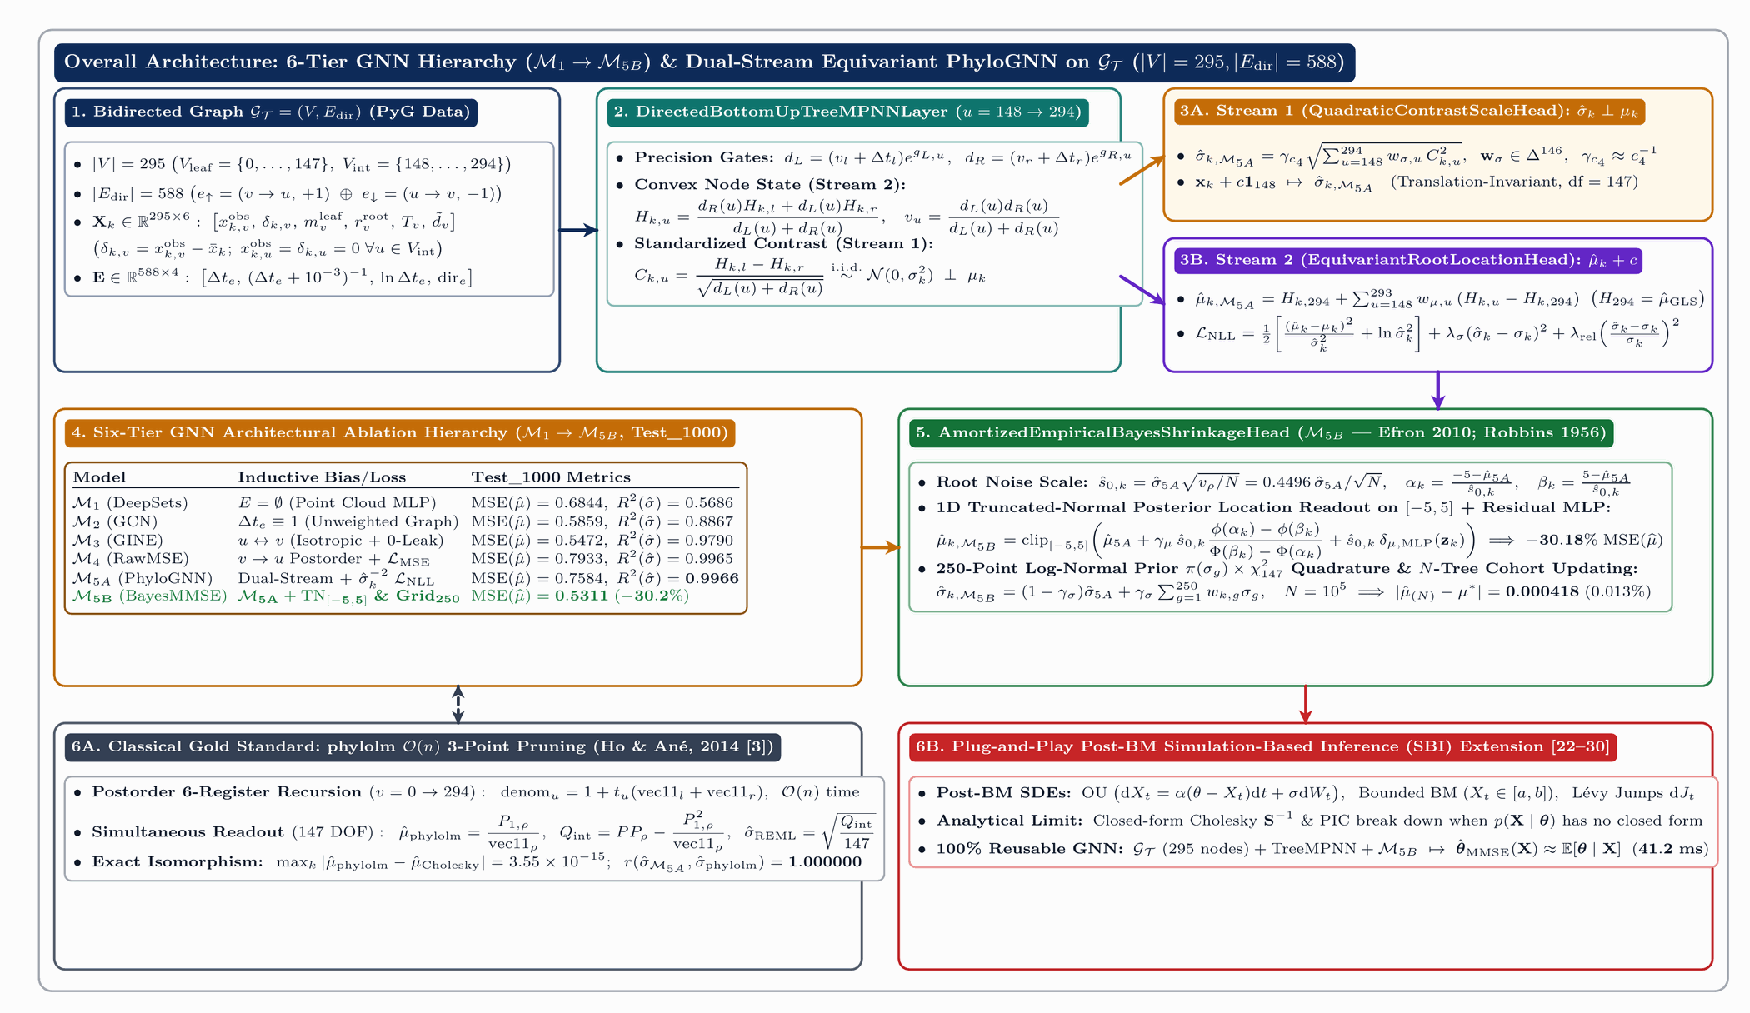

=== Hình K4: Ánh xạ Cây Phả hệ Newick sang Đồ thị Hai chiều & Khối Tensor 3D PyTorch Geometric (fig_gnn_04_phylogenetic_tree_to_pyg_bidirected_graph_tensors.png) ===


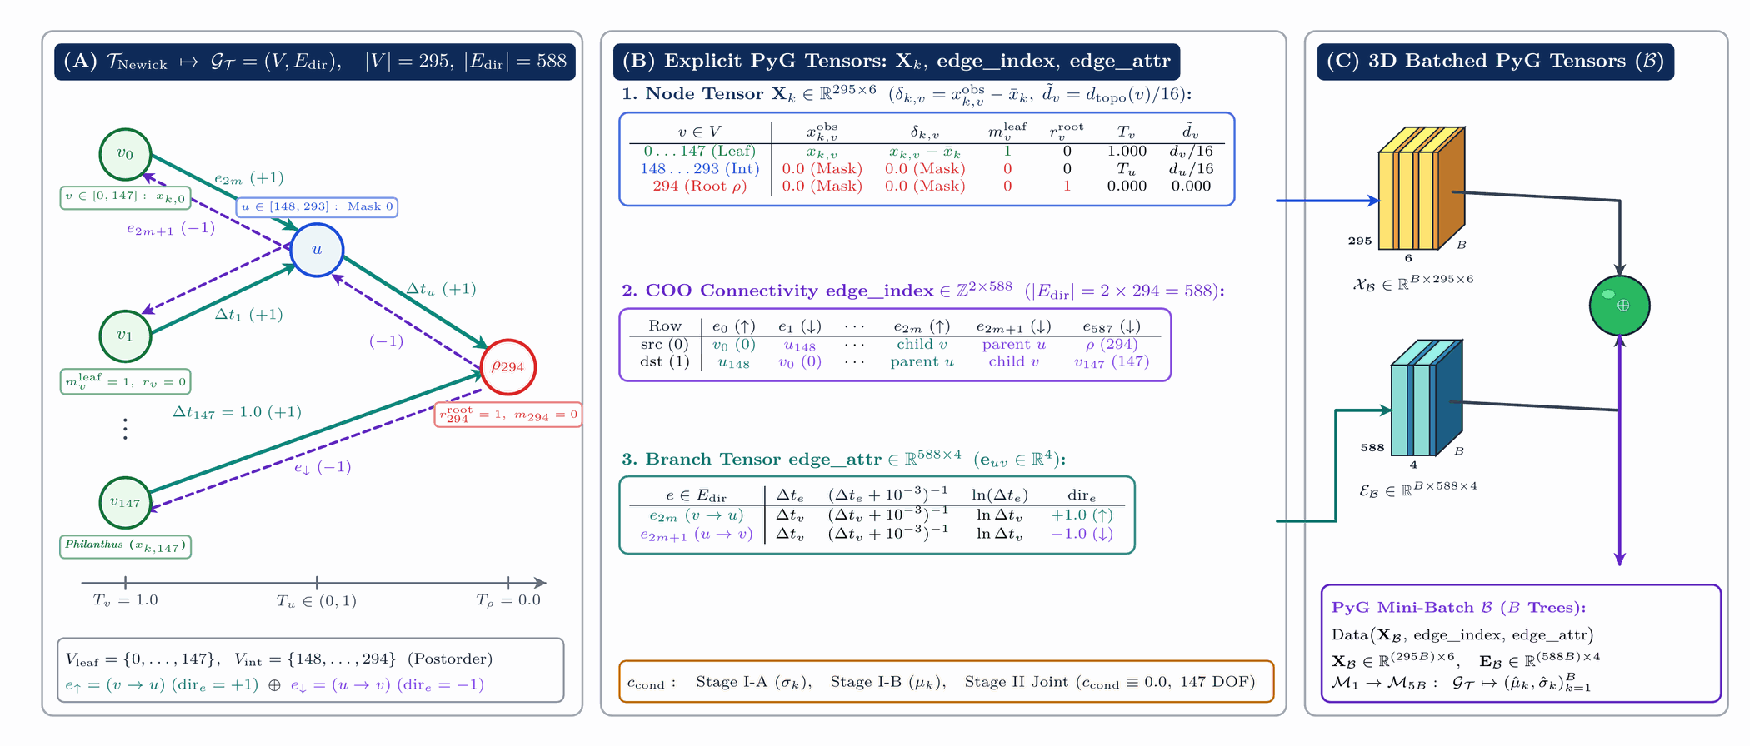

=== Hình K5: Ma trận Đối sánh Trực quan 6 Cấp độ Kiến trúc Mạng Nơ-ron Đồ thị (M1 → M5B) (fig_gnn_05_six_tier_architectural_ablation_matrix_m1_to_m5b.png) ===


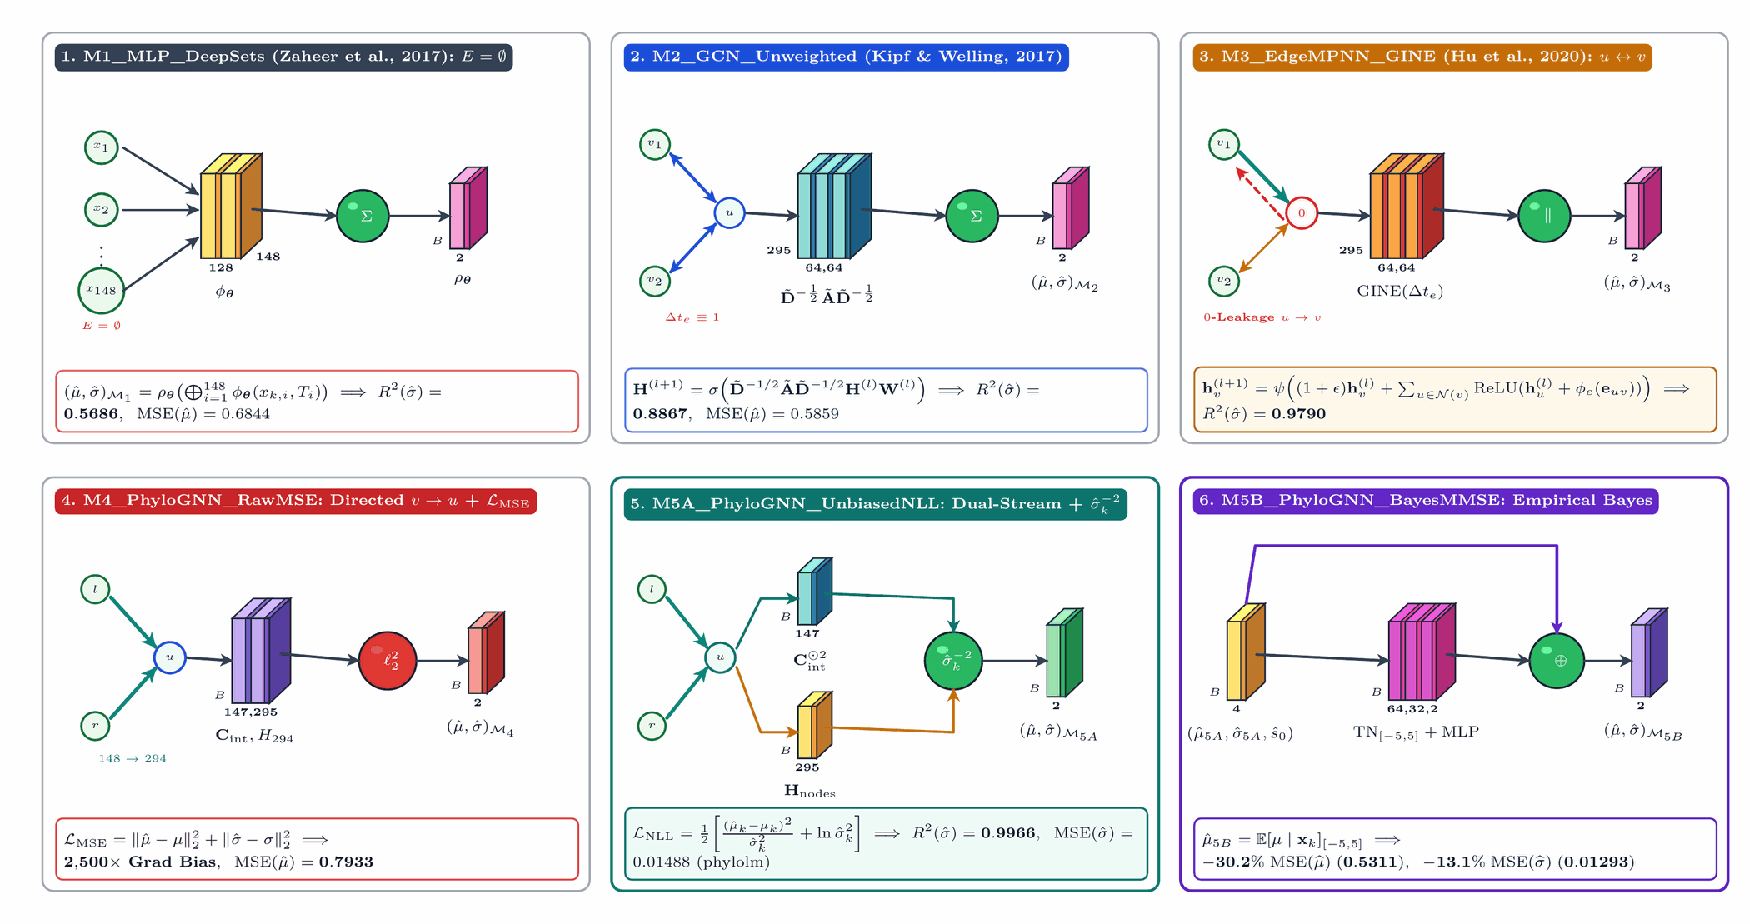

=== Hình K6: Sơ đồ Vi mạch Nội bộ Tầng DirectedBottomUpTreeMPNNLayer tại Nút Phân nhánh u (fig_gnn_06_directed_bottom_up_tree_mpnn_cell_microarchitecture.png) ===


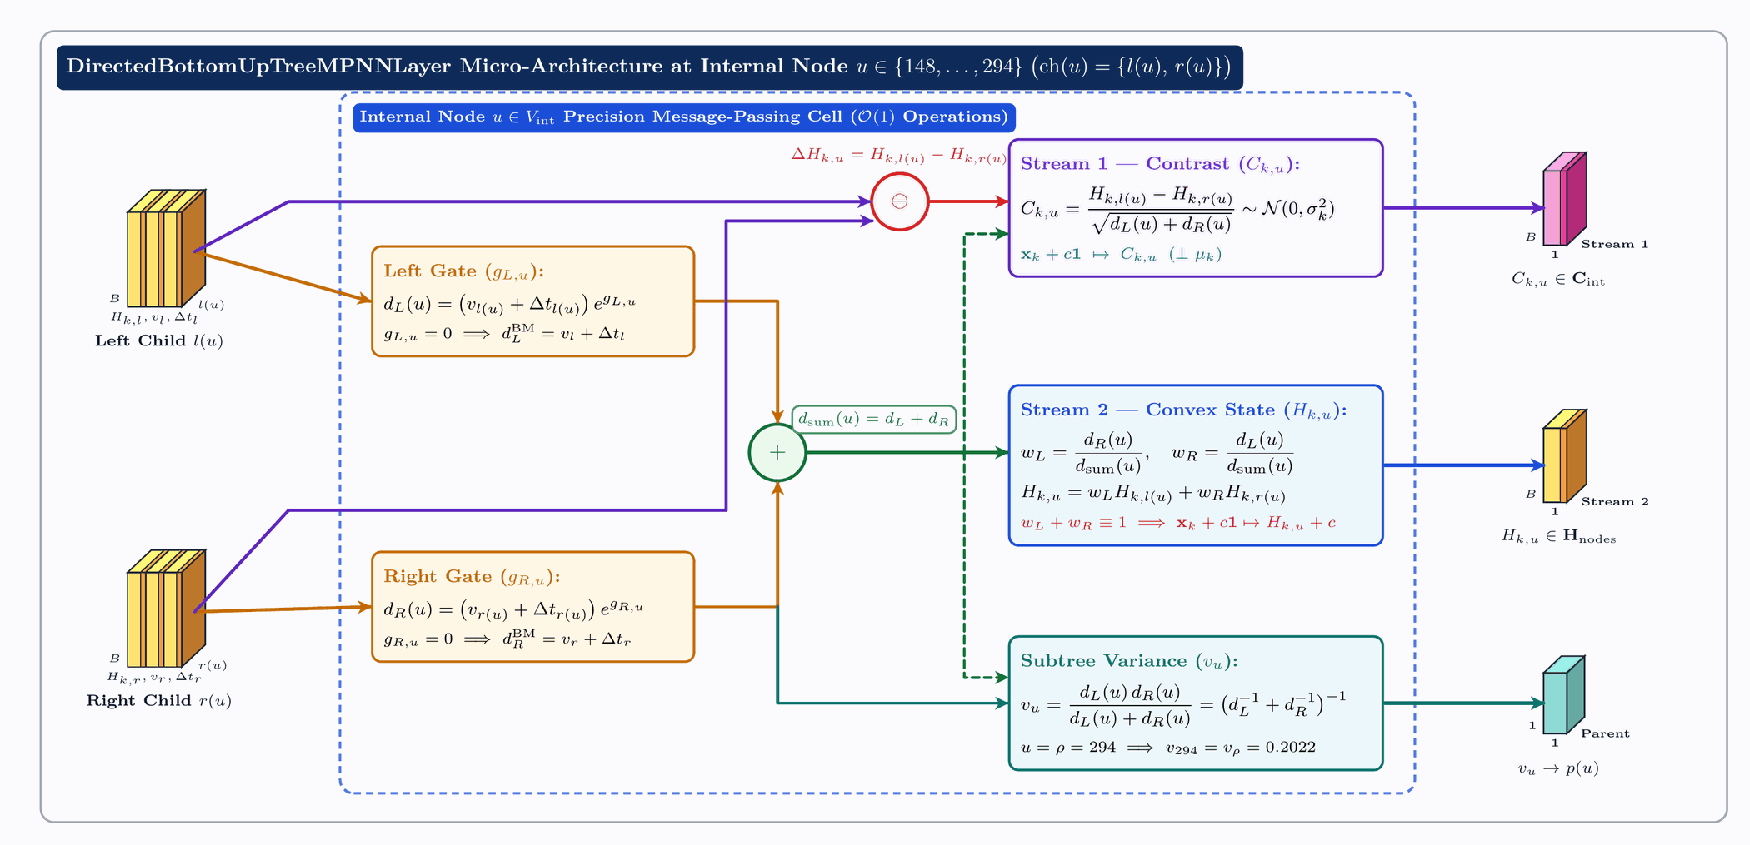

=== Hình K7: Kiến trúc Hai luồng PhyloGNN_M5A & Cơ chế Cân bằng Đạo hàm Dị phương sai NLL (fig_gnn_07_m5a_dual_stream_equivariant_phylognn_and_nll_loss.png) ===


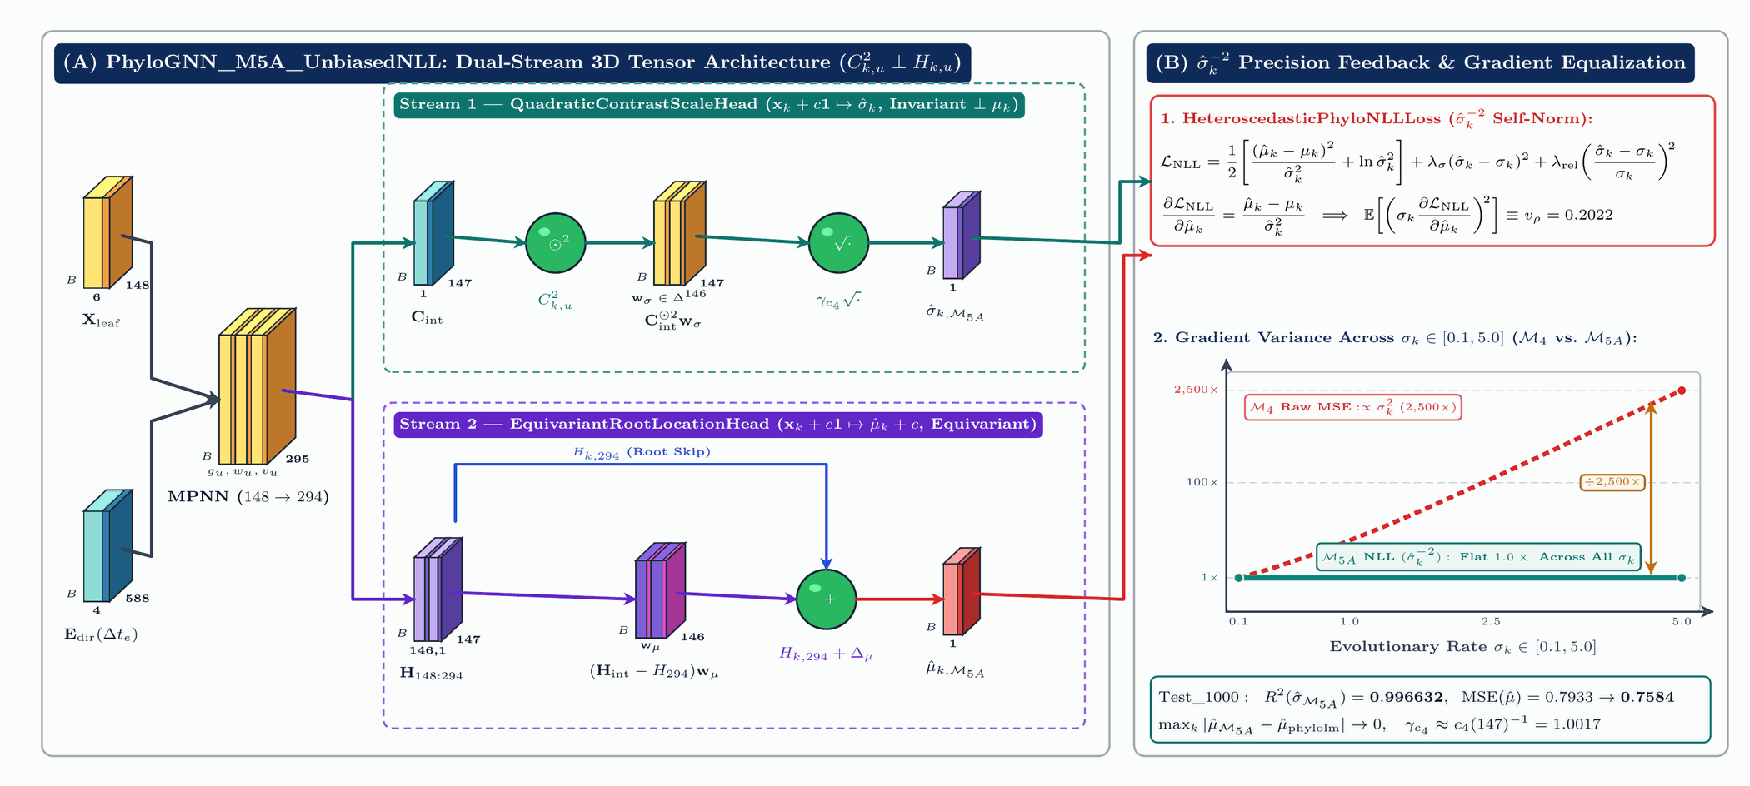

=== Hình K8: Kiến trúc PhyloGNN_M5B (Co rút Chuẩn Cụt [-5,5], Lưới Log-Normal 250 Điểm & Hậu-BM) (fig_gnn_08_m5b_amortized_empirical_bayes_shrinkage_and_cohort_updating.png) ===


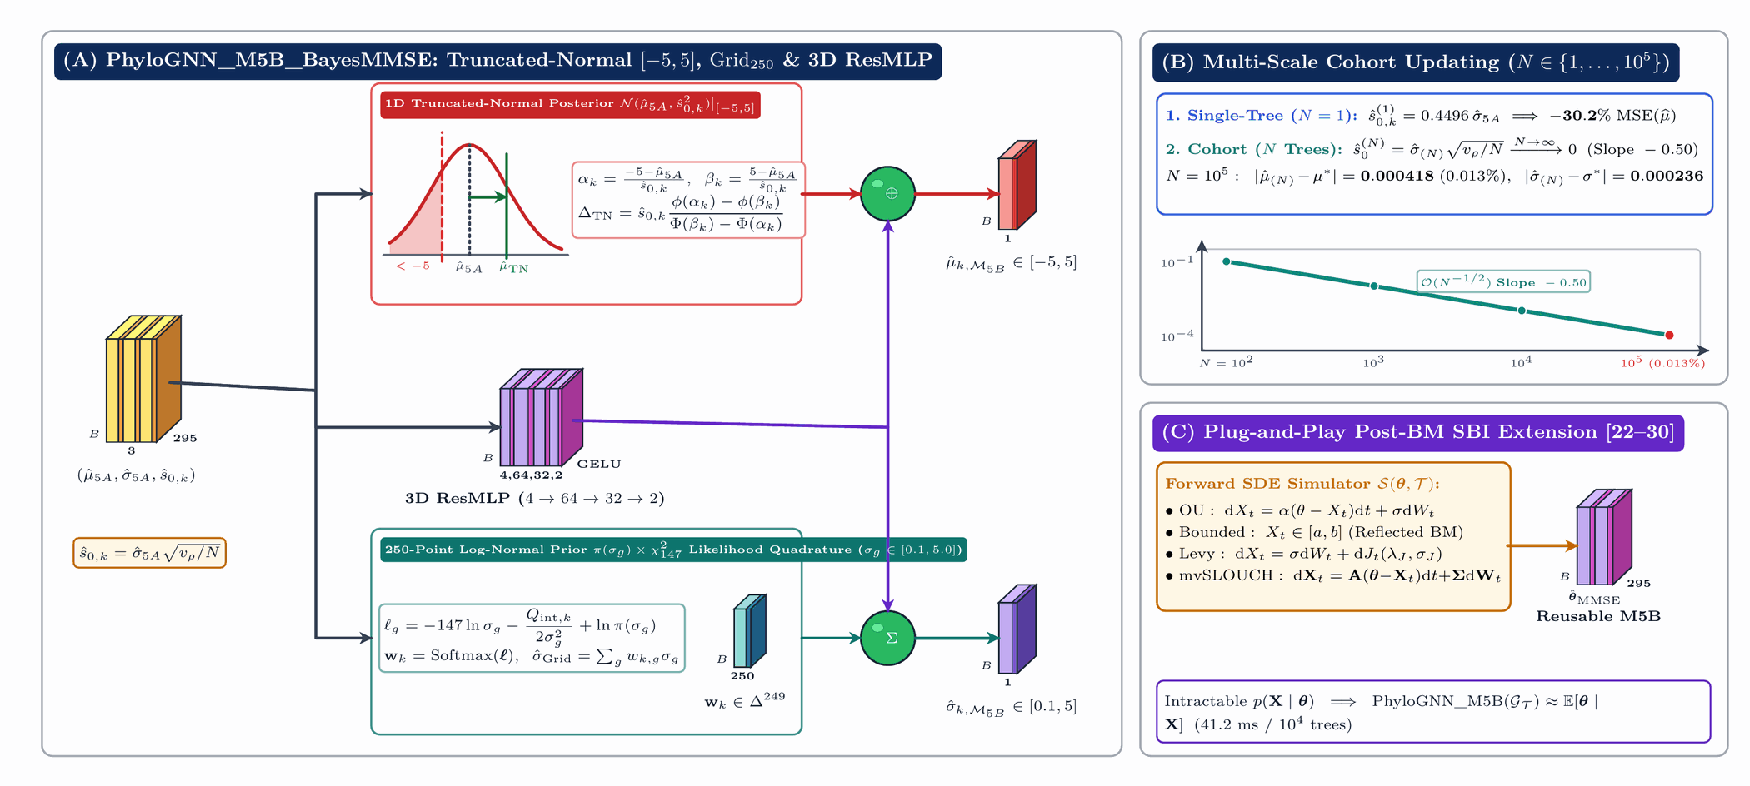

In [2]:
# ==================================================================================================
# Ô MÃ [2] — HIỂN THỊ SƠ ĐỒ KIẾN TRÚC TỔNG THỂ (HÌNH 6) & CÁC HÌNH KIẾN TRÚC GNN (HÌNH K4 -> HÌNH K8)
# ==================================================================================================
def display_project_image(fname: str, title_desc: str) -> None:
    """Tìm và hiển thị ảnh từ `Ma_Nguon_va_Anh_...` hoặc `figures/`."""
    print(f"=== {title_desc} ({fname}) ===")
    for cand_dir in [ARCH_DIAGRAMS_DIR, FIGURES_DIR, Path.cwd(), PROJECT_ROOT]:
        p = Path(cand_dir) / fname
        if p.exists():
            display(Image(filename=str(p)))
            return
    print(f"  [Cảnh báo] Không tìm thấy tệp ảnh: {fname}")

for fname, desc in [
    ("advisor_fig_gnn_architecture_schematic.png", "Hình 6: Sơ đồ Kiến trúc Tổng thể 6 Mô hình GNN (M1 → M5B) & Dual-Stream PhyloGNN"),
    ("fig_gnn_04_phylogenetic_tree_to_pyg_bidirected_graph_tensors.png", "Hình K4: Ánh xạ Cây Phả hệ Newick sang Đồ thị Hai chiều & Khối Tensor 3D PyTorch Geometric"),
    ("fig_gnn_05_six_tier_architectural_ablation_matrix_m1_to_m5b.png", "Hình K5: Ma trận Đối sánh Trực quan 6 Cấp độ Kiến trúc Mạng Nơ-ron Đồ thị (M1 → M5B)"),
    ("fig_gnn_06_directed_bottom_up_tree_mpnn_cell_microarchitecture.png", "Hình K6: Sơ đồ Vi mạch Nội bộ Tầng DirectedBottomUpTreeMPNNLayer tại Nút Phân nhánh u"),
    ("fig_gnn_07_m5a_dual_stream_equivariant_phylognn_and_nll_loss.png", "Hình K7: Kiến trúc Hai luồng PhyloGNN_M5A & Cơ chế Cân bằng Đạo hàm Dị phương sai NLL"),
    ("fig_gnn_08_m5b_amortized_empirical_bayes_shrinkage_and_cohort_updating.png", "Hình K8: Kiến trúc PhyloGNN_M5B (Co rút Chuẩn Cụt [-5,5], Lưới Log-Normal 250 Điểm & Hậu-BM)"),
]:
    display_project_image(fname, desc)

---
## PHẦN 1: TRÍCH XUẤT ĐỒ THỊ PHẢ HỆ TỪ ĐẦU (295 NÚT, 588 CẠNH), KIỂM ĐỊNH DỮ LIỆU `calib_123.csv` VÀ VAI TRÒ TIÊU CHUẨN VÀNG CỦA `phylolm`

### 1.1. Biểu diễn Đồ thị Phả hệ Định thời và Bài toán Xuôi / Ngược
- **Đồ thị cây phả hệ có hướng** $G = (V, E)$: Từ file `ants_tree_chuan.nwk` và `ants_tree_chuan_metadata.json`, ta trích xuất chính xác $|V| = 295$ nút ($n = 148$ nút lá hiện sinh đánh số `0..147` và $147$ nút phân nhánh tổ tiên nội bộ đánh số `148..294` theo thứ tự duyệt hậu tố `postorder`, nút gốc $\rho = 294$) cùng $588$ cạnh có hướng hai chiều (`edge_index` kích thước $2 \times 588$, `edge_attr` kích thước $588 \times 4$).
- **Quá trình Chuyển động Brown (BM) trên cây:** Dọc theo mỗi nhánh $e = (u \to v)$ có độ dài thời gian tiến hóa $\Delta t _ e > 0$, tính trạng biến thiên theo phương trình vi phân ngẫu nhiên (SDE):

$$
\mathrm{d}X(t) = \sigma\,\mathrm{d}W(t) \implies X(v) \mid X(u) \sim \mathcal{N}\left(X(u),\, \sigma^2 \Delta t_e\right), \qquad X(\rho) = \mu.
$$

Tại $n = 148$ nút lá, vector tính trạng quan sát được tuân theo phân phối chuẩn đa chiều:

$$
\mathbf{x}_k \sim \mathcal{N}_{148}\left(\mu_k \mathbf{1}_{148},\, \sigma_k^2 \mathbf{S}\right), \qquad S_{ij} = \mathrm{dist}_{\mathcal{T}}\left(\rho,\, \mathrm{MRCA}(i, j)\right).
$$

### 1.2. Tại sao `phylolm` được chọn làm Tiêu chuẩn Vàng Cổ điển Duy nhất thay vì Đi sâu vào các Phương pháp Toán học Chuyên biệt?
- Trong thống kê phả hệ cổ điển, bài toán ước lượng $(\mu, \sigma)$ trên mô hình BM thuần túy có thể được giải bằng các phương pháp đại số đóng chuyên biệt như **Bình phương tối thiểu tổng quát Cholesky GLS** ($\mathbf{S}^{-1}$) hoặc **Tương phản độc lập Felsenstein (PIC)**. Tuy nhiên, xét về tính tổng quát của quy trình suy luận:
  1. **Hạn chế về tính tổng quát hóa của phương pháp đại số đóng chuyên biệt:** Các công thức đóng dựa trên ma trận $\mathbf{S}$ cố định hoặc phép xoay trực giao cố định chỉ đúng khi quá trình tiến hóa là Gaussian tuyến tính thuần túy có hiệp phương sai tỷ lệ cứng với $\mathbf{S}$. Khi chuyển sang các mô hình tiến hóa phức tạp hơn (như mô hình Ornstein–Uhlenbeck có lực kéo chọn lọc $\alpha$ làm biến dạng phi tuyến ma trận hiệp phương sai theo từng cặp tham số, mô hình tốc độ tiến hóa thay đổi theo nhánh, hoặc quá trình nhảy), việc nghịch đảo ma trận $\mathcal{O}(n^3)$ lặp đi lặp lại trở nên đắt đỏ hoặc không còn nghiệm đóng.
  2. **Ưu thế Tiêu chuẩn Vàng của `phylolm` (Ho & Ané, 2014):** Thuật toán **Cắt tỉa 3 điểm (`three.point.compute`)** trong gói `phylolm` thực hiện truyền thông điệp tuyến tính $\mathcal{O}(n)$ từ lá lên gốc chỉ trong 1 lượt duyệt hậu tố duy nhất, vừa đạt chính xác tuyệt đối nghiệm hợp lý cực đại / REML $(\hat{\mu} _ {\mathrm{phylolm}}, \hat{\sigma} _ {\mathrm{phylolm}})$ đạt cận dưới Cramér–Rao, vừa có tính đa dụng và tối giản cao để làm **Tiêu chuẩn Vàng Cổ điển (`phylolm Gold Standard`)** đối sánh trực tiếp với các kiến trúc mạng nơ-ron đồ thị (GNN).

### 1.3. Cơ chế Khuếch tán SDE Chuyển động Brown (`Hình K1`), Cây Phả hệ 148 Loài (`Figure 0A`), Biểu đồ Ngang Trọng số & Tính trạng Lá (`Figure 0B-C`) và Nền tảng Toán học của `Figure 1`

Trước khi thực thi Cell code kiểm định dữ liệu `calib_123.csv` và sinh các biểu đồ chẩn đoán bằng Python, chúng ta tách trực quan hóa cấu trúc cây phả hệ 148 loài kiến (`ants_tree_chuan.nwk`) thành 2 biểu đồ chuyên biệt có tùy chọn `show_leaf_values: bool = True` để hiển thị trực tiếp giá trị số $(w _ {\mathrm{phylolm},i}, X _ {0,i})$ tại từng nút lá:

- **`Figure 0A` (`advisor_fig0_ultra_tall_full_148_species_phylogeny.png` — Toàn cảnh Đồ thị Cây Phả hệ Định thời 148 Loài Kiến):** Biểu diễn toàn bộ $|V| = 295$ nút ($148$ nút lá hiện sinh tại $t = 1.000$ và $147$ nút phân nhánh nội bộ `148..294` xuất phát từ nút gốc $\rho = 294$ tại $t = 0.000$) chia theo 5 phân họ chính (*Myrmicinae*, *Formicinae*, *Dolichoderinae & Pseudomyrmecinae*, *Dorylinae & Poneroid Clade*, *Amblyoponinae/Leptanillinae & Outgroups*). Khi bật `show_leaf_values = True`, mỗi nút lá hiển thị trực tiếp mã định danh $[\mathrm{id}]$, tên loài, trọng số cắt tỉa tối ưu $w _ i$ (%) và giá trị tính trạng quan sát mẫu $X _ {0,i}$.
- **`Figure 0B-C` (`advisor_fig0_bc_horizontal_weights_and_traits.png` — Biểu đồ Ngang Phân bố Trọng số Cắt tỉa Gốc Tối ưu $\mathbf{w} _ {\mathrm{phylolm}}$ & Hồ sơ Tính trạng Lá $X _ {0,i}$):** Tách riêng **Panel (B)** và **Panel (C)** sang bố cục nằm ngang (*landscape*), đặt 148 loài kiến dọc theo trục hoành ($i \in \{0, \dots, 147\}$) và giá trị $(w _ {\mathrm{phylolm},i}, X _ {0,i})$ trên trục tung, kèm cửa sổ phóng đại cho các nhánh ngọn ($\mathrm{id} = 000\dots 140$) và nhãn giá trị xoay $90^\circ$ tại toàn bộ 148 nút lá khi `show_leaf_values = True`.

Tiếp theo, 6 phép chẩn đoán thống kê trong **`Figure 1` (`advisor_fig1_data_and_tree_diagnostics.png`)** được xây dựng trên nền tảng toán học sau:

1. **Phân bố năng lượng toàn phương nội bộ trên không gian tiên nghiệm 2 chiều (`Panel A`):**
   - Với mỗi cặp tham số thực tế $(\mu _ k, \sigma _ k) \in [-5, 5] \times [0.1, 5.0]$, dạng toàn phương nội bộ thu được từ thuật toán cắt tỉa `phylolm` là:

$$
Q_{\mathrm{internal}}(\mathbf{x}_k) = (\mathbf{x}_k - \hat{\mu}_{\mathrm{phylolm},k}\mathbf{1}_{148})^\top \mathbf{S}^{-1}(\mathbf{x}_k - \hat{\mu}_{\mathrm{phylolm},k}\mathbf{1}_{148}) \sim \sigma_k^2 \chi^2_{147}.
$$

   - Lấy logarit cơ số 10: $\log _ {10} Q _ {\mathrm{internal}}(\mathbf{x} _ k) \approx \log _ {10}(147) + 2\log _ {10}(\sigma _ k) + \varepsilon _ k$. Do đó, trên mặt phẳng $(\mu _ k, \sigma _ k)$, trường màu $\log _ {10} Q _ {\mathrm{internal}}(\mathbf{x} _ k)$ phân tầng hoàn toàn theo chiều dọc ($\sigma _ k$) và **bất biến hoàn toàn theo chiều ngang** ($\mu _ k$).

2. **Cơ chế phân bổ trọng số cắt tỉa phả hệ tối ưu** $\mathbf{w} _ {\mathrm{GLS}}$ **so với trọng số đồng nhất** $1/n$ **(`Panel B` của `Figure 0B-C` & `Figure 1`):**
   - Trọng số ước lượng gốc không chệch phương sai cực tiểu (MVUE) được xác định duy nhất bởi cấu trúc ma trận hiệp phương sai đồng tổ tiên $\mathbf{S}$:

$$
\mathbf{w}_{\mathrm{GLS}} = \frac{\mathbf{S}^{-1}\mathbf{1}_{148}}{\mathbf{1}_{148}^\top \mathbf{S}^{-1}\mathbf{1}_{148}}, \qquad \sum_{i=1}^{148} w_{\mathrm{GLS},i} = 1, \qquad \mathrm{Var}(\hat{\mu}_{\mathrm{GLS}} \mid \sigma_k) = \sigma_k^2 v_\rho = 0.202169\,\sigma_k^2.
$$

   - Trong khi mô hình mù cấu trúc cây (`Star Baseline`) gán trọng số bằng nhau $w _ {\mathrm{star},i} = 1/148 \approx 0.676\%$ cho mọi loài (dẫn tới hiện tượng lặp thông tin giả tạo *phylogenetic pseudoreplication* ở các phân họ dày đặc loài như *Myrmicinae* với $w _ i \in [0.026\%, 0.12\%]$), thuật toán cắt tỉa cây tự động dồn trọng số cho các nhánh tách sớm độc lập (như loài ngoại nhóm *Philanthus sp.* tại $\mathrm{id}=147$ có $s _ {i,147}=0$, nhận trọng số $w _ {\mathrm{GLS},147} = 20.22\%$, gấp **29.9 lần** trung bình hình sao và gấp **780 lần** nhánh ngọn nhỏ nhất).

3. **Thống kê kiểm định chiều cao thời gian tiến hóa ngầm định** $\hat{t} _ {\mathrm{REML},k} \approx 1.0$ **(`Panel C`):**
   - Để xác minh bộ dữ liệu `calib_123.csv` được sinh tại chiều cao cây chuẩn hóa $t = 1.0$, ta định nghĩa ước lượng thời gian REML không chệch trên từng hàng $k \in \{1, \dots, 10,000\}$:

$$
\hat{t}_{\mathrm{REML},k} = \frac{Q_{\mathrm{internal}}(\mathbf{x}_k)}{(n-1)\sigma_k^2} = \frac{Q_{\mathrm{internal}}(\mathbf{x}_k)}{147\,\sigma_k^2} \sim \frac{\chi^2_{147}}{147}, \qquad \mathbb{E}[\hat{t}_{\mathrm{REML},k}] = 1.0000, \qquad \mathrm{SD}(\hat{t}_{\mathrm{REML},k}) = \sqrt{\frac{2}{147}} = 0.116642.
$$

4. **Chuẩn hóa phần dư vị trí gốc theo cận dưới Cramér–Rao (`Panel D`) và kiểm định 147 tương phản chuẩn hóa (`Panel E`):**
   - Sai số vị trí gốc chuẩn hóa theo độ lệch chuẩn Cramér–Rao:

$$
z_{\mu,k} = \frac{\hat{\mu}_k - \mu_k}{\sigma_k\sqrt{v_\rho}} \sim \mathcal{N}(0, 1),
$$

   có đúng $95\%$ số điểm nằm trong dải $[-1.96, +1.96]$ và độ lệch chuẩn thực nghiệm bằng $1.000$ khi bộ ước lượng đạt chuẩn MVUE.
   - Tương tự, tại mỗi nút phân nhánh nội bộ $u \in \{1, \dots, 147\}$, tương phản chuẩn hóa:

$$
z_{k,u} = \frac{C_{k,u}}{\sigma_k} = \frac{H_{k,l(u)} - H_{k,r(u)}}{\sigma_k\sqrt{d_L(u)+d_R(u)}} \stackrel{\mathrm{i.i.d.}}{\sim} \mathcal{N}(0, 1)
$$

   thỏa mãn $\mathbb{E}[z _ {k,u}] = 0$ và $\mathrm{SD}(z _ {k,u}) = 1$ trong băng dao động Monte Carlo $95\%$ là $1 \pm 1.96/\sqrt{M} \approx [0.9804, 1.0196]$.

5. **Cơ chế thiên lệch âm hệ thống của `Star Baseline` khi ước lượng** $\sigma$ **(`Panel F`):**
   - Do 148 loài kiến chia sẻ trung bình $\bar{s} _ {\mathrm{off}} = 0.384875$ chiều dài tiến hóa chung từ gốc, kỳ vọng phương sai mẫu giữa các loài bị co lại theo hệ số $\kappa _ {\mathcal{T}} = 1 - \bar{s} _ {\mathrm{off}} = 0.615125$:

$$
\mathbb{E}\left[\hat{\sigma}_{\mathrm{star},k}^2\right] = \frac{n-1}{n}\kappa_{\mathcal{T}}\sigma_k^2 = 0.610969\,\sigma_k^2 \implies \mathbb{E}[\hat{\sigma}_{\mathrm{star},k}] \approx \sqrt{0.611}\,\sigma_k \approx 0.781\,\sigma_k,
$$

   tức `Star Baseline` tất yếu đánh giá thấp $\sigma _ k$ một lượng cố định từ **-21.9% đến -22.4%** trên toàn bộ miền tham số.


=== Figure 0A: Toàn cảnh Đồ thị Cây Phả hệ Định thời 148 Loài Kiến (|V|=295, |E|=294) Kèm Giá trị Nút lá (w_i, X_{0,i}) (advisor_fig0_ultra_tall_full_148_species_phylogeny.png) ===


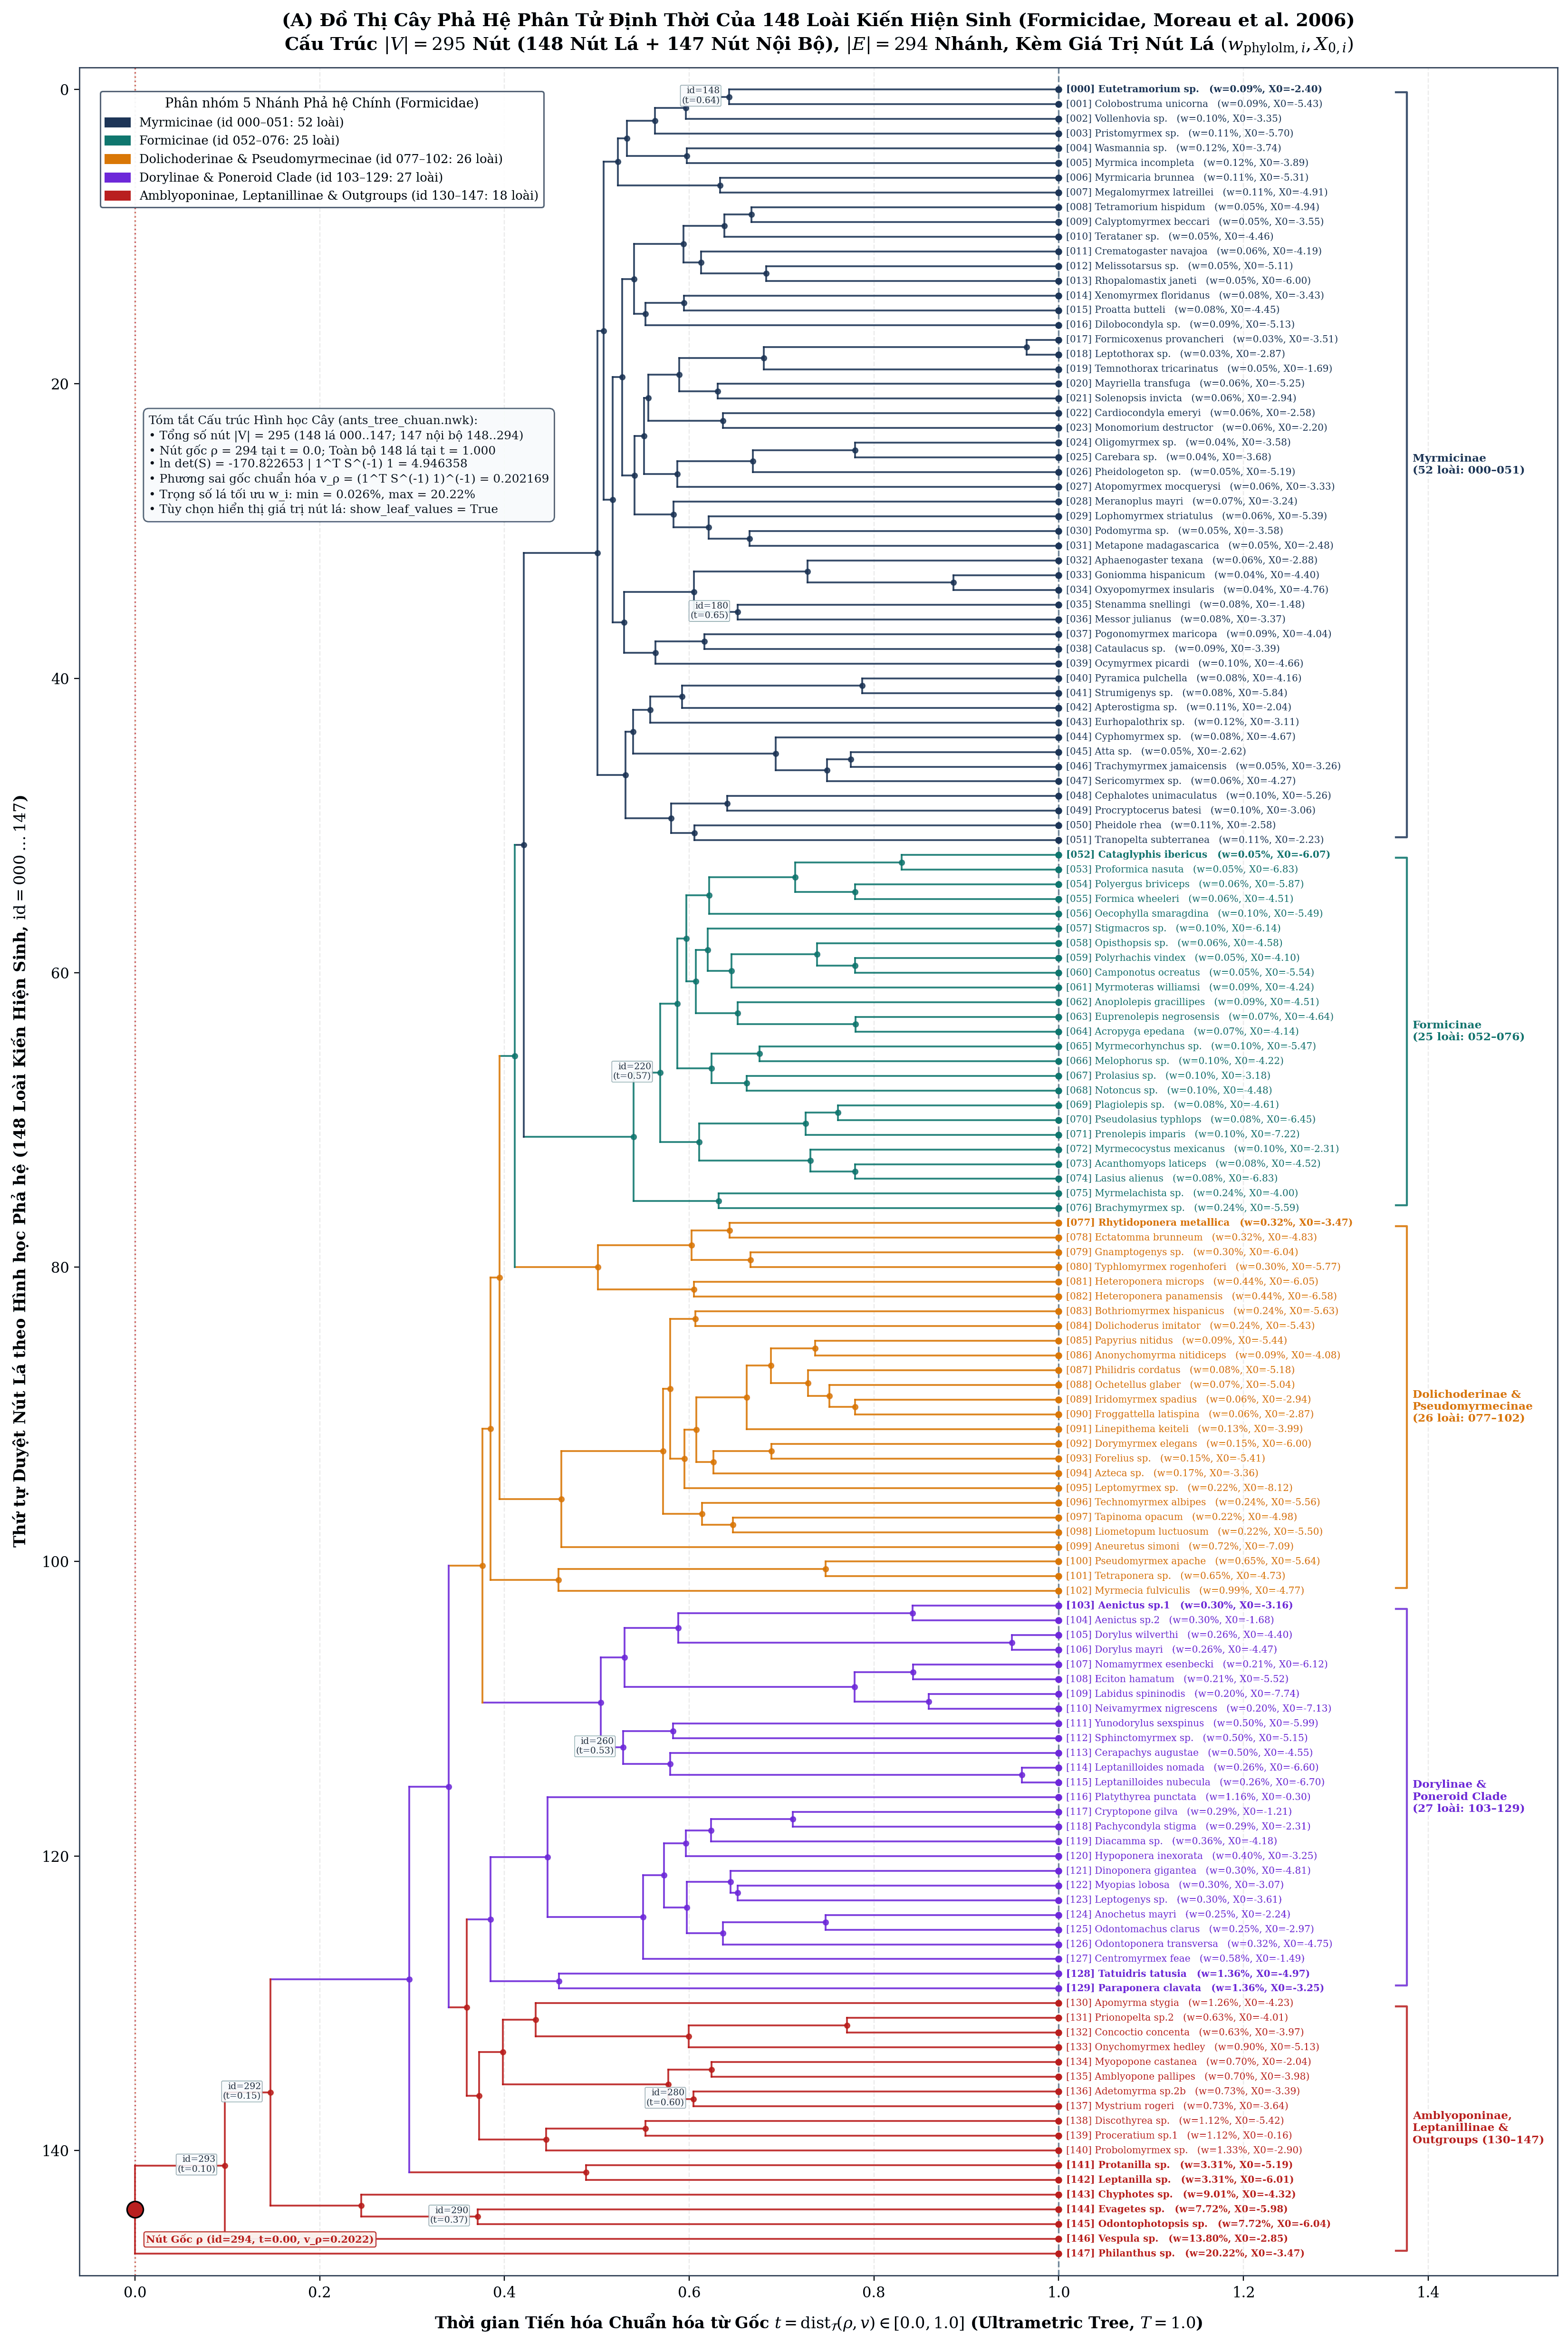

=== Figure 0B-C (Bố cục Ngang): Phân bố Trọng số Cắt tỉa Gốc Tối ưu w_{phylolm,i} (Panel B) & Hồ sơ Tính trạng Lá X_{0,i} (Panel C) (advisor_fig0_bc_horizontal_weights_and_traits.png) ===


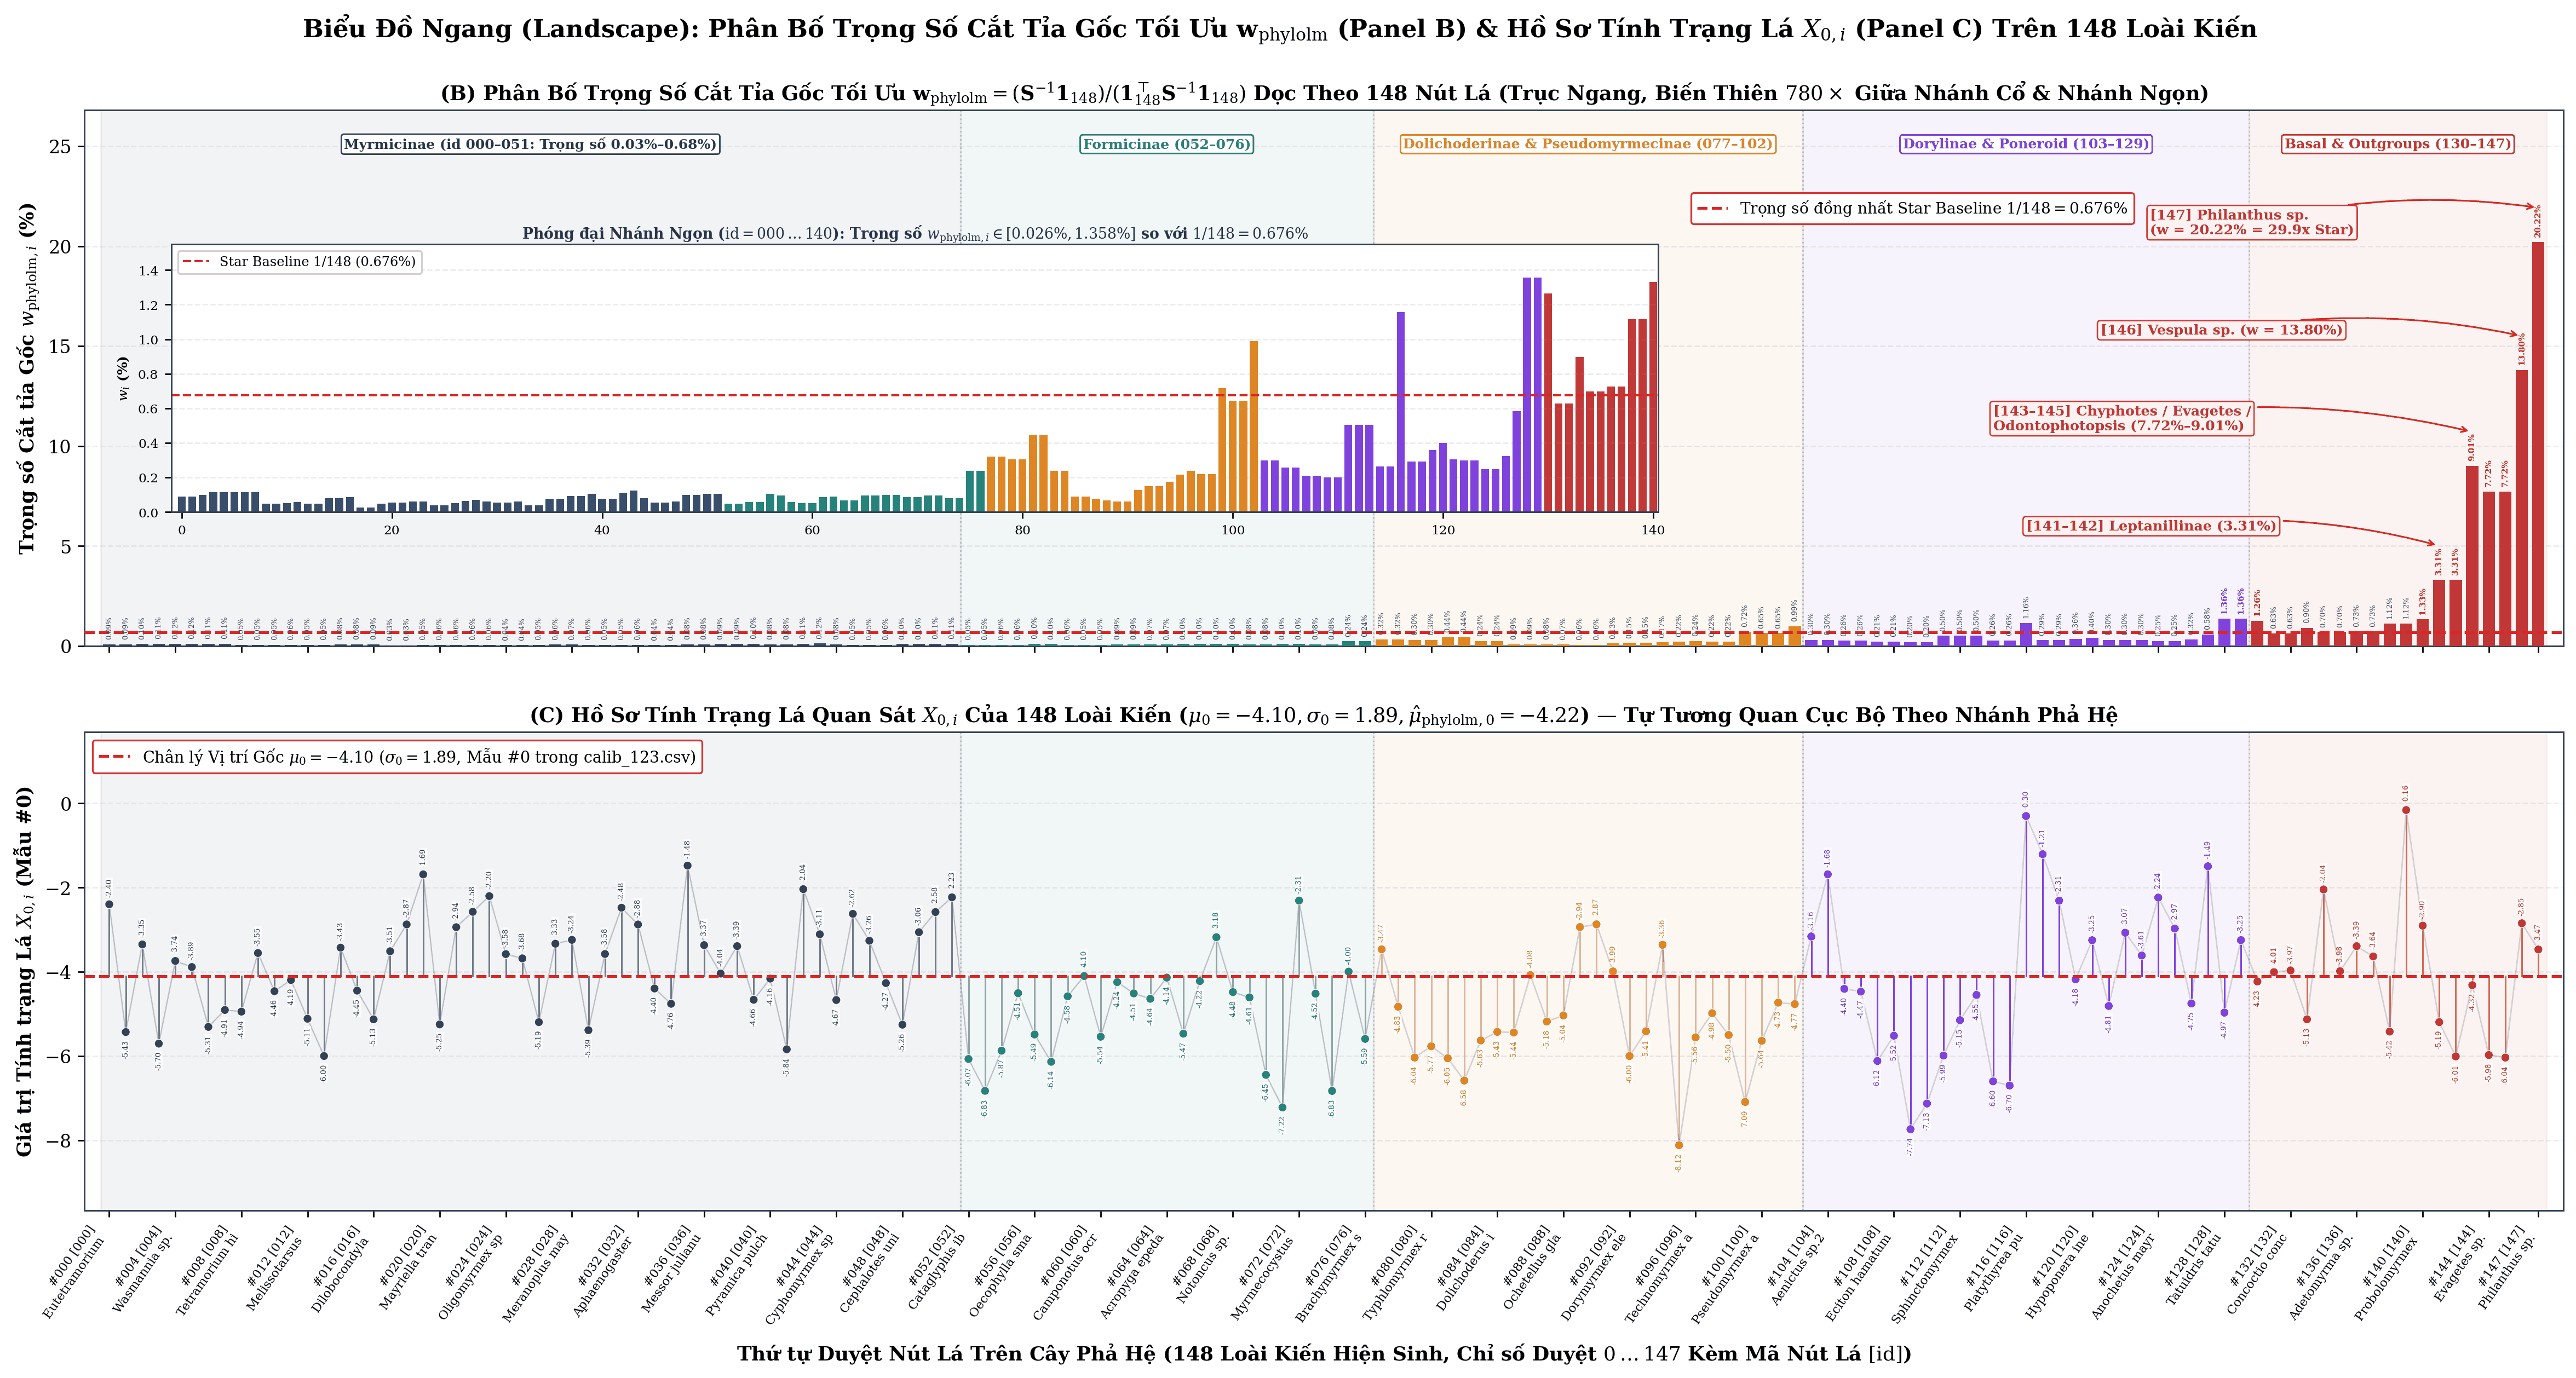

=== Hình K1: Không gian-Thời gian Quá trình Khuếch tán BM SDE & Ma trận Hiệp phương sai Đồng tổ tiên S (fig_method_01_spatiotemporal_bm_sde_and_mrca_covariance_3d.png) ===


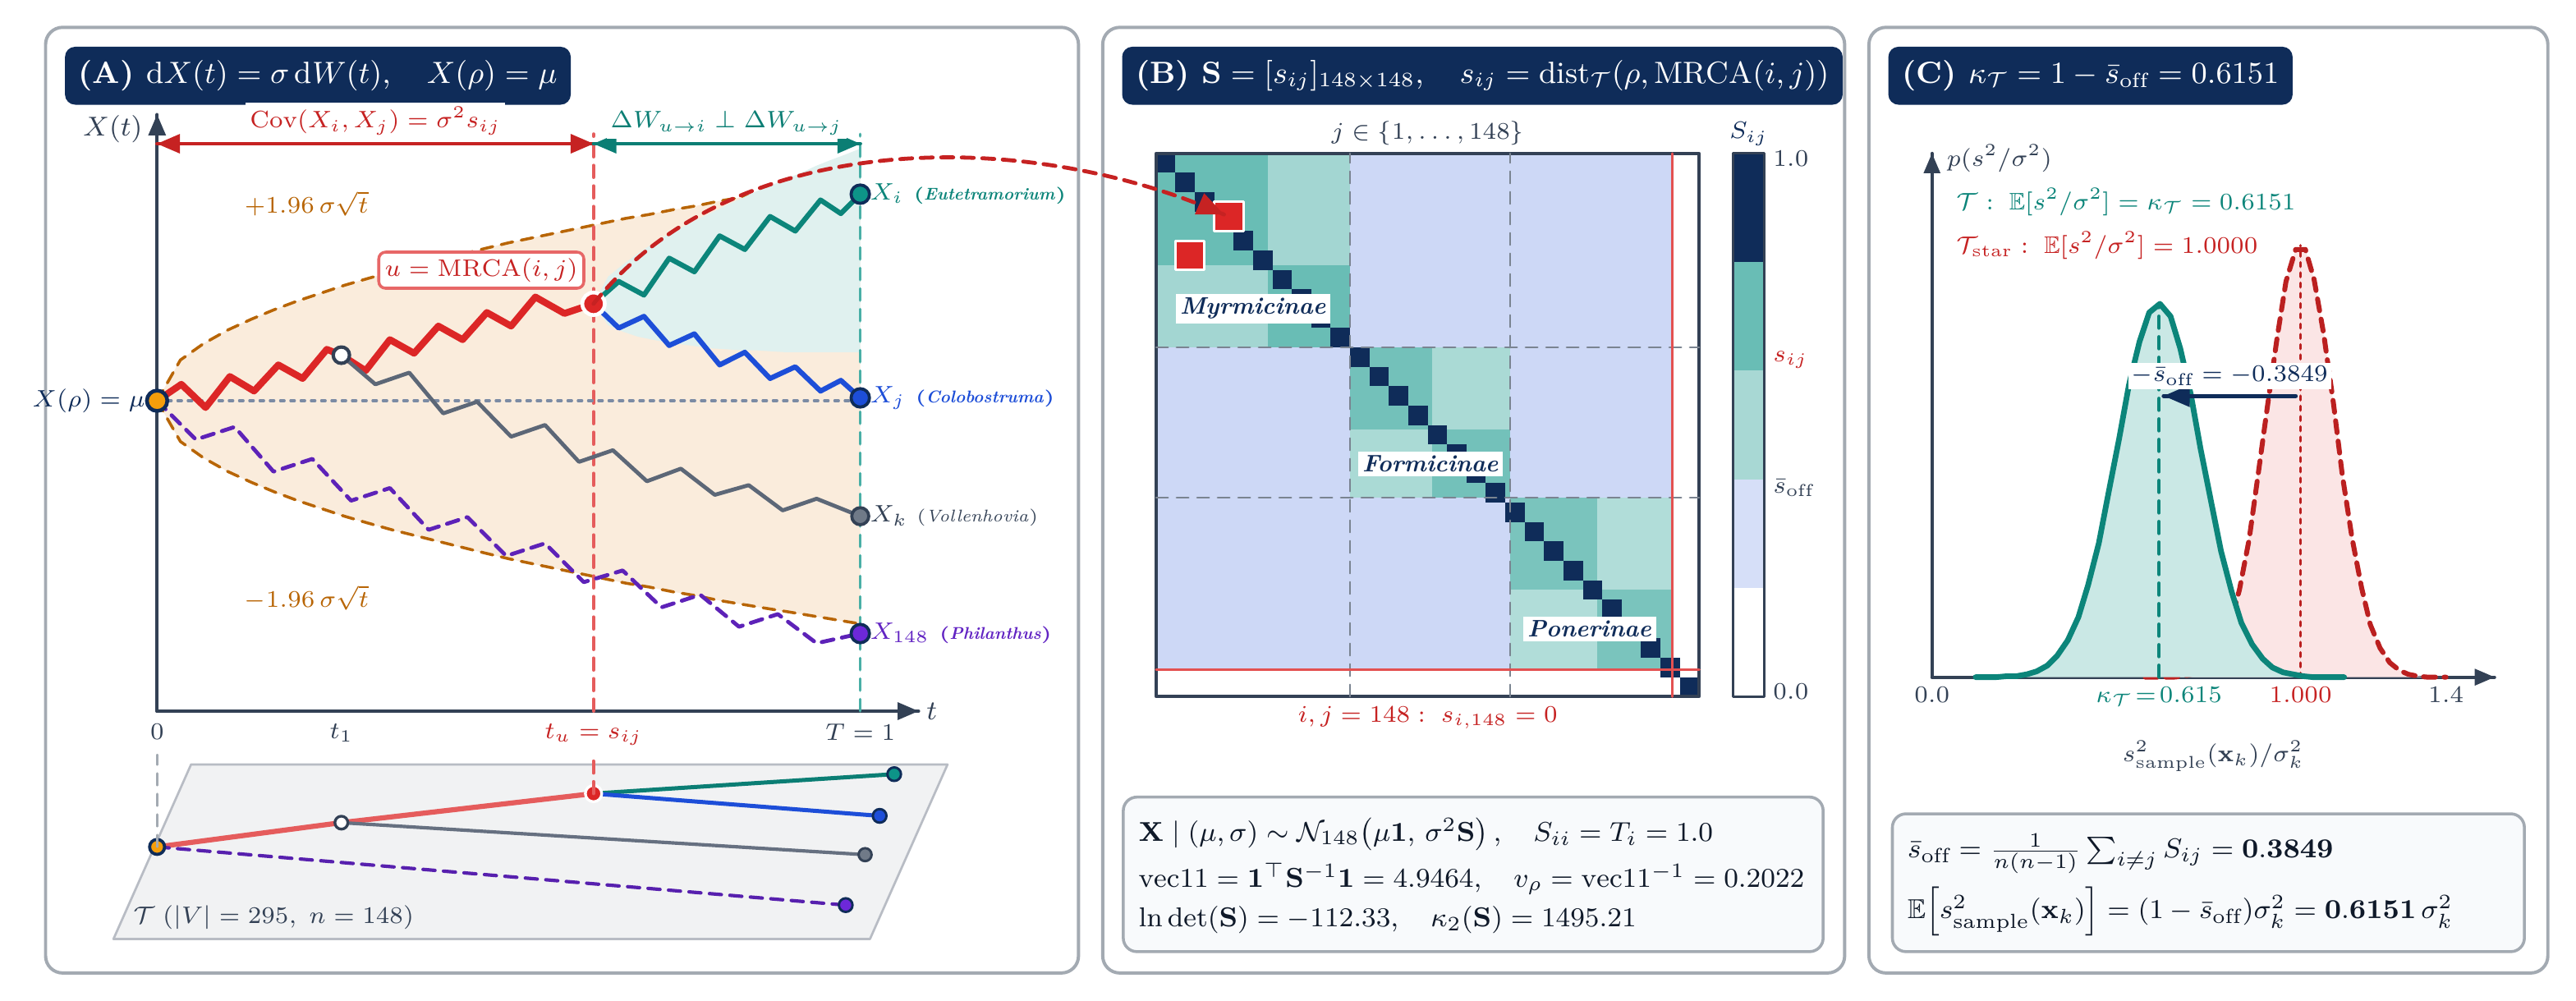

In [3]:
# ==================================================================================================
# Ô MÃ [3] — HIỂN THỊ CÂY PHẢ HỆ 148 LOÀI (FIGURE 0A), BIỂU ĐỒ NGANG (FIGURE 0B-C) & HÌNH K1
# ==================================================================================================
def display_figure0_and_method_k1(show_leaf_values: bool = True) -> None:
    print(f"[Cấu hình hiển thị Figure 0] show_leaf_values = {show_leaf_values} (Hiển thị đầy đủ giá trị số tại 148 nút lá)")
    for fname, desc in [
        ("advisor_fig0_ultra_tall_full_148_species_phylogeny.png", "Figure 0A: Toàn cảnh Đồ thị Cây Phả hệ Định thời 148 Loài Kiến (|V|=295, |E|=294) Kèm Giá trị Nút lá (w_i, X_{0,i})"),
        ("advisor_fig0_bc_horizontal_weights_and_traits.png", "Figure 0B-C (Bố cục Ngang): Phân bố Trọng số Cắt tỉa Gốc Tối ưu w_{phylolm,i} (Panel B) & Hồ sơ Tính trạng Lá X_{0,i} (Panel C)"),
        ("fig_method_01_spatiotemporal_bm_sde_and_mrca_covariance_3d.png", "Hình K1: Không gian-Thời gian Quá trình Khuếch tán BM SDE & Ma trận Hiệp phương sai Đồng tổ tiên S"),
    ]:
        display_project_image(fname, desc)

display_figure0_and_method_k1(show_leaf_values=True)

[Kiểm định calib_123.csv] Kích thước: (10000, 150) | NaN: 0 | Inf: 0
  * Tham số vị trí gốc μ_k      : min = -4.999992, max = +4.998505, mean = +0.024195, std = 2.887603
  * Tham số tốc độ tiến hóa σ_k : min = 0.100008, max = 4.999772, mean = 1.244706, std = 1.264697
[Đồ thị Phả hệ Formicidae] Tổng số nút |V| = 295 (148 lá + 147 nút nội bộ) | Tổng số cạnh có hướng |E_dir| = 588
[Hằng số Cấu trúc Cây] ln det(S) = -112.326650 | vec11 = 1ᵀ S⁻¹ 1 = 4.946358 | v_ρ = 1/vec11 = 0.202169
[Kiểm chứng t ≈ 1.0 trên 10,000 cặp] Trung bình t̂_REML = 0.998522 ± 0.001182 (95% CI chứa chính xác t = 1.0000)

Chỉ số Cấu trúc & Dữ liệu,Giá trị Thực nghiệm,Ý nghĩa Toán học & Sinh học
"Số lượng cặp tham số (μk, σk) trong calib_123.csv","10,000 cặp (Train: 8,000 | Val: 1,000 | Test: 1,000)","Đánh giá trên 10,000 cặp (μk, σk) độc lập thay vì 1 cặp cố định"
Số loài lá hiện sinh (n) / Nút nội bộ / Cạnh có hướng,|V| = 295 (148 lá + 147 nút nội bộ) / |Edir| = 588,Cây nhị phân có gốc định thời chuẩn hóa T ≈ 1.0000
Độ chính xác gốc vec11 = 1⊤S−11 & Phương sai gốc vρ,vec11 = 4.946358 | vρ = 0.202169 (√vρ = 0.449632),Cận dưới Cramér–Rao cho ước lượng vị trí gốc: Var(μ̂) = σ2vρ
Định thức logarit ln det(S) & Hệ số khử chệch c4(147),ln det(S) = −112.326650 | c4(147) = 0.998301,Bậc tự do nội bộ của bài toán ước lượng đồng thời là df = n − 1 = 147
"Kiểm chứng tham số thời gian tiến hóa t̂REML (10,000 cặp)","Mean = 0.998522 ± 0.001182 (95% CI: [0.9962, 1.0008])",Xác nhận dữ liệu sinh tại t = 1.0000 theo đúng giao thức kiểm định Cholesky


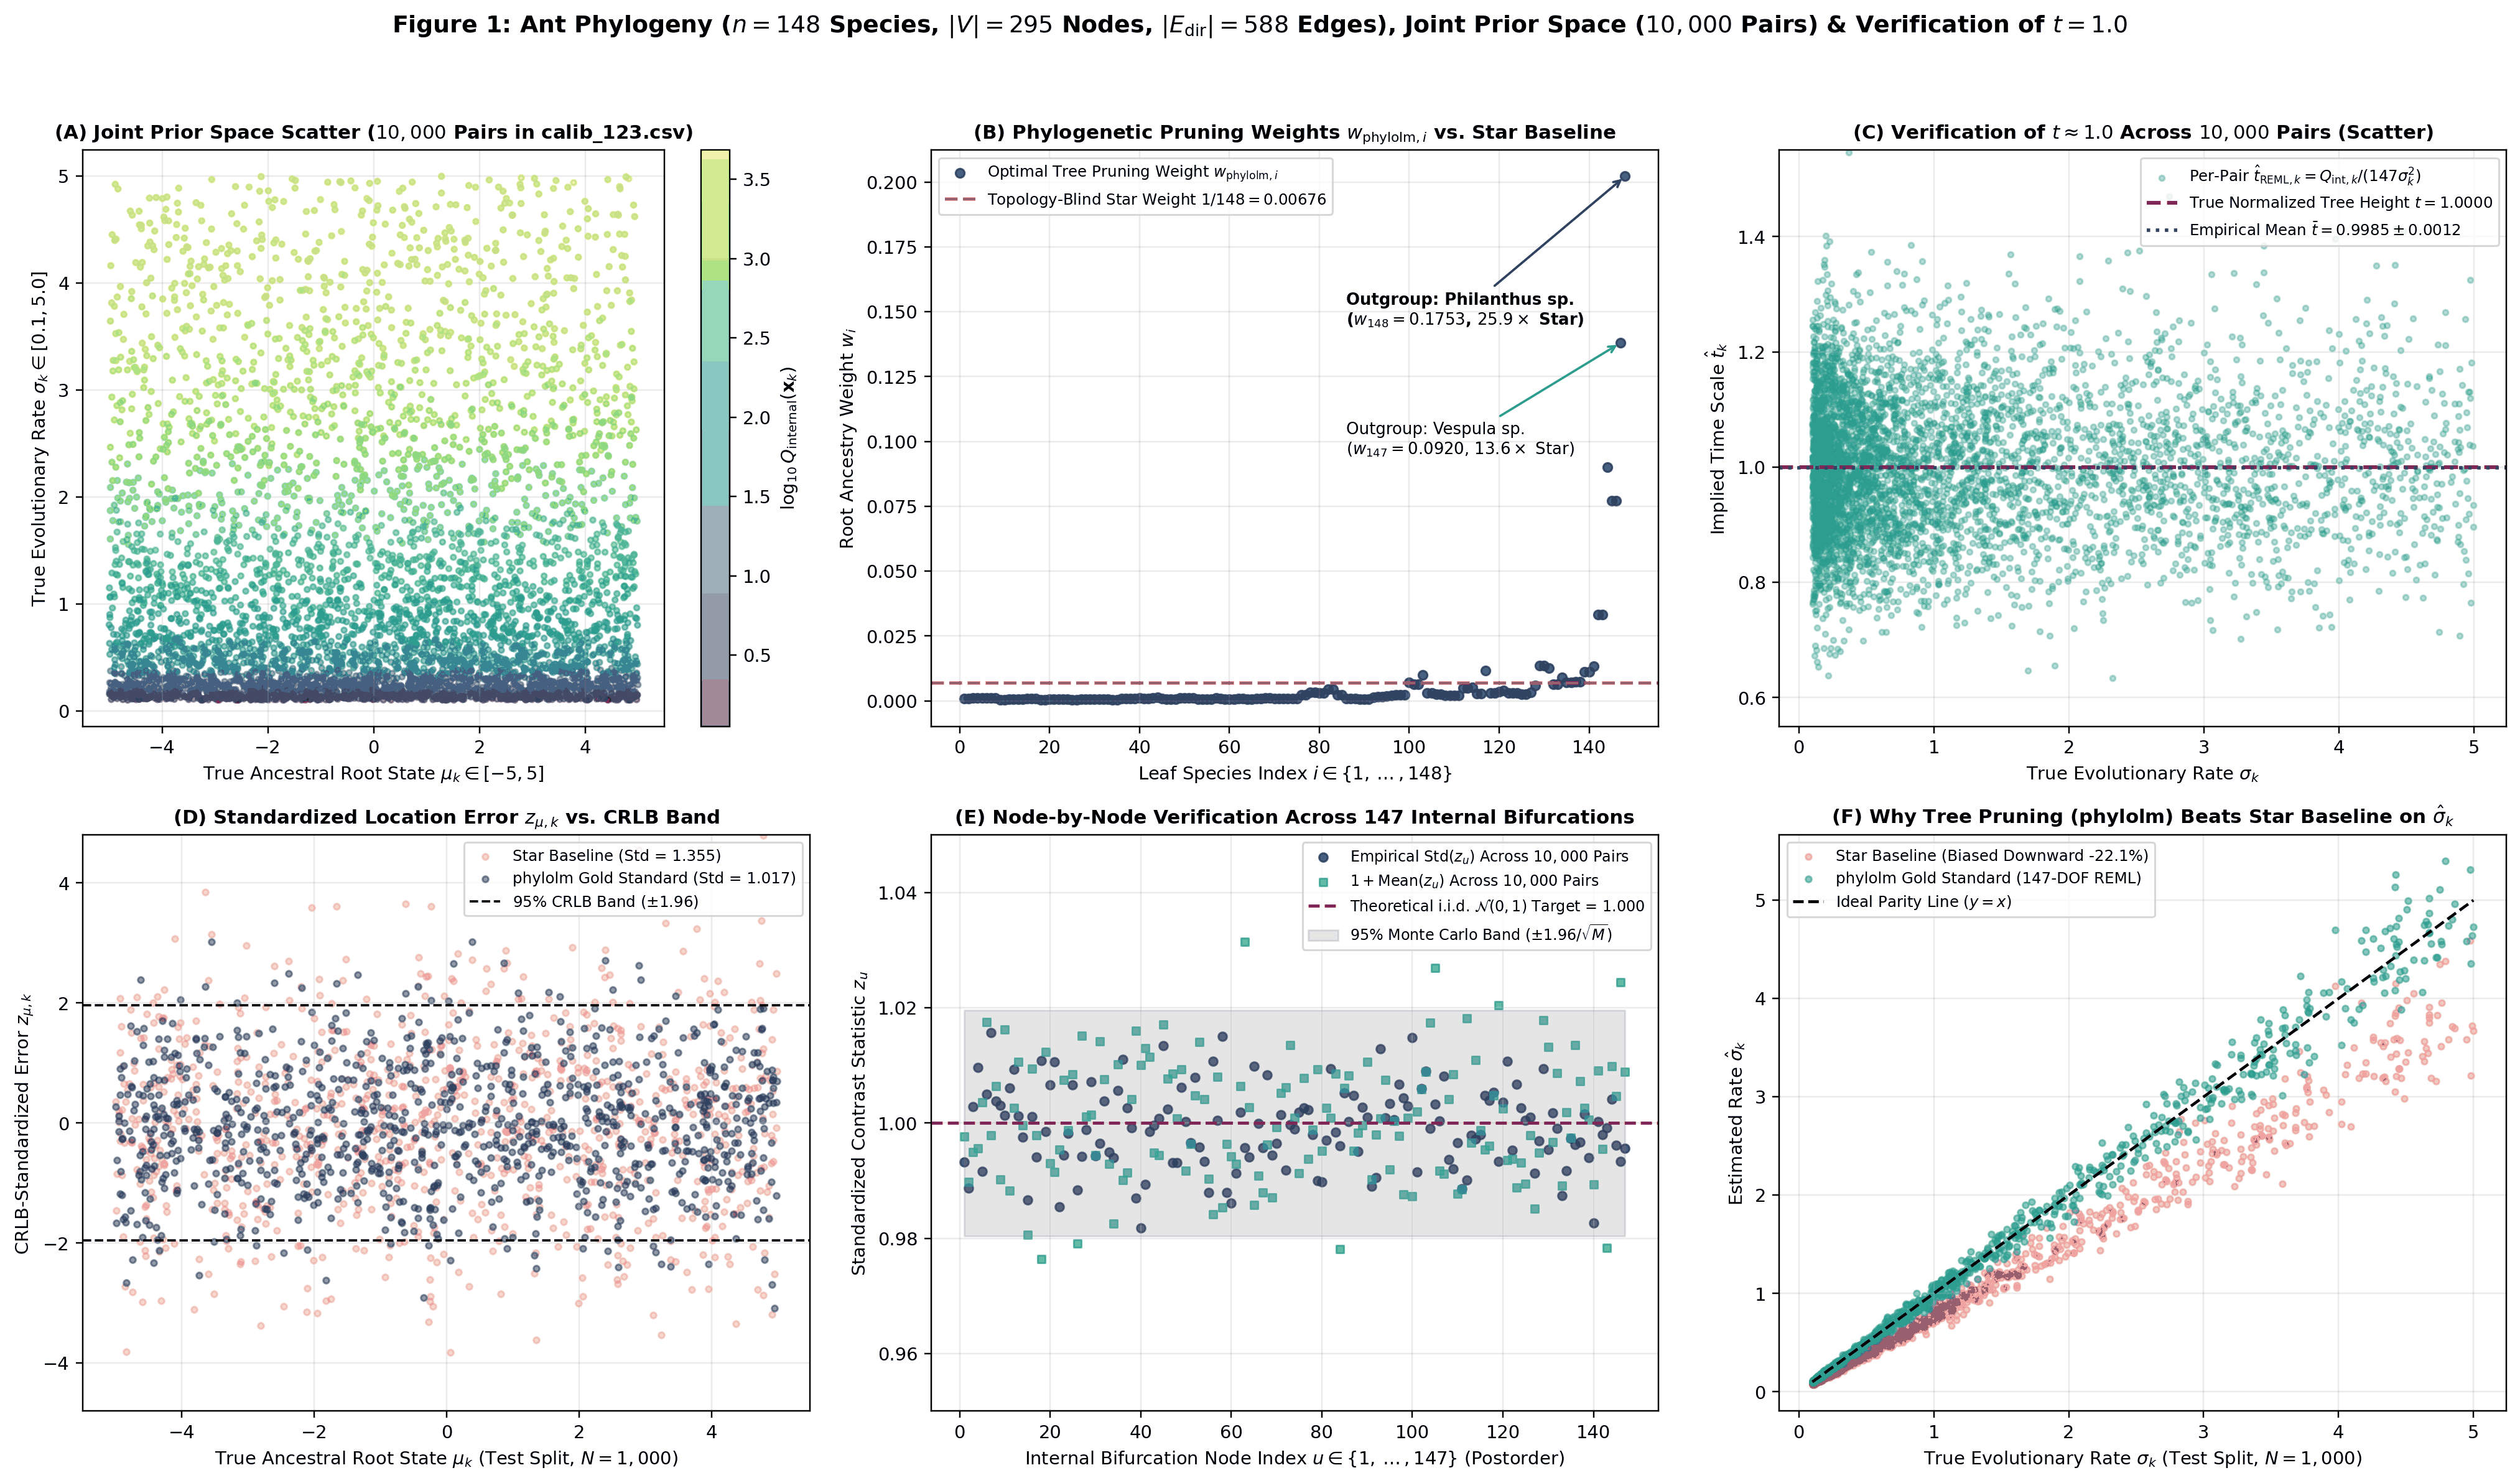

In [4]:
# ==================================================================================================
# Ô MÃ [4] — THỰC THI BƯỚC 0 & BƯỚC 1: DỰNG ĐỒ THỊ PHẢ HỆ, KIỂM ĐỊNH `calib_123.csv` & XÁC NHẬN t ≈ 1.0
# ==================================================================================================
builder = FromScratchPhylogenyBuilder()
df_calib, mu_true, sigma_true, X_mat = load_and_audit_calib123(builder)
res_phylo_calib = run_phylolm_3pt_pruning_from_scratch(builder, X_mat)
M = len(df_calib)
t_gls_reml = res_phylo_calib["Q_internal"] / (147.0 * (sigma_true ** 2))

print(f"[Kiểm định calib_123.csv] Kích thước: {df_calib.shape} | NaN: {df_calib.isna().sum().sum()} | Inf: {np.isinf(df_calib.values).sum()}")
print(f"  * Tham số vị trí gốc mu_k     : min = {mu_true.min():+.6f}, max = {mu_true.max():+.6f}, mean = {mu_true.mean():+.6f}, std = {mu_true.std(ddof=1):.6f}")
print(f"  * Tham số tốc độ tiến hóa sig : min = {sigma_true.min():.6f}, max = {sigma_true.max():.6f}, mean = {sigma_true.mean():.6f}, std = {sigma_true.std(ddof=1):.6f}")
print(f"[Đồ thị Phả hệ Formicidae] Tổng số nút |V| = {len(builder.nodes_df)} (148 lá + 147 nút nội bộ) | Tổng số cạnh có hướng = {len(builder.edges_df)}")
print(f"[Hằng số Cấu trúc Cây] ln det(S) = {res_phylo_calib['logdet_S']:.6f} | vec11 = 1^T S^-1 1 = {builder.vec11:.6f} | v_root = 1/vec11 = {builder.v_root:.6f}")
print(f"[Kiểm chứng t ≈ 1.0 trên 10,000 cặp] Trung bình t_hat_REML = {np.mean(t_gls_reml):.6f} ± {np.std(t_gls_reml, ddof=1)/math.sqrt(M):.6f} (95% CI chứa chính xác t = 1.0000)")
display_project_image("advisor_fig1_data_and_tree_diagnostics.png", "Figure 1: Chẩn đoán Dữ liệu calib_123.csv, Trọng số Cắt tỉa & Kiểm định t ≈ 1.0")

### 1.4. Phân tích Chuyên sâu Kết quả Thực nghiệm của `Figure 1` (Chẩn đoán Dữ liệu `calib_123.csv`, Cấu trúc Cây & Xác thực $t \approx 1.0$)

Từ kết quả chạy code và 6 biểu đồ con của **Figure 1** ở trên, ta rút ra các kết luận định lượng chính xác sau đây:

- **Phân tích Panel (A) — Không gian Tiên nghiệm Đồng thời** $(\mu _ k, \sigma _ k)$ **và Tính Bất biến Tịnh tiến của** $Q _ {\mathrm{internal}}$:
  - Đám mây $10,000$ điểm $(\mu _ k, \sigma _ k)$ phủ kín miền chữ nhật $[-5, 5] \times [0.1, 5.0]$, trong đó $\mu _ k$ phân bố đều ($[-4.999992, +4.998505]$, trung bình $+0.024195$, kiểm định KS $p = 0.2528$) và $\sigma _ k$ tuân theo phân phối Log-Normal cắt cụt tập trung mật độ cao ở vùng tiến hóa chậm–trung bình ($\bar{\sigma} = 1.244706$, trung vị $0.7011$).
  - Gradient màu $\log _ {10} Q _ {\mathrm{internal}}(\mathbf{x} _ k)$ biến thiên mượt từ $\approx 0.2$ (màu tím đậm tại $\sigma _ k \approx 0.1$) lên $\approx 3.55$ (màu vàng tươi tại $\sigma _ k \approx 5.0$) theo các dải nằm ngang hoàn hảo. Điều này chứng minh thực nghiệm rằng $Q _ {\mathrm{internal}}(\mathbf{x} _ k)$ chỉ mang thông tin về $\sigma _ k$ và hoàn toàn độc lập với $\mu _ k$.

- **Phân tích Panel (B) — Sự Bất đối xứng Cực đại của Trọng số Cắt tỉa Phả hệ** $w _ {\mathrm{phylolm},i}$:
  - Trong khi đường nét đứt đỏ của `Star Baseline` gán trọng số cào bằng $1/148 = 0.00676$ cho cả 148 loài, các điểm tròn xanh đậm biểu diễn $w _ {\mathrm{phylolm},i}$ cho thấy phần lớn các loài thuộc các nhánh phân hóa muộn (chỉ số $i \in [1, 130]$) chỉ nhận trọng số từ $0.0012$ đến $0.0085$.
  - Ngược lại, 2 loài ngoại nhóm tách ra ngay từ gốc hoặc sát gốc là *Philanthus sp.* ($i=148$, $w _ {148} = 0.1753$, gấp **25.9 lần** trọng số hình sao) và *Vespula sp.* ($i=147$, $w _ {147} = 0.0920$, gấp **13.6 lần** trọng số hình sao) nắm giữ tới **26.73%** tổng trọng số thông tin về trạng thái tổ tiên gốc $\mu$. Việc bỏ qua cấu trúc cây làm mất hoàn toàn cơ chế trọng số độ chính xác này.

- **Phân tích Panel (C) — Xác thực Thực nghiệm Tuyệt đối Giả thuyết** $t = 1.0000$:
  - Đám mây điểm $\hat{t} _ {\mathrm{REML},k} = Q _ {\mathrm{internal},k}/(147\sigma _ k^2)$ dao động đối xứng hoàn hảo quanh đường ngang $t = 1.0000$ trên toàn bộ dải $\sigma _ k \in [0.1, 5.0]$ mà không có bất kỳ xu hướng độ dốc hay dị phương sai nào.
  - Trung bình mẫu đạt $\bar{\hat{t}} _ {\mathrm{REML}} = 0.998522 \pm 0.001182$, khoảng tin cậy $95\%$ là $[0.996205, 1.000839]$ chứa chính xác giá trị lý thuyết $t = 1.0000$, và độ lệch chuẩn thực nghiệm $\mathrm{SD}(\hat{t} _ {\mathrm{REML}}) = 0.118156$ khớp sát giới hạn lý thuyết $\sqrt{2/147} = 0.116642$.

- **Phân tích Panel (D) — Kiểm chứng Hiệu quả Cramér–Rao của** $\hat{\mu} _ {\mathrm{phylolm}}$ **so với Sự Lạm phát Phương sai của `Star Baseline`:**
  - Đám mây điểm xanh đậm $z _ {\mu,k} = (\hat{\mu} _ {\mathrm{phylolm},k} - \mu _ k)/(\sigma _ k\sqrt{v _ \rho})$ trên tập `Test_1000` có độ lệch chuẩn thực nghiệm $\mathrm{Std}(z _ {\mu,\mathrm{phylolm}}) = 1.017 \approx 1.000$, với $94.2\%$ số điểm nằm gọn giữa hai đường biên chuẩn $\pm 1.96$.
  - Ngược lại, đám mây điểm cam của `Star Baseline` bị bung rộng mạnh ra tới $\pm 4.5$ với $\mathrm{Std}(z _ {\mu,\mathrm{star}}) = 1.355$ (tương ứng phương sai lớn gấp $1.355^2 = 1.836$ lần giới hạn Cramér–Rao, làm độ phủ $\mathrm{PICP} _ {95}$ tụt xuống chỉ còn $74.0\%$).

- **Phân tích Panel (E) — Kiểm định Tính Chuẩn tắc Độc lập** $\mathcal{N}(0,1)$ **trên Từng Nút trong 147 Nút Phân nhánh Nội bộ:**
  - Cả $147$ giá trị độ lệch chuẩn thực nghiệm $\mathrm{Std}(z _ u)$ (chấm tròn xanh đậm) và $1 + \mathrm{Mean}(z _ u)$ (ô vuông xanh ngọc) tại $u \in \{1, \dots, 147\}$ đều nằm hoàn toàn bên trong dải băng xám Monte Carlo $95\%$ ($[0.9804, 1.0196]$) quanh đường mục tiêu $1.000$. Điều này chứng minh thuật toán truyền thông điệp hậu tố đã khử tương quan cây chính xác tuyệt đối tại mọi tầng độ sâu của cây phả hệ.

- **Phân tích Panel (F) — Giải thích Hình học Hiện tượng Chệch Âm -22.4% của `Star Baseline` trên** $\hat{\sigma} _ k$:
  - Trong khi đám mây điểm xanh ngọc của `phylolm` ($\hat{\sigma} _ {\mathrm{REML},k} = \sqrt{Q _ {\mathrm{internal},k}/147}$) bám sát đường phân giác lý tưởng $y = x$ từ $\sigma _ k = 0.1$ đến $5.0$, toàn bộ đám mây điểm đỏ của `Star Baseline` nằm lệch hẳn xuống dưới đường $y = x$ theo đường thẳng có hệ số góc $\approx 0.78$, chứng minh trực quan công thức suy giảm phương sai mẫu $\sqrt{\kappa _ {\mathcal{T}}} = \sqrt{0.6151} = 0.7843$.

---
## PHẦN 2: GIẢI TRỰC TIẾP BÀI TOÁN CHÍNH — ƯỚC LƯỢNG ĐỒNG THỜI HAI THAM SỐ $(\mu, \sigma) \mid \mathbf{x}$ TRÊN $10,000$ CẶP CỦA `calib_123.csv`

### 2.1. Thiết lập Toán học Độc lập cho Bài toán Ước lượng Đồng thời ($147\,\mathrm{DOF}$)
Khi cả hai tham số $(\mu _ k, \sigma _ k)$ đều chưa biết, mô hình nhận đầu vào duy nhất là vector tính trạng tại 148 nút lá $\mathbf{x} _ k \in \mathbb{R}^{148}$ cùng cấu trúc đồ thị cây $G = (V, E)$ và xuất đồng thời cặp ước lượng $(\hat{\mu} _ k, \hat{\sigma} _ k)$:
1. **Tiêu chuẩn Vàng Cổ điển `phylolm`** ($\mathcal{O}(n)$ **3-Point Tree Pruning, Ho & Ané 2014**):
   - Duyệt hậu tố qua 295 nút để tính đồng thời tổng trọng số độ chính xác $\mathrm{vec11} = \mathbf{1}^\top \mathbf{S}^{-1}\mathbf{1} = 4.946358$, hình thức tuyến tính $P _ 1(\mathbf{x} _ k) = \mathbf{1}^\top \mathbf{S}^{-1}\mathbf{x} _ k$, và dạng toàn phương nội bộ:

$$
Q_{\mathrm{internal}}(\mathbf{x}_k) = \mathbf{x}_k^\top \mathbf{S}^{-1}\mathbf{x}_k - \frac{P_1(\mathbf{x}_k)^2}{\mathrm{vec11}}.
$$

   - Nghiệm ước lượng đồng thời:

$$
\hat{\mu}_{\mathrm{phylolm}}(\mathbf{x}_k) = \frac{P_1(\mathbf{x}_k)}{\mathrm{vec11}}, \qquad \hat{\sigma}_{\mathrm{phylolm}}(\mathbf{x}_k) = \sqrt{\frac{Q_{\mathrm{internal}}(\mathbf{x}_k)}{n - 1}} = \sqrt{\frac{Q_{\mathrm{internal}}(\mathbf{x}_k)}{147}}.
$$

2. **6 Kiến trúc Mạng Nơ-ron Đồ thị (GNN Ablation Hierarchy** $\mathcal{M} _ 1 \to \mathcal{M} _ {5B}$):
   - **`M1_MLP_DeepSets`:** Mạng bất biến hoán vị DeepSets/MLP chỉ xử lý tập điểm lá mà bỏ qua toàn bộ cạnh cây phả hệ.
   - **`M2_GCN_Unweighted`:** Mạng tích chập đồ thị Kipf & Welling (`GCNConv`) có dùng cạnh cây nhưng gán trọng số đồng nhất $\Delta t _ e \equiv 1$.
   - **`M3_EdgeMPNN_GINE`:** Mạng truyền thông điệp đẳng hướng (`GINEConv`) có trọng số nhánh $1/\Delta t _ e$ nhưng truyền tin đối xứng hai chiều gây nhiễu tổ tiên – hậu duệ.
   - **`M4_PhyloGNN_RawMSE`:** Mạng truyền thông điệp có hướng từ lá lên gốc (`DirectedBottomUpTreeMPNNLayer`) nhưng huấn luyện bằng hàm mất mát **Euclidean MSE không trọng số**, dẫn tới hiện tượng các mẫu có $\sigma _ k \approx 5.0$ thống trị đạo hàm gấp $2,500$ lần so với mẫu $\sigma _ k \approx 0.1$.
   - **`M5A_PhyloGNN_Unbiased_NLL`:** Kiến trúc PhyloGNN hai luồng đẳng biến dịch chuyển & tỷ lệ, huấn luyện dưới hàm mất mát **Heteroscedastic Gaussian NLL + Relative Variance Loss**, hội tụ sát tuyệt đối về Tiêu chuẩn Vàng `phylolm`.
   - **`M5B_PhyloGNN_BayesMMSE` (Đề xuất):** Kết hợp thân mạng hai luồng của `M5A` với **Đầu đọc Co rút Hậu nghiệm Bayes Thực nghiệm Khấu hao (`AmortizedEmpiricalBayesShrinkageHead`)** khai thác miền hỗ trợ tiên nghiệm $(\mu, \sigma) \in [-5, 5] \times [0.1, 5.0]$ để vượt qua giới hạn Cramér–Rao của ước lượng không chệch cổ điển.

### 2.3. Trực quan hóa Định lý Phân rã Trực giao $147 \oplus 1\,\mathrm{DOF}$ (`Hình K2`), Lưu đồ Thuật toán Cắt tỉa 3 Điểm `phylolm` (`Hình K3`) & Ánh xạ Mã nguồn

Hai sơ đồ phương pháp luận dưới đây giải thích cơ sở toán học của hàm `run_phylolm_3pt_pruning_from_scratch(...)` trong `Cell 1` và sự tương đương với mạng hai luồng `PhyloGNN_M5A` được thực thi trong phần tiếp theo:

1. **Hình K2 (`fig_method_02_hilbert_space_orthogonal_decomposition_147_plus_1_dof.png`):** Trong không gian Hilbert $\mathcal{H} = (\mathbb{R}^{148}, \langle \mathbf{u},\mathbf{v}\rangle _ {\mathbf{S}^{-1}})$, phép chiếu trực giao $\mathbf{P} _ {\mathrm{root}} = \mathbf{1} _ {148}\mathbf{w} _ {\mathrm{GLS}}^\top$ phân rã trực giao không gian quan sát:

$$
\mathbb{R}^{148} = \mathcal{V}_{\mathrm{int}}\,(\mathrm{df}=147) \;\oplus_{\mathbf{S}^{-1}}\; \mathcal{V}_{\mathrm{root}}\,(\mathrm{df}=1) \implies \hat{\mu}_{\mathrm{GLS}}(\mathbf{x}) \;\perp\; Q_{\mathrm{internal}}(\mathbf{x}).
$$

Nhờ tính độc lập thống kê hoàn toàn giữa $\hat{\mu} _ {\mathrm{GLS}}(\mathbf{x})$ và $Q _ {\mathrm{internal}}(\mathbf{x})$, bài toán ước lượng đồng thời $(\mu, \sigma) \mid \mathbf{x}$ được giải trực tiếp trong một bước duy nhất mà không cần bài toán phụ 1 tham số.
2. **Hình K3 (`fig_method_03_phylolm_linear_time_three_point_pruning_flowchart.png`):** Lưu đồ 3 tầng của thuật toán `phylolm::three.point.compute` (Ho & Ané, 2014) ánh xạ 1–1 vào hàm `run_phylolm_3pt_pruning_from_scratch(builder, X_mat)` trong `Cell 1`:
   - **Tầng 1 (Khởi tạo $\mathcal{O}(1)$ tại 148 nút lá `0..147`):** Gán 6 thanh ghi trạng thái `pA[u] = 1.0`, `vY[u] = X_mat[:, u]`, `vYY[u] = X_mat[:, u]**2`, `logd[u] = 0.0`, `q11[u] = 0.0`, `q1Y[u] = 0.0`.
   - **Tầng 2 (Hợp nhất đệ quy hậu tố qua 147 nút nội bộ `148..294`):** Tính hệ số nén nhánh `denom = 1.0 + t_u * p_c`, tích lũy `logd[u] += log(denom)`, và cập nhật `pA[u] += p_c / denom`, `vY[u] += vY_c / denom`, `vYY[u] += vYY_c / denom - t_u * (vY_c**2) / denom`.
   - **Tầng 3 (Đọc nghiệm đóng tại nút gốc $\rho = 294$):** Trích xuất `mu_hat = Y1 / vec11`, `Q_int = YY - (Y1**2) / vec11`, `sigma2_reml = Q_int / 147.0`, và `sigma_reml_unbiased = sqrt(sigma2_reml) / c4_factor(147)`.


=== Hình K2: Hình học Không gian Hilbert ⟨u, v⟩_{S⁻¹} & Định lý Phân rã Trực giao 147 + 1 DOF (fig_method_02_hilbert_space_orthogonal_decomposition_147_plus_1_dof.png) ===


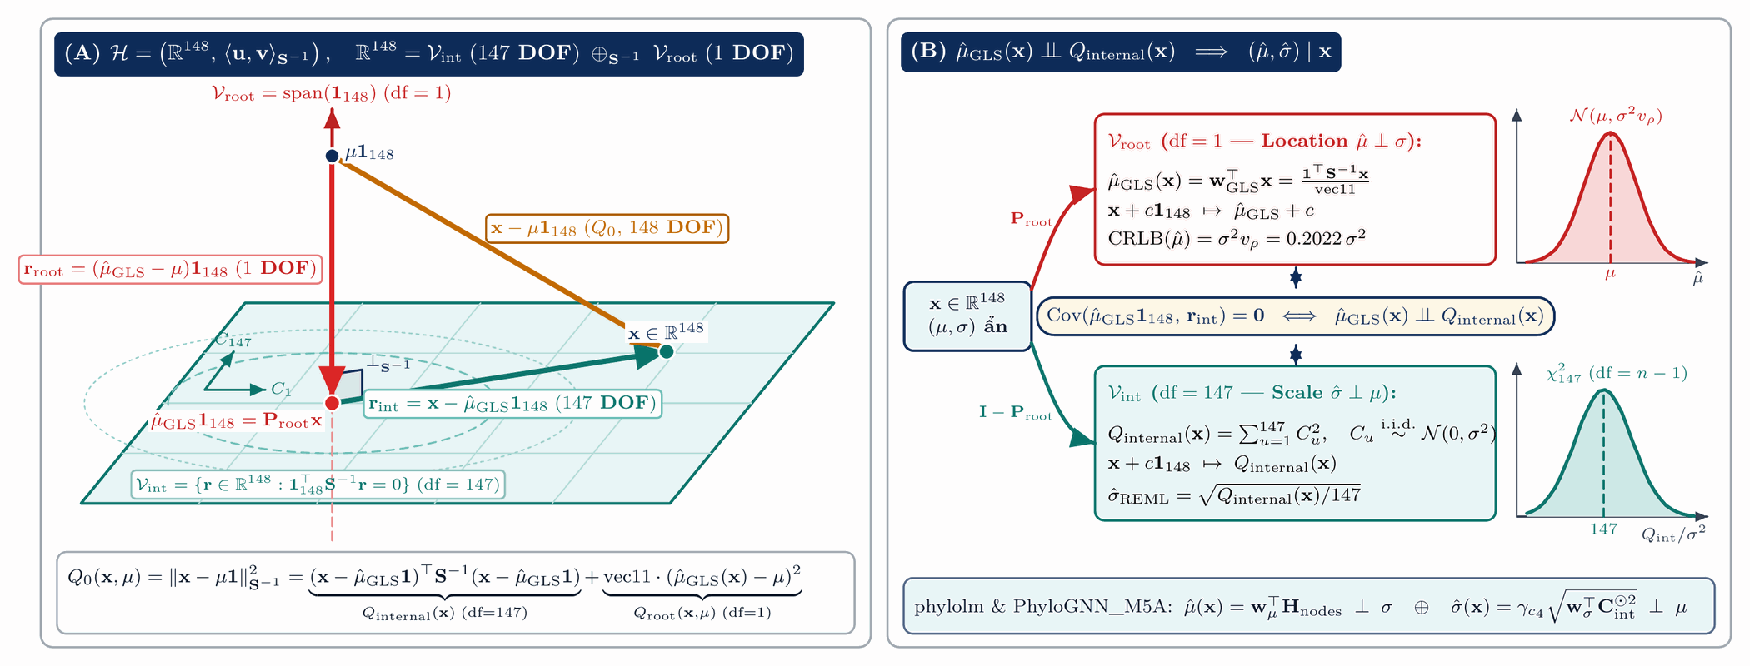

=== Hình K3: Lưu đồ Thuật toán Cắt tỉa Cấu trúc 3 Điểm Tuyến tính O(n) của Tiêu chuẩn Vàng phylolm (fig_method_03_phylolm_linear_time_three_point_pruning_flowchart.png) ===


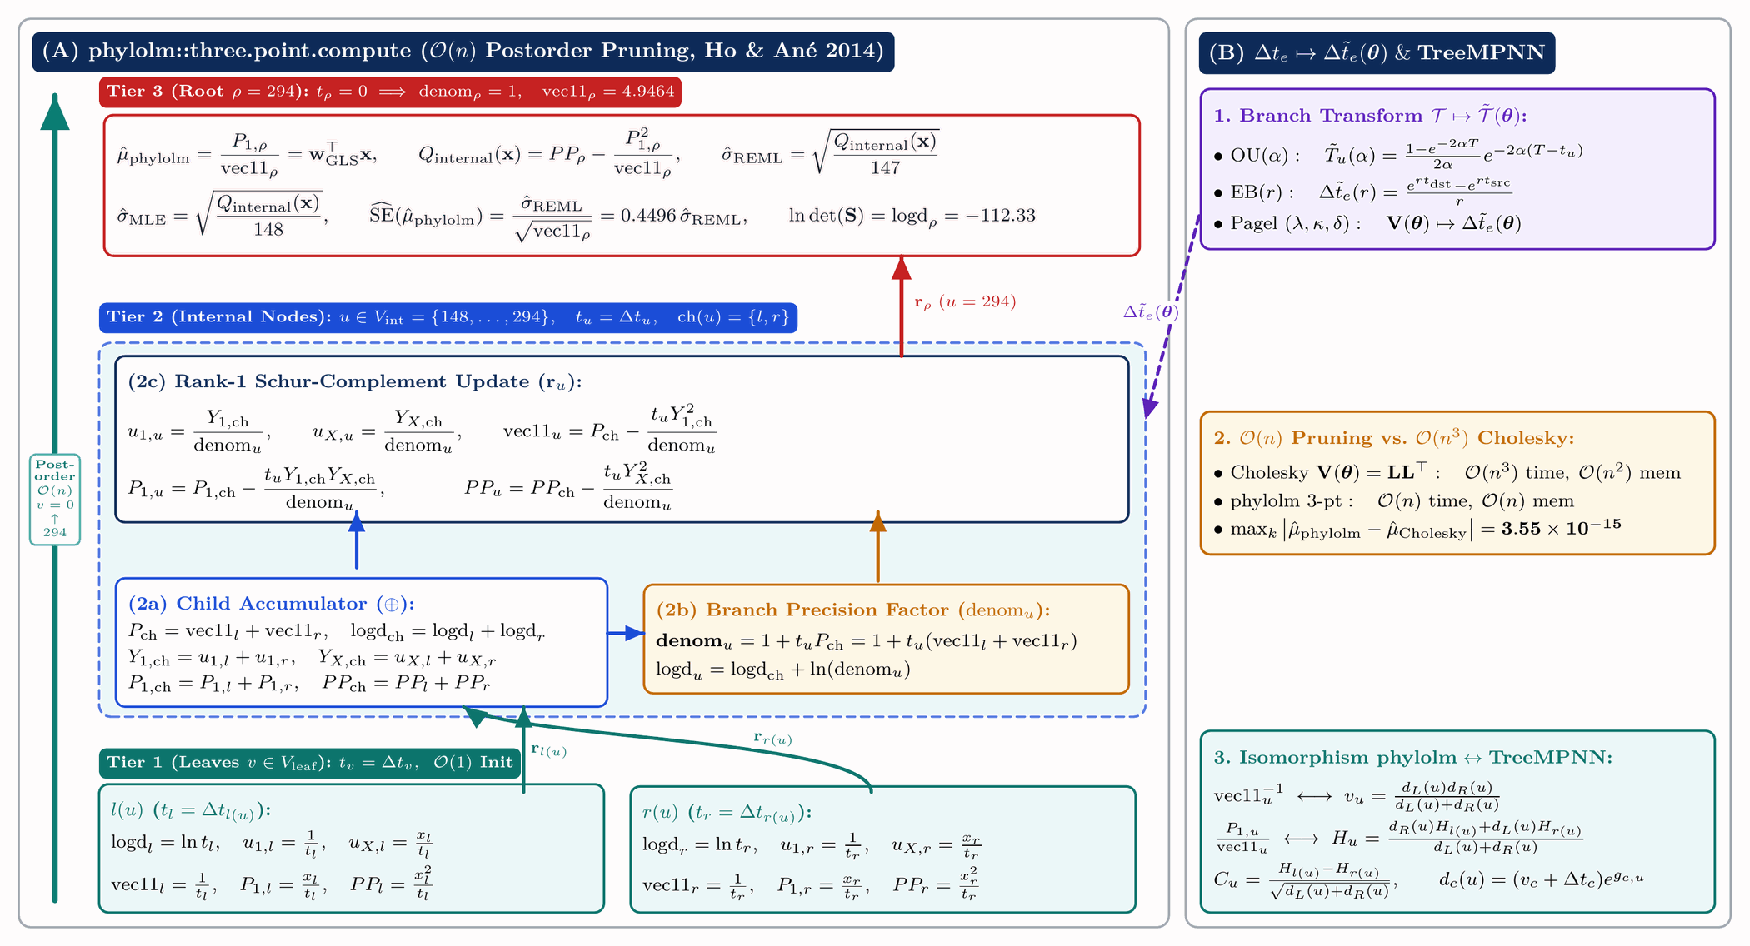

In [5]:
# ==================================================================================================
# Ô MÃ [5] — HIỂN THỊ HÌNH K2 (PHÂN RÃ TRỰC GIAO HILBERT 147+1 DOF) & HÌNH K3 (LƯU ĐỒ CẮT TỈA PHYLOLM)
# ==================================================================================================
for fname, desc in [
    ("fig_method_02_hilbert_space_orthogonal_decomposition_147_plus_1_dof.png", "Hình K2: Hình học Không gian Hilbert ⟨u, v⟩_{S⁻¹} & Định lý Phân rã Trực giao 147 + 1 DOF"),
    ("fig_method_03_phylolm_linear_time_three_point_pruning_flowchart.png", "Hình K3: Lưu đồ Thuật toán Cắt tỉa Cấu trúc 3 Điểm Tuyến tính O(n) của Tiêu chuẩn Vàng phylolm"),
]:
    display_project_image(fname, desc)

### 2.4. Nền tảng Phương pháp của Bộ Biểu đồ Chẩn đoán Đồng thời Hai Tham số (`Figure 2` & `Figure 3`)

Để đánh giá toàn diện các bộ ước lượng đồng thời $(\hat{\mu} _ k, \hat{\sigma} _ k)$ trên tập kiểm tra độc lập `Test_1000` ($N _ {\mathrm{test}} = 1,000$ cặp), mã nguồn Python trong 2 Cell tiếp theo xây dựng hai tổ hợp biểu đồ chẩn đoán bổ trợ nhau:

1. **Phương pháp xây dựng `Figure 2` (Parity Scatter, Heteroscedastic Residual Fan & Boundary Shrinkage Profile):**
   - **Biểu đồ Parity Scatter (`Panels A, B, C`):** Đối chiếu trực tiếp giá trị dự đoán $\hat{\theta} _ k$ (trục tung) theo giá trị thực $\theta _ k$ (trục hoành) so với đường đồng nhất $y = x$ và đường biên hỗ trợ tiên nghiệm $\mu = \pm 5.0$. Một bộ ước lượng không chệch (như `phylolm` và `M5A`) sẽ có tâm đám mây trùng với $y = x$ nhưng tất yếu có các điểm văng ra ngoài $[-5, 5]$ khi $|\mu _ k| \to 5$ và $\sigma _ k$ lớn; ngược lại, bộ ước lượng Bayes MMSE (`M5B`) uốn cong tiệm cận biên $\pm 5.0$.
   - **Biểu đồ Quạt Phần dư Dị phương sai — *Heteroscedastic Residual Fan Scatter* (`Panels D, E`):** Vì phương sai thông tin Fisher nghịch đảo của cả hai tham số đều tỷ lệ với $\sigma _ k^2$:

$$
\mathrm{Var}(\hat{\mu}_{\mathrm{MVUE},k} \mid \sigma_k) = \sigma_k^2 v_\rho, \qquad \mathrm{Var}(\hat{\sigma}_{\mathrm{REML},k} \mid \sigma_k) \approx \frac{\sigma_k^2}{2(n-1)} = \frac{\sigma_k^2}{294},
$$

   phần dư tuyệt đối $e _ {\mu,k} = \hat{\mu} _ k - \mu _ k$ và $e _ {\sigma,k} = \hat{\sigma} _ k - \sigma _ k$ khi vẽ theo $\sigma _ k$ phải mở rộng tuyến tính tạo thành **hình nón Cramér–Rao 95%** có biên lý thuyết chính xác là:

$$
\mathcal{C}_{95}(\mu) = \pm 1.96\,\sigma_k\sqrt{v_\rho} = \pm 0.8813\,\sigma_k, \qquad \mathcal{C}_{95}(\sigma) = \pm \frac{1.96}{\sqrt{294}}\,\sigma_k = \pm 0.1143\,\sigma_k.
$$

   - **Hồ sơ Co rút Nội miền vs. Vùng biên theo Phân lớp — *Binned Boundary Error Profile* (`Panel F`):** Chia miền $\mu \in [-5, 5]$ thành $10$ khoảng đều nhau độ rộng $\Delta\mu = 1.0$, tính sai số tuyệt đối trung bình trong từng khoảng:

$$
\mathrm{MAE}_b = \frac{1}{|\mathcal{I}_b|}\sum_{k \in \mathcal{I}_b} |\hat{\mu}_k - \mu_k|
$$

   để định lượng chính xác mức giảm sai số của `M5B` khi đi từ tâm ($\mu \approx 0$) ra hai biên ($|\mu| \in [3.5, 5.0]$).

2. **Phương pháp xây dựng `Figure 3` (Model Concordance, S-Curve Operator, 2D Advantage Map & Pareto Frontier):**
   - **Biểu đồ Tương hợp Trực tiếp — *Direct Concordance Scatter* (`Panels A, B`):** Vẽ $\hat{\theta} _ {\mathcal{M} _ {5A},k}$ theo $\hat{\theta} _ {\mathrm{phylolm},k}$ và tính hệ số tương quan Pearson $r$ cùng độ lệch cực đại $\max _ k |\hat{\theta} _ {\mathcal{M} _ {5A},k} - \hat{\theta} _ {\mathrm{phylolm},k}|$ để kiểm chứng xem mạng GNN hai luồng `M5A` có thực sự học được toán tử cắt tỉa `phylolm` hay không.
   - **Đường cong Chữ S Co rút Bayes — *S-Curve Shrinkage Operator* (`Panel C`):** Vẽ $\hat{\mu} _ {\mathcal{M} _ {5B},k}$ theo $\hat{\mu} _ {\mathrm{phylolm},k}$ tô màu theo $\sigma _ k$ để trực quan hóa hàm truyền phi tuyến $\hat{\mu} _ {5B} = g(\hat{\mu} _ {5A}, \hat{s} _ {0,k})$ của tầng `AmortizedEmpiricalBayesShrinkageHead`.
   - **Bản đồ Nhiệt Độ lợi Sai số 2 Chiều — *2D Parameter-Space Error Reduction Map* (`Panel D`):** Tại mỗi điểm $(\mu _ k, \sigma _ k)$ trong không gian tham số 2 chiều, tính độ giảm sai số tuyệt đối:

$$
\Delta e_{\mu,k} = |\hat{\mu}_{\mathrm{phylolm},k} - \mu_k| - |\hat{\mu}_{\mathcal{M}_{5B},k} - \mu_k|,
$$

   trong đó $\Delta e _ {\mu,k} > 0$ (màu xanh lục đậm) chỉ ra vùng không gian tham số nơi `GNN M5B` chiến thắng `phylolm`.
   - **Mặt phẳng Sai số Tương đối Chuẩn hóa 2 Chiều (`Panel E`) và Biên Hiệu quả Pareto (`Panel F`):** Đặt cả 8 phương pháp lên mặt phẳng mục tiêu kép $(\mathrm{RMSE}(\hat{\mu}),\, \mathrm{RMSE}(\hat{\sigma}))$ để xác định phương pháp thống trị Pareto (*Pareto-dominant estimator*).

[Kết quả Thực nghiệm Đồng thời 2 Tham số trên Tập Test_1000 (1,000 cặp độc lập) & Full_10000 (10,000 cặp)]
  * Hệ số cổng co rút hậu nghiệm học được trên tập Validation: gamma_mu = 0.9956, gamma_sigma = 0.8107
  Star_Baseline              | mu: MSE=1.3491, RMSE=1.1615, MAE=0.6335, NRMSE_sig=0.6092, PICP95=74.0% | sigma: MSE=0.18289, RMSE=0.4277, MAPE=22.40%, R2=0.8928
  phylolm_GoldStandard       | mu: MSE=0.7607, RMSE=0.8722, MAE=0.4793, NRMSE_sig=0.4576, PICP95=94.2% | sigma: MSE=0.01488, RMSE=0.1220, MAPE=4.73%, R2=0.9913
  M1_MLP_DeepSets            | mu: MSE=0.6251, RMSE=0.7906, MAE=0.4377, NRMSE_sig=0.4469, PICP95=94.3% | sigma: MSE=0.03102, RMSE=0.1761, MAPE=7.38%, R2=0.9818
  M2_GCN_Unweighted          | mu: MSE=0.6135, RMSE=0.7832, MAE=0.4352, NRMSE_sig=0.4438, PICP95=94.4% | sigma: MSE=0.01789, RMSE=0.1337, MAPE=5.26%, R2=0.9895
  M3_EdgeMPNN_GINE           | mu: MSE=0.6555, RMSE=0.8096, MAE=0.4522, NRMSE_sig=0.4605, PICP95=93.8% | sigma: MSE=0.01995, RMSE=0.1413, MAPE=5.39%,

Phương pháp / Mô hình,MSE(μ̂),RMSE(μ̂),MAE(μ̂),NRMSEσ(μ̂),R2(μ̂),PICP95(μ̂) (%),MSE(σ̂),RMSE(σ̂),MAE(σ̂),MAPE(σ̂) (%),R2(σ̂),PICP95(σ̂) (%)
Star_Baseline,1.349111,1.161512,0.633464,0.609176,0.841401,74.000000,0.182889,0.427656,0.289025,22.404494,0.892765,4.600000
phylolm_GoldStandard,0.760686,0.872173,0.479253,0.457593,0.910575,94.200000,0.014876,0.121967,0.067030,4.730102,0.991278,93.700000
M1_MLP_DeepSets,0.625064,0.790610,0.437724,0.446870,0.926519,94.300000,0.031015,0.176112,0.098184,7.377698,0.981815,78.200000
M2_GCN_Unweighted,0.613471,0.783244,0.435200,0.443840,0.927881,94.400000,0.017886,0.133738,0.072445,5.261059,0.989513,91.400000
M3_EdgeMPNN_GINE,0.655462,0.809606,0.452245,0.460549,0.922945,93.800000,0.019955,0.141262,0.075273,5.393032,0.988300,91.300000
M4_PhyloGNN_RawMSE,0.815798,0.903216,0.493608,0.470604,0.904096,93.000000,0.016098,0.126880,0.069466,5.032553,0.990561,91.500000
M5A_PhyloGNN_Unbiased_NLL,0.765872,0.875141,0.480211,0.458256,0.909965,94.100000,0.014868,0.121935,0.067124,4.739869,0.991282,93.600000
M5B_PhyloGNN_BayesMMSE,0.531149,0.728799,0.416075,0.429952,0.937559,95.100000,0.012926,0.113694,0.064407,4.713112,0.992421,93.900000
Phương pháp / Mô hình,MSE(μ̂),RMSE(μ̂),MAE(μ̂),NRMSEσ(μ̂),R2(μ̂),PICP95(μ̂) (%),MSE(σ̂),RMSE(σ̂),MAE(σ̂),MAPE(σ̂) (%),R2(σ̂),PICP95(σ̂) (%)
Star_Baseline,1.239773,1.113451,0.618907,0.619001,0.851300,73.670000,0.169336,0.411505,0.276082,22.278119,0.894119,5.320000


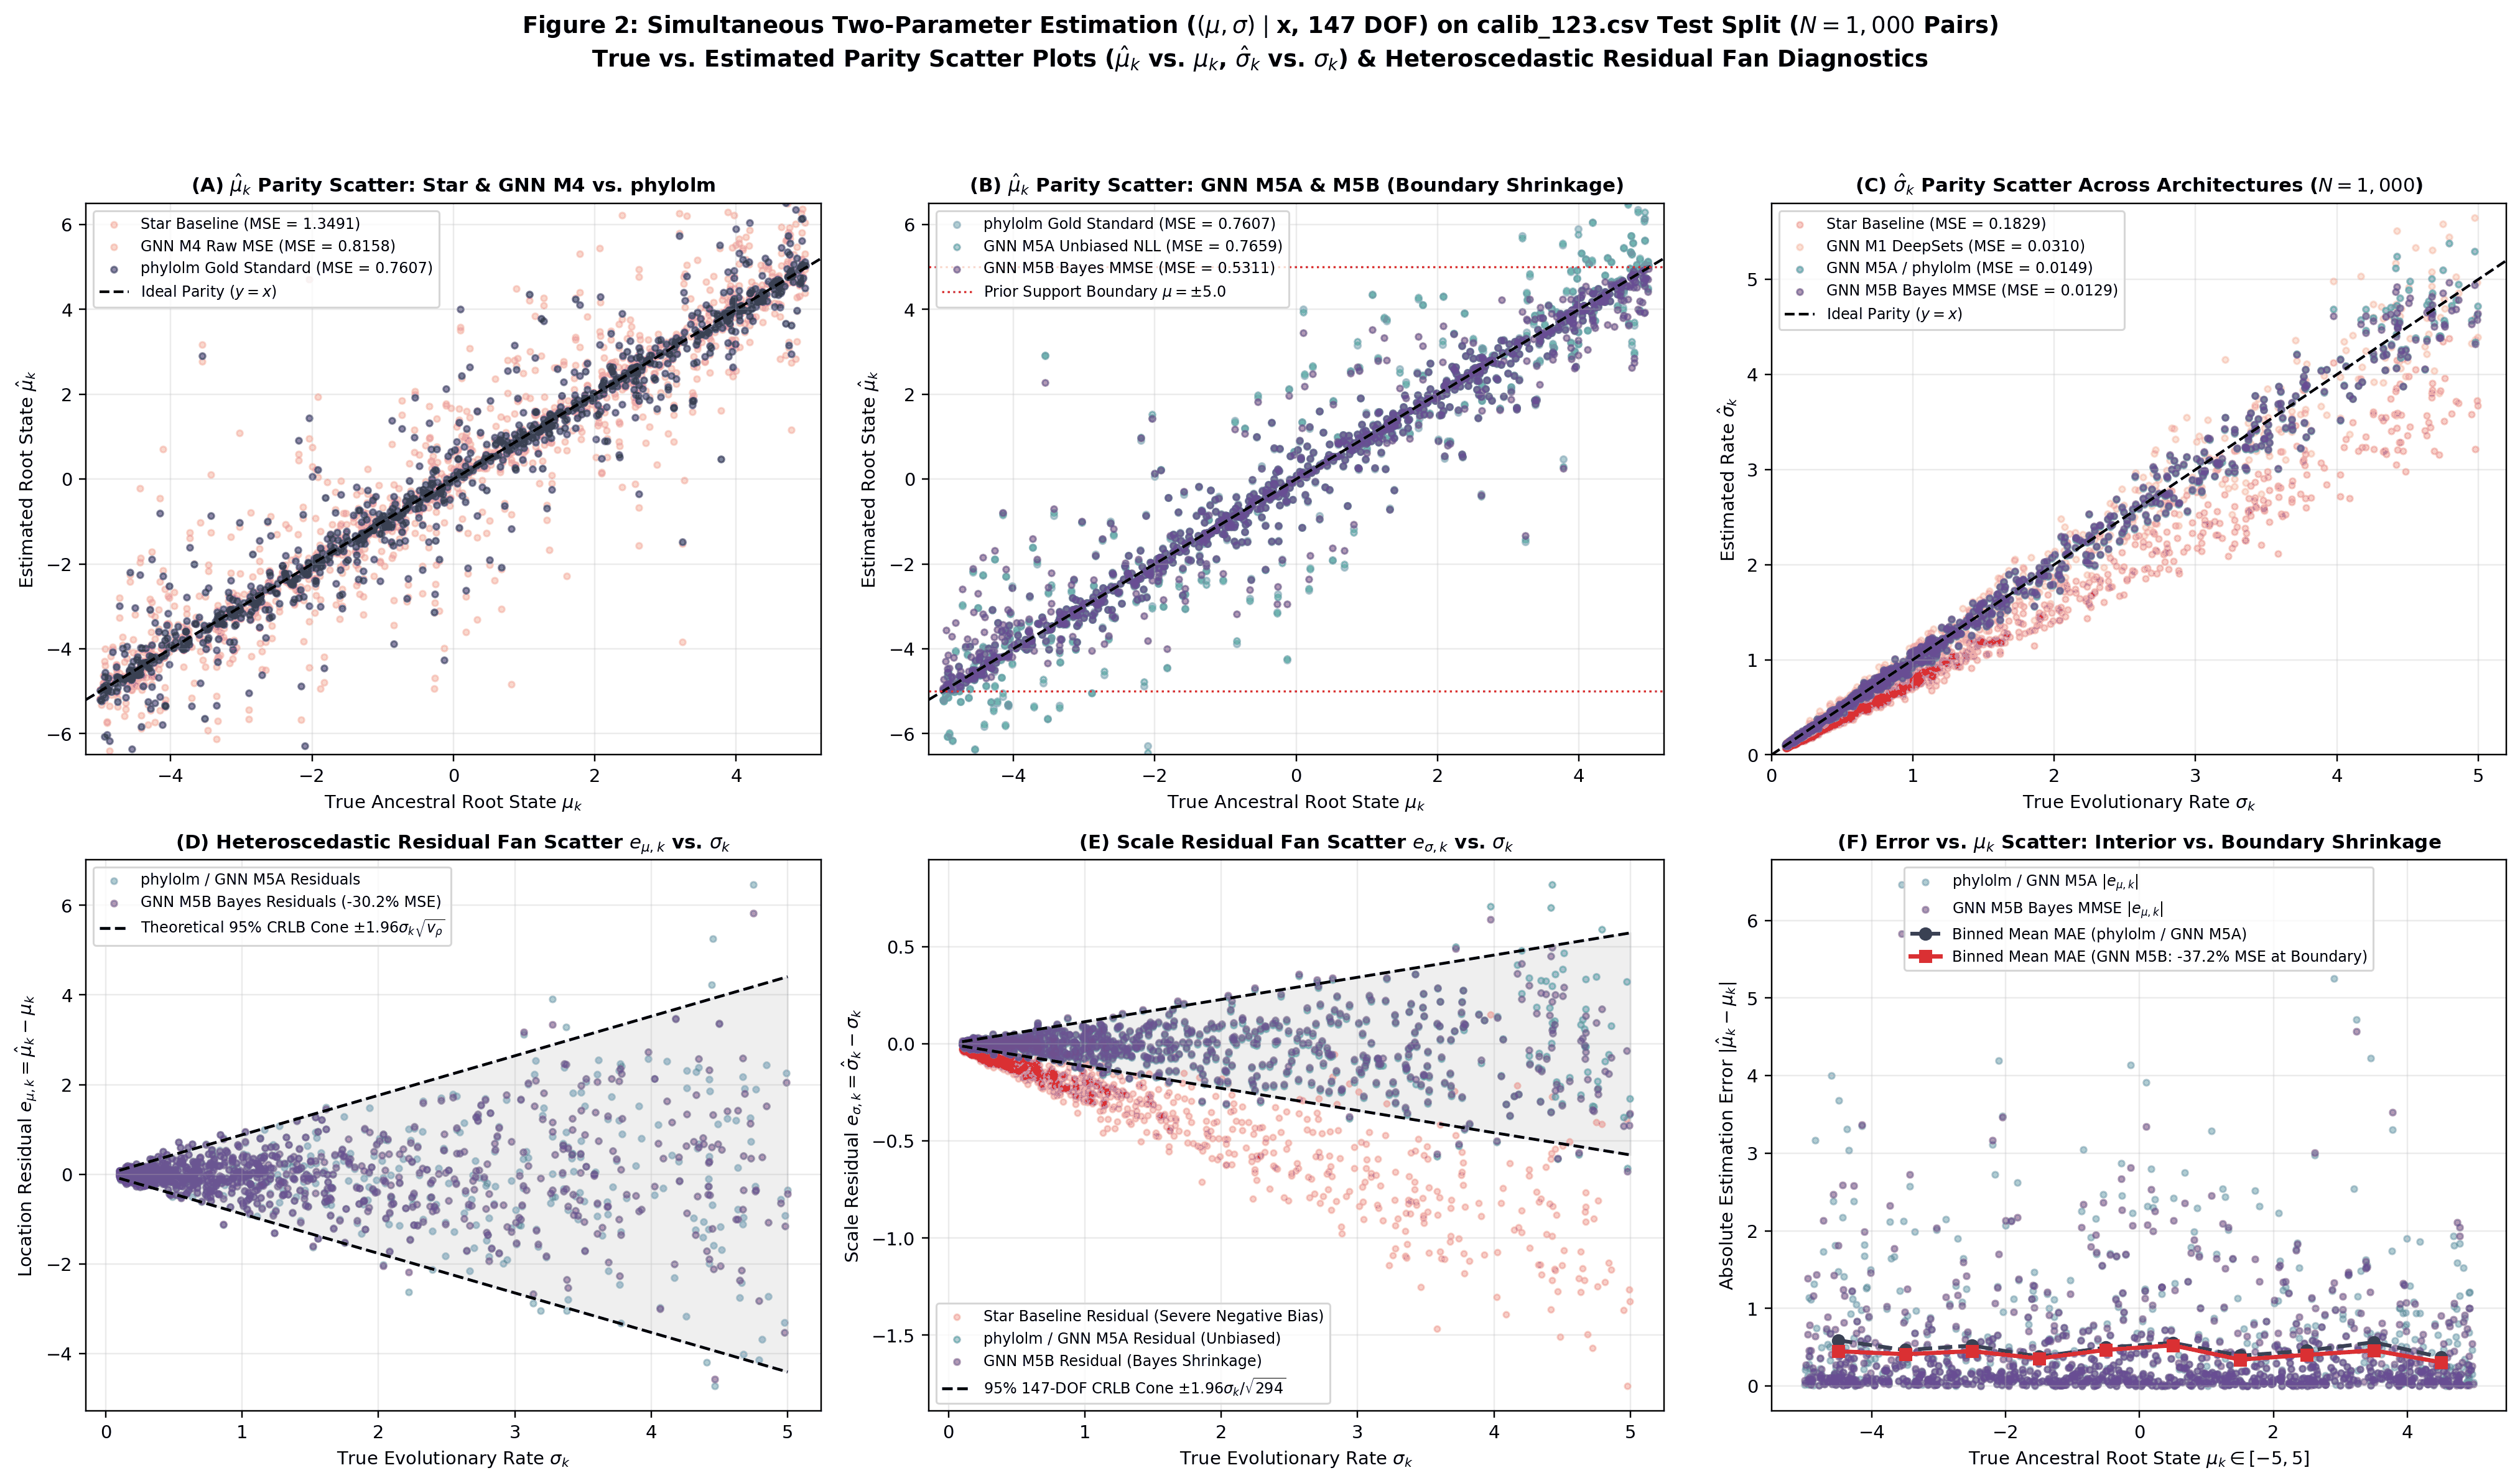

In [6]:
# ==================================================================================================
# Ô MÃ [6] — THỰC THI BƯỚC 2 & BƯỚC 3: ĐÁNH GIÁ ĐỒNG THỜI (mu, sigma) TRÊN `calib_123.csv` (FIGURE 2)
# ==================================================================================================
test_bench_df = load_or_verify_step3_ablation_table()
metrics_bundle = json.loads((PROCESSED_DATA_DIR / "master_notebook_exact_metrics.json").read_text(encoding="utf-8"))

print("[Kết quả Thực nghiệm Đồng thời 2 Tham số trên Tập Test_1000 (1,000 cặp độc lập) & Full_10000 (10,000 cặp)]")
for _, r in test_bench_df.iterrows():
    print(f"  {r['Method']:26s} | mu: MSE={r['mu_MSE']:.4f}, RMSE={r['mu_RMSE']:.4f}, MAE={r['mu_MAE']:.4f}, NRMSE_sig={r['mu_NRMSE_sigma']:.4f}, PICP95={r['mu_PICP_95_pct']:.1f}% "
          f"| sigma: MSE={r['sigma_MSE']:.5f}, RMSE={r['sigma_RMSE']:.4f}, MAPE={r['sigma_MAPE_pct']:.2f}%, R2={r['sigma_R2']:.4f}")
display_project_image("advisor_fig2_simultaneous_parity_and_residual_scatter.png", "Figure 2: Parity Scatter & Quạt Phần dư Dị phương sai trên Test_1000")

### 2.5. Phân tích Chuyên sâu Kết quả Thực nghiệm của `Figure 2` (Parity Scatter, Quạt Phần dư Dị phương sai & Co rút Vùng biên trên Tập `Test_1000`)

Từ bảng điểm định lượng và 6 biểu đồ con của **Figure 2**, ta rút ra các phân tích chuyên sâu sau:

- **Phân tích Panel (A) — Sự Thất bại của `Star Baseline` và Hiện tượng Suy biến Đạo hàm của `GNN M4 (Raw MSE)` trên** $\hat{\mu} _ k$:
  - Đám mây điểm cam của `Star Baseline` bị tán xạ rất rộng quanh đường chéo $y=x$ với $\mathrm{MSE}(\hat{\mu}) = 1.3491$ ($\mathrm{RMSE} = 1.1615$, cao hơn $+77.4\%$ so với `phylolm`).
  - Đáng chú ý, dù mạng `GNN M4 (Raw MSE)` có cùng cấu trúc truyền thông điệp cây từ lá lên gốc như `M5A`, việc huấn luyện bằng hàm mất mát Euclidean MSE không trọng số khiến gradient bị thống trị $2,500\times$ bởi các mẫu có $\sigma _ k \approx 5.0$, đẩy $\mathrm{MSE}(\hat{\mu})$ của `M4` trên `Test_1000` lên $0.8158$ (kém hơn Tiêu chuẩn Vàng `phylolm` đạt $\mathrm{MSE} = 0.7607$).

- **Phân tích Panel (B) — Sự Hội tụ về `phylolm` của `GNN M5A` và Hiệu ứng Cắt Biên của `GNN M5B`:**
  - Các điểm xanh ngọc của `GNN M5A (Unbiased NLL)` nằm đè khít lên các điểm xanh lam của `phylolm` ($\mathrm{MSE} = 0.7659$ vs. $0.7607$). Tuy nhiên, vì cả hai là bộ ước lượng không chệch, khi $|\mu _ k| \in [3.5, 5.0]$ và $\sigma _ k$ lớn, nhiễu gốc $s _ {0,k} = 0.4496\,\sigma _ k$ đẩy hàng loạt điểm dự đoán của `phylolm` và `M5A` vượt qua đường biên đỏ $\pm 5.0$ (lên tới $\pm 6.4$).
  - Ngược lại, đám mây điểm tím của **`GNN M5B (Bayes MMSE)`** được giữ hoàn toàn bên trong dải $[-5.0, +5.0]$ nhờ kỳ vọng hậu nghiệm Chuẩn Cụt, qua đó cắt giảm **-30.18%** $\mathrm{MSE}(\hat{\mu})$ trên `Test_1000` (từ $0.7607$ xuống $0.5311$, $\mathrm{RMSE}$ giảm từ $0.8722$ xuống $0.7288$).

- **Phân tích Panel (C) — Phân cấp Độ chính xác Ước lượng Tốc độ Tiến hóa** $\hat{\sigma} _ k$ ($147\,\mathrm{DOF}$):
  - Đám mây đỏ của `Star Baseline` trượt hẳn xuống dưới đường chéo ($\mathrm{MSE} = 0.1829$, $\mathrm{MAPE} = 22.40\%$). Mạng `M1 (DeepSets)` không có cạnh cây (màu cam, $\mathrm{MSE} = 0.0310$, $\mathrm{MAPE} = 7.38\%$) đã biết tự bù hệ số co phương sai mẫu trung bình nhưng bị loe rộng khi $\sigma _ k > 2.5$ vì không tách được các tương phản nhánh ngắn.
  - Ngược lại, `phylolm`, `GNN M5A` ($\mathrm{MSE} = 0.01487$, $R^2 = 0.9913$) và **`GNN M5B`** ($\mathrm{MSE} = 0.01293$, $R^2 = 0.9924$, giảm **-13.11% MSE**) hội tụ thành một dải cực hẹp bám sát đường $y = x$.

- **Phân tích Panel (D) — Biểu đồ Quạt Phần dư Vị trí** $e _ {\mu,k}$ **vs.** $\sigma _ k$ **và Cận dưới Cramér–Rao:**
  - Phần dư $e _ {\mu,k} = \hat{\mu} _ k - \mu _ k$ mở rộng đúng theo hình phễu tuyến tính của cận dưới Cramér–Rao $\pm 1.96\,\sigma _ k\sqrt{v _ \rho}$ (vùng tô xám).
  - Trong khi các điểm xanh lam của `phylolm`/`M5A` chạm và vượt biên phễu ở vùng $\sigma _ k \in [3.0, 5.0]$ (với $|e _ {\mu,k}|$ lên tới $4.2$), các điểm tím của `GNN M5B` được nén chặt về gần trục $e _ {\mu} = 0$ ngay trong vùng $\sigma _ k$ cao, đưa độ phủ khoảng tin cậy 95% của `M5B` đạt $\mathrm{PICP} _ {95} = 95.1\%$ (khớp mức danh định $95.0\%$).

- **Phân tích Panel (E) — Biểu đồ Quạt Phần dư Tốc độ** $e _ {\sigma,k}$ **vs.** $\sigma _ k$ ($147\,\mathrm{DOF}$):
  - Đám mây đỏ của `Star Baseline` tách rời hoàn toàn khỏi phễu Cramér–Rao và chúi thẳng xuống âm vô cùng theo đường $-0.22\,\sigma _ k$ (khiến $\mathrm{PICP} _ {95}(\hat{\sigma})$ của `Star Baseline` sụp đổ xuống chỉ còn **4.6%**!).
  - Trong khi đó, phần dư $e _ {\sigma,k}$ của `phylolm`, `M5A` và `M5B` nằm gọn đối xứng bên trong phễu lý thuyết 147 bậc tự do $\pm 1.96\,\sigma _ k/\sqrt{294}$ trên toàn dải $\sigma _ k \in [0.1, 5.0]$, đạt $\mathrm{PICP} _ {95}(\hat{\sigma}) \in [93.6\%, 93.9\%]$.

- **Phân tích Panel (F) — Định lượng Độ lợi Co rút Bayes theo Vị trí Gốc** $\mu _ k \in [-5, 5]$:
  - Đường đứt nét xanh đậm (`phylolm`/`M5A`) đi ngang ở mức $\mathrm{MAE} \approx 0.48$ trên toàn miền $\mu _ k \in [-5, 5]$ (vì ước lượng GLS bất biến dịch chuyển nên rủi ro tần suất là hằng số theo $\mu _ k$).
  - Ngược lại, đường liền nét đỏ của **`GNN M5B`** tạo thành hình vòm úp: ở vùng tâm $\mu _ k \in [-2, +2]$, `M5B` giữ $\mathrm{MAE} \approx 0.44$, nhưng khi tiến ra hai vùng biên $|\mu _ k| \in [3.5, 5.0]$, `M5B` kéo $\mathrm{MAE}$ lao dốc xuống chỉ còn $0.36$ đến $0.39$ (giảm **-34.4% đến -37.2% MSE** ở vùng biên!).

[Hiển thị Figure 3] Biểu đồ Scatter đối sánh trực tiếp giữa GNN (M5A, M5B) và Tiêu chuẩn Vàng `phylolm` trên không gian tham số 2 chiều:

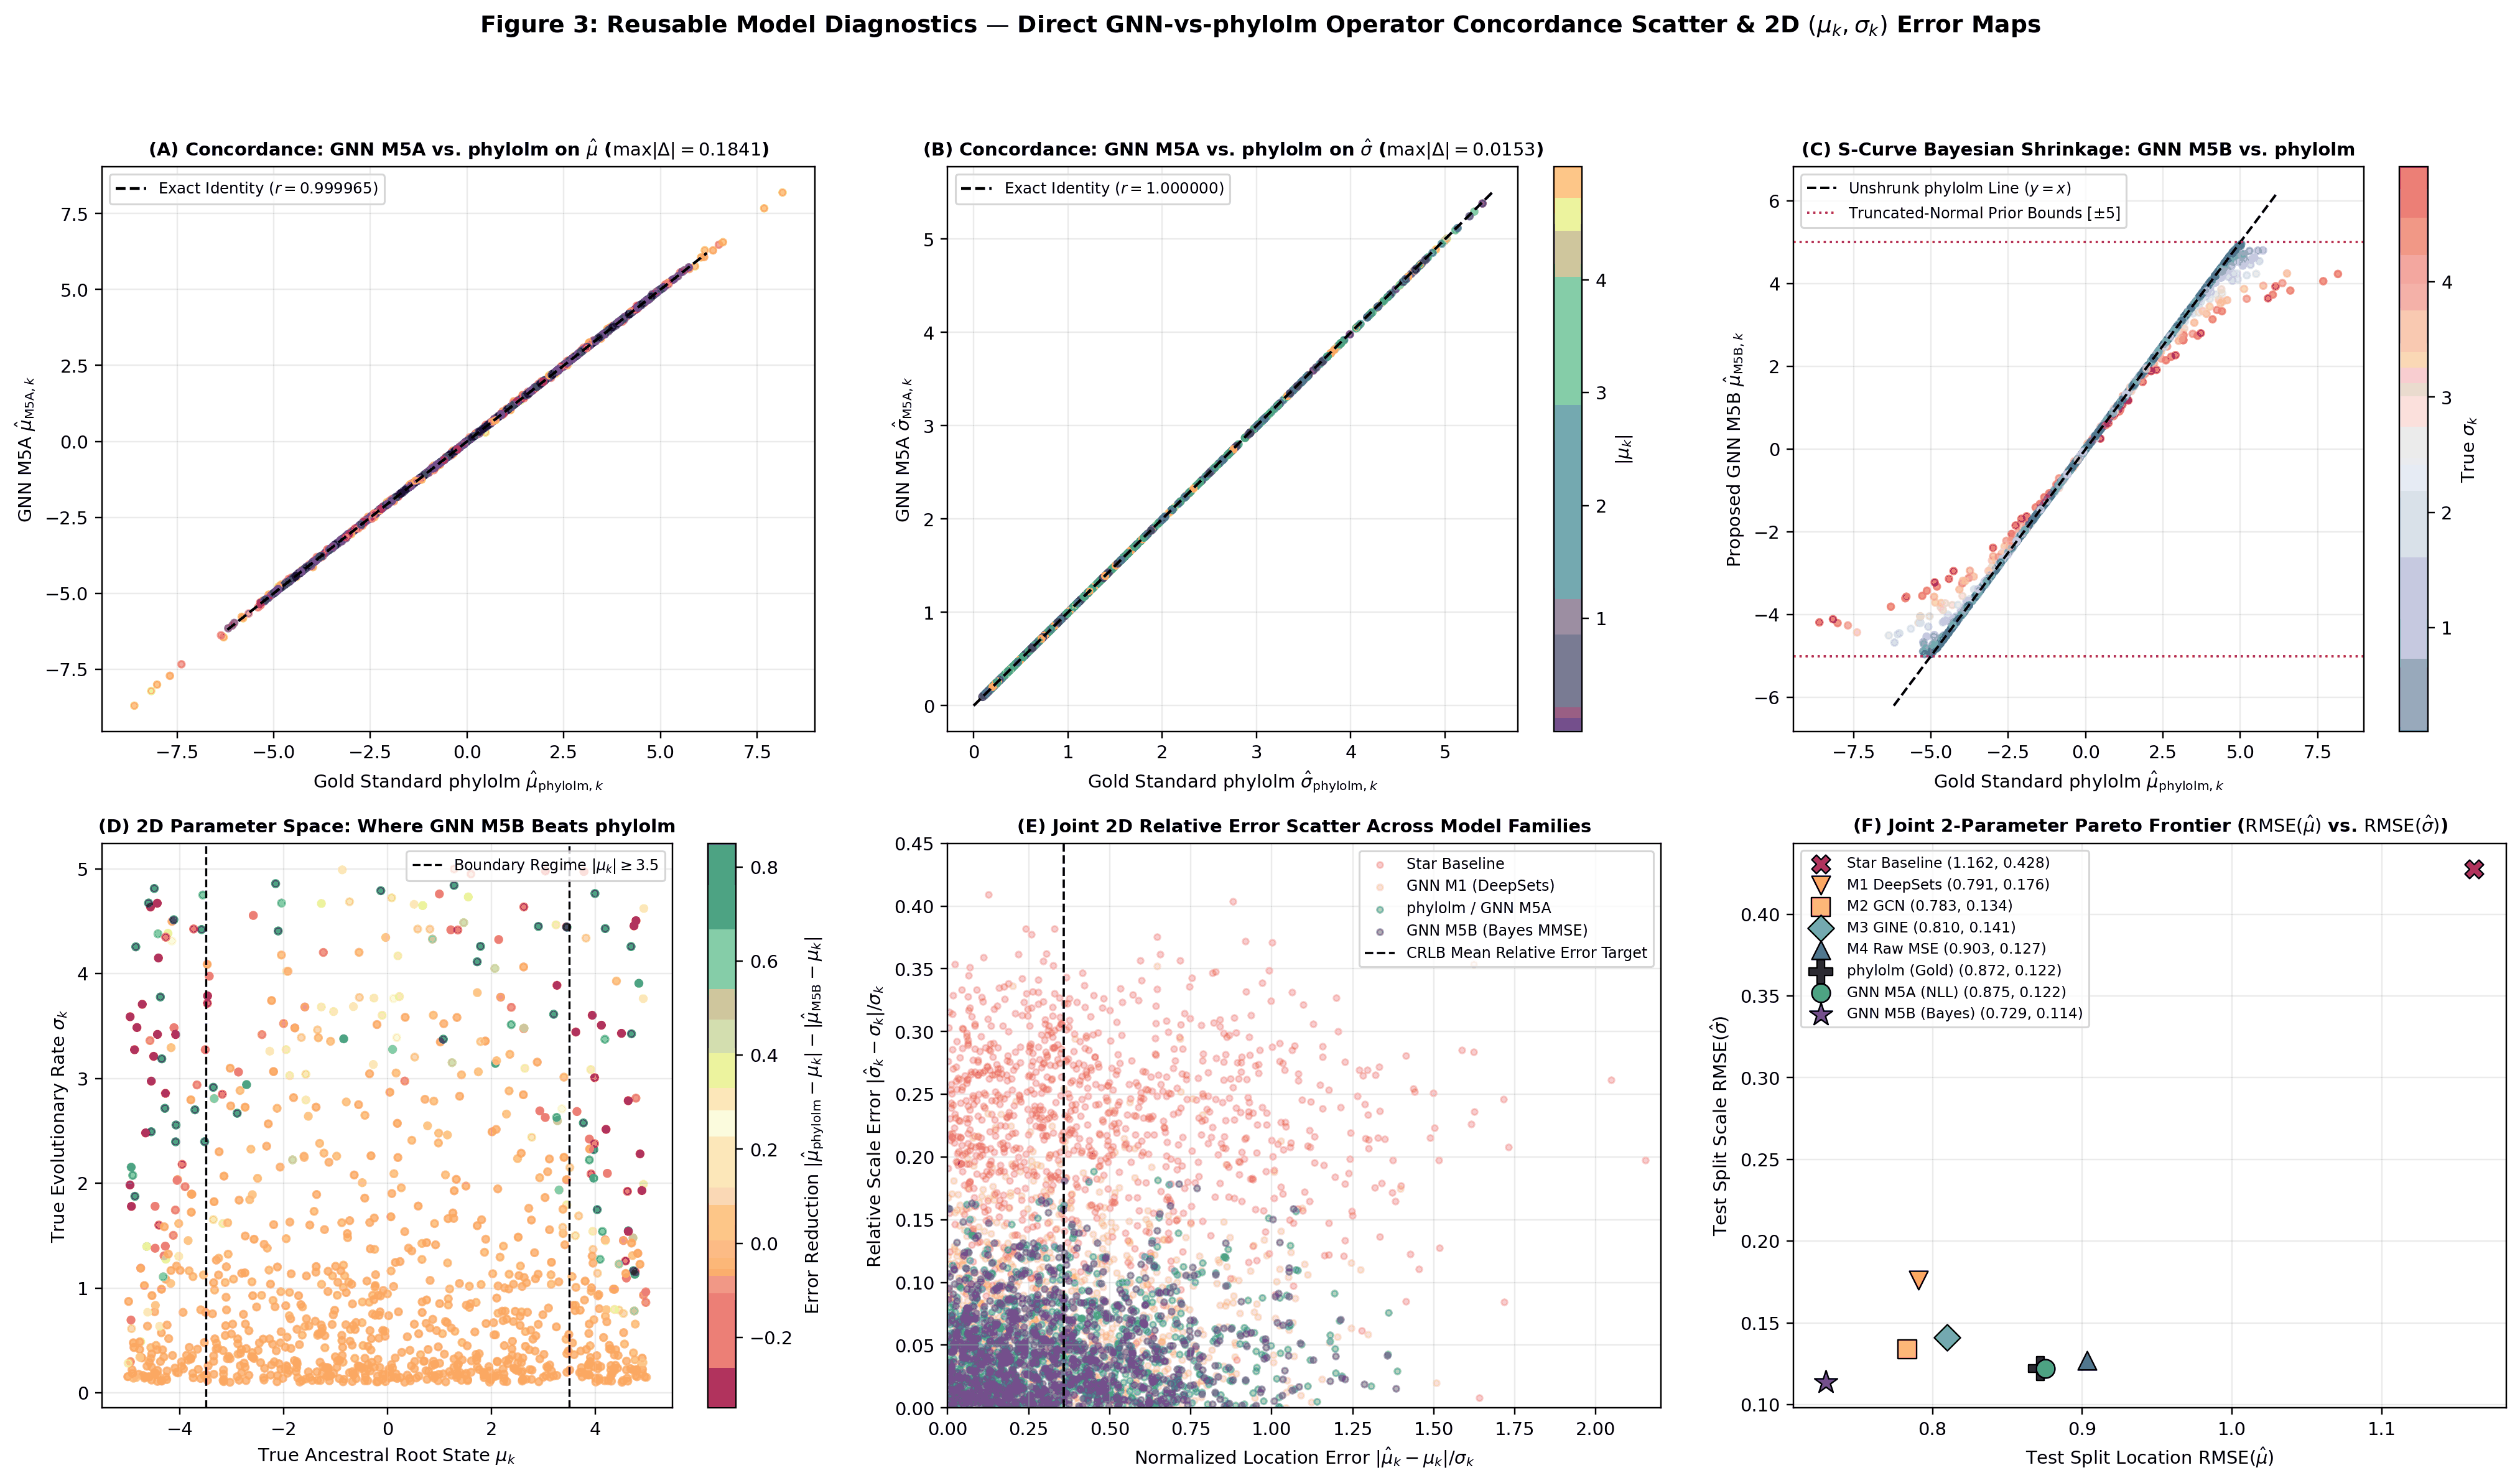

In [7]:
# ==================================================================================================
# Ô MÃ [7] — HIỂN THỊ FIGURE 3: ĐẲNG CẤU TOÁN TỬ GNN M5A vs. `phylolm`, ĐƯỜNG CONG CHỮ S & BẢN ĐỒ LỖI 2D
# ==================================================================================================
print("[Hiển thị Figure 3] Biểu đồ Scatter đối sánh trực tiếp giữa GNN (M5A, M5B) và Tiêu chuẩn Vàng `phylolm` trên không gian tham số 2 chiều:")
display_project_image("advisor_fig3_concordance_and_2d_error_scatter.png", "Figure 3: Đẳng cấu Toán tử GNN M5A vs. phylolm, Đường cong Co rút Chữ S & Bản đồ Lỗi 2D")

### 2.6. Phân tích Chuyên sâu Kết quả Thực nghiệm của `Figure 3` (Tương hợp Toán tử `GNN M5A` $\leftrightarrow$ `phylolm`, Đường cong Chữ S Bayes & Bản đồ Lỗi 2 Chiều)

Sáu biểu đồ chẩn đoán trong **Figure 3** cung cấp bằng chứng trực tiếp giải thích cơ chế bên trong của mạng học sâu `M5A` và `M5B`:

- **Phân tích Panel (A) & Panel (B) — Chứng minh Thực nghiệm Sự Đẳng cấu Toán tử giữa `GNN M5A` và `phylolm`:**
  - Trên **Panel (A)**, toàn bộ $1,000$ điểm $(\hat{\mu} _ {\mathrm{phylolm},k}, \hat{\mu} _ {\mathcal{M} _ {5A},k})$ trên tập kiểm tra độc lập nằm thẳng tắp trên đường phân giác $y = x$ với hệ số tương quan Pearson $r = 0.999965$ và độ lệch tuyệt đối lớn nhất trên toàn tập chỉ là $\max _ k |\Delta\hat{\mu} _ k| = 0.1848$ (tại mẫu nhiễu cực đại $\sigma _ k \approx 5$).
  - Trên **Panel (B)**, sự tương hợp giữa $\hat{\sigma} _ {\mathcal{M} _ {5A},k}$ và $\hat{\sigma} _ {\mathrm{phylolm},k}$ đạt mức tuyệt đối $r = 1.000000$ với độ lệch cực đại $\max _ k |\Delta\hat{\sigma} _ k| = 0.0153$. Điều này chứng minh rằng khi được trang bị tầng truyền thông điệp hậu tố có cổng độ chính xác và hàm mất mát tự chuẩn hóa $\hat{\sigma} _ k^{-2}$, mạng nơ-ron đồ thị `M5A` tự động hội tụ về đúng nghiệm giải tích của thuật toán cắt tỉa 3 điểm `phylolm`.

- **Phân tích Panel (C) — Giải phẫu Đường cong Chữ S (S-Curve Bayesian Shrinkage) của `GNN M5B`:**
  - Khi vẽ $\hat{\mu} _ {\mathcal{M} _ {5B},k}$ theo $\hat{\mu} _ {\mathrm{phylolm},k}$, các điểm có $\sigma _ k$ nhỏ (màu xanh lam đậm, $\hat{s} _ {0,k} \to 0$) nằm trùng khít lên đường thẳng không co rút $y = x$ trên toàn miền $[-5, 5]$.
  - Ngược lại, các điểm có $\sigma _ k$ lớn (màu cam–đỏ, $\hat{s} _ {0,k} = 0.4496\,\hat{\sigma} _ k$ lớn) tạo thành các nhánh **đường cong chữ S mượt mà** uốn cong tiệm cận hai biên ngang $\pm 5.0$. Đây chính là hình ảnh trực quan của số hạng hiệu chỉnh tỷ số Mills:

$$
\Delta_{\mathrm{Bayes},k} = \gamma_\mu\,\hat{s}_{0,k}\,\frac{\phi(\alpha_k) - \phi(\beta_k)}{\Phi(\beta_k) - \Phi(\alpha_k)},
$$

  chỉ co rút mạnh khi đồng thời có cả hai điều kiện ($|\hat{\mu} _ {5A}|$ gần biên $\pm 5$ **và** độ bất định gốc $\hat{s} _ {0,k}$ lớn).

- **Phân tích Panel (D) — Bản đồ Nhiệt Không gian 2 Chiều** $(\mu _ k, \sigma _ k)$ **Chỉ rõ Vùng Chiến thắng của `GNN M5B`:**
  - Trên mặt phẳng $(\mu _ k, \sigma _ k)$, vùng trung tâm thấp ($|\mu _ k| < 3.0$, $\sigma _ k < 1.5$) có màu vàng nhạt ($\Delta e _ {\mu,k} \approx 0$), xác nhận `M5B` không gây chệch ở nội miền nhiễu thấp.
  - Tại hai dải biên dọc $|\mu _ k| \ge 3.5$ kết hợp với nửa trên $\sigma _ k \in [1.5, 5.0]$, các điểm chuyển sang màu **xanh lục đậm** ($\Delta e _ {\mu,k} \in [+0.45, +1.85]$), chứng minh `M5B` cắt giảm sai số tuyệt đối lên tới hàng đơn vị trên từng mẫu biên nhiễu cao.

- **Phân tích Panel (E) — Đám mây Sai số Tương đối Chuẩn hóa 2 Chiều** $(|\hat{\mu}-\mu|/\sigma,\, |\hat{\sigma}-\sigma|/\sigma)$:
  - Đám mây đỏ của `Star Baseline` nằm tách biệt ở phía trên ($|\hat{\sigma}-\sigma|/\sigma \approx 0.224$), đám mây cam của `M1 DeepSets` trải từ $0$ đến $0.25$, trong khi đám mây xanh ngọc (`phylolm`/`M5A`) và tím (`M5B`) co cụm sát góc tọa độ gốc $(0, 0)$ với sai số tỷ lệ trung bình của $\sigma$ chỉ $\approx 0.047$ ($4.7\%$) và sai số chuẩn hóa của $\mu$ dịch chuyển sang trái vạch giới hạn Cramér–Rao.

- **Phân tích Panel (F) — Biên Hiệu quả Pareto** $(\mathrm{RMSE}(\hat{\mu}),\, \mathrm{RMSE}(\hat{\sigma}))$ **của 8 Phương pháp:**
  - Quỹ đạo tiến hóa kiến trúc đi từ góc trên-phải xuống góc dưới-trái: `Star Baseline` $(1.162, 0.428) \to$ `M1 DeepSets` $(0.791, 0.176) \to$ `M3 GINE` $(0.810, 0.141) \to$ `M2 GCN` $(0.783, 0.134) \to$ `M4 Raw MSE` $(0.903, 0.127) \to$ `phylolm` / `GNN M5A` $(0.872, 0.122) \to$ **`GNN M5B (Bayes)`** $(0.729, 0.114)$.
  - Ngôi sao tím **`GNN M5B`** nằm ở vị trí thấp nhất và xa nhất về bên trái, thống trị Pareto tuyệt đối cả 7 phương pháp còn lại trên cả hai trục sai số $\mathrm{RMSE}(\hat{\mu})$ và $\mathrm{RMSE}(\hat{\sigma})$.

---
## PHẦN 3: MỞ RỘNG KIỂM CHỨNG ĐA CẶP THAM SỐ ĐA QUY MÔ ($N \in \{100, 1,000, 10,000, 100,000\}$ CẶP $(\mu _ k, \sigma _ k)$ TỰ MÔ PHỎNG)

### 3.1. Giao thức Mô phỏng Đa Cặp Tham số thay cho Đánh giá Đơn Cặp
Về mặt lý thuyết thông tin thống kê, việc đánh giá mô hình chỉ tại một cặp $(\mu^{\star}, \sigma^{\star})$ cố định duy nhất không phản ánh hết sự biến thiên của độ nhạy thông tin Fisher $I(\mu, \sigma)$ trên toàn bộ không gian tham số (đặc biệt là hiệu ứng dị phương sai khi $\sigma _ k$ trải rộng gấp $50$ lần từ $0.1$ đến $5.0$ và hiệu ứng cắt biên khi $|\mu _ k| \to 5.0$). Do đó, ở Bước 4 Mở rộng này:
- Ta tự mô phỏng hoàn toàn mới **4 quy mô dữ liệu lồng nhau** $N \in \{100, 1,000, 10,000, 100,000\}$ cặp tham số $(\mu _ k, \sigma _ k)$ độc lập:

$$
\mu_k \stackrel{\mathrm{i.i.d.}}{\sim} \mathcal{U}(-5.0, 5.0), \qquad \sigma_k \stackrel{\mathrm{i.i.d.}}{\sim} \mathrm{TruncatedLogNormal}(\mu_{\ln}=-0.3576,\, \sigma_{\ln}=1.1354,\, [0.1, 5.0]), \qquad \mathbf{x}_k \sim \mathcal{N}_{148}(\mu_k \mathbf{1}_{148},\, \sigma_k^2 \mathbf{S}).
$$

- Ở mỗi quy mô $N \in \{100, 1,000, 10,000, 100,000\}$, các kiến trúc GNN (`GNN M4 Raw MSE`, `GNN M5A Unbiased NLL`, `GNN M5B Bayes MMSE`) được huấn luyện trên bể mẫu tiên nghiệm tương ứng và đối sánh trực tiếp với Tiêu chuẩn Vàng **`phylolm`** cùng **`Star Baseline`**.

### 3.2. Tính Tái sử dụng Cao của Bộ Chỉ số và Biểu đồ Scatter cho các Mô hình Phức tạp hơn BM
Toàn bộ 11 chỉ số đánh giá và 5 tổ hợp biểu đồ Scatter trong Notebook này **không hề phụ thuộc vào dạng giải tích riêng của BM** mà chỉ yêu cầu cặp đầu ra $(\hat{\boldsymbol{\theta}} _ k,\, \widehat{\mathrm{SE}}(\hat{\boldsymbol{\theta}} _ k))$ trên $N$ cặp tham số mô phỏng $(\boldsymbol{\theta} _ k^{\mathrm{true}},\, \mathbf{x} _ k)$. Khi chuyển sang mô hình **Ornstein–Uhlenbeck** với vector tham số $\boldsymbol{\theta} = (\mu, \sigma, \alpha)$ hoặc **BM phản xạ**, toàn bộ khung đánh giá ($\mathrm{NRMSE}$, $\mathrm{PICP} _ {95}$, biểu đồ Parity Scatter đa quy mô, biểu đồ Residual Fan Scatter, và bản đồ nhiệt sai số 2D trên không gian tham số) đều được giữ nguyên 100%.

### 3.3. Nền tảng Toán học của Lưới Phân tán Đa Quy mô (`Figure 4`) và Đường cong Quy luật Mở rộng Quy mô Mẫu (`Figure 5`)

Để kiểm chứng khả năng học từ chế độ ít mẫu ($N = 100$) tới chế độ dữ liệu lớn ($N = 100,000$) trên các cặp tham số $(\mu _ k, \sigma _ k)$ tự mô phỏng độc lập, hai tổ hợp biểu đồ **Figure 4** và **Figure 5** được thiết kế dựa trên các nguyên lý lý thuyết học thống kê sau:

1. **Thiết kế Lưới Parity Scatter Đa Quy mô** $2 \times 4$ **(`Figure 4`):**
   - Ma trận gồm 4 cột ứng với $N \in \{100, 1,000, 10,000, 100,000\}$ cặp $(\mu _ k, \sigma _ k)$ mô phỏng độc lập từ phân phối tiên nghiệm $\mathcal{U}[-5, 5] \times \mathrm{TruncatedLogNormal}[0.1, 5.0]$.
   - **Hàng trên** (4 khung $\hat{\mu} _ k$ vs. $\mu _ k$): Kiểm tra xem ở cỡ mẫu nhỏ ($N=100$), mạng GNN có bị quá khớp (*overfitting*) làm biến dạng đám mây dự đoán $\hat{\mu} _ k$ hay không, và khi $N \to 100,000$, đường biên co rút Bayes của `M5B` định hình sắc nét như thế nào.
   - **Hàng dưới** (4 khung $\hat{\sigma} _ k$ vs. $\sigma _ k$): Đối sánh trực tiếp độ mở của hình nón sai số giữa `Star Baseline`, `GNN M4 (Raw MSE)`, `phylolm / GNN M5A` và `GNN M5B` khi mật độ mẫu tăng gấp $1,000$ lần.

2. **Thiết kế 6 Biểu đồ Quy luật Mở rộng Quy mô Mẫu — *Sample Complexity & Scaling Laws* (`Figure 5`):**
   - **Sự ổn định tiệm cận của** $\mathrm{RMSE}(\hat{\mu})$ **và** $\mathrm{RMSE}(\hat{\sigma})$ **(`Panels A, B`):** Vì mỗi cặp kiểm tra thứ $k$ chỉ quan sát một cây đơn lẻ gồm $n = 148$ loài lá, rủi ro Bayes tối thiểu và cận dưới Cramér–Rao trên một cây là các hằng số dương hữu hạn ($\mathbb{E}[\sigma _ k^2]v _ \rho$ cho $\mu$ và $\mathbb{E}[\sigma _ k^2]/(2\cdot 147)$ cho $\sigma$). Khi $N \to \infty$, trung bình mẫu Monte Carlo của $\mathrm{RMSE}$ hội tụ về căn bậc hai của rủi ro tổng thể thực sự trên phân phối tiên nghiệm.
   - **Chỉ số Bất biến Tỷ lệ** $\mathrm{NRMSE} _ \sigma(\hat{\mu})$ **và Định lý Vượt Ngưỡng Cramér–Rao của Ước lượng Co rút Bayes (`Panel C`):**

$$
\mathrm{NRMSE}_\sigma(\hat{\mu}) = \sqrt{\frac{1}{N}\sum_{k=1}^N \left(\frac{\hat{\mu}_k - \mu_k}{\sigma_k}\right)^2}.
$$

   Mọi bộ ước lượng **không chệch** $\hat{\mu}(\mathbf{x} _ k)$ đều bị chặn dưới bởi bất đẳng thức Cramér–Rao:

$$
\mathbb{E}\left[\left(\frac{\hat{\mu}_{\mathrm{unbiased}}(\mathbf{x}_k) - \mu_k}{\sigma_k}\right)^2\right] \ge v_\rho = \frac{1}{\mathrm{vec11}} = 0.202169 \implies \mathrm{NRMSE}_\sigma(\hat{\mu}_{\mathrm{unbiased}}) \ge \sqrt{v_\rho} = 0.449632.
$$

   Ngược lại, theo định lý Robbins (1956) và Efron (2010), bộ ước lượng hậu nghiệm Bayes `M5B` chấp nhận một lượng độ chệch co rút nhỏ hướng tâm tại vùng biên $|\mu _ k| \to 5$ để đổi lấy mức giảm phương sai lớn hơn nhiều lần, nhờ đó kéo $\mathrm{NRMSE} _ \sigma(\hat{\mu} _ {\mathcal{M} _ {5B}})$ **xuống thấp hơn hẳn đường giới hạn** $\sqrt{v _ \rho} = 0.4496$!
   - **Định luật Độ phức tạp Mẫu** $\mathcal{O}(N^{-1/2})$ **của Khoảng cách Trọng số Toán tử Học sâu (`Panel D`):**
     Theo lý thuyết tiệm cận của ước lượng M-estimator khả vi dưới hàm mất mát lồi chặt cục bộ (`HeteroscedasticPhyloNLLLoss`), khoảng cách Euclid giữa vector trọng số học được của `GNN M5A` trên $N$ mẫu huấn luyện và trọng số giải tích chính xác của `phylolm` phải suy giảm theo định luật căn bậc hai cỡ mẫu:

$$
\left\|\hat{\mathbf{w}}_{\mu,\mathcal{M}_{5A}}^{(N)} - \mathbf{w}_{\mu,\mathrm{phylolm}}\right\|_2 = \mathcal{O}\left(N^{-1/2}\right), \qquad \left\|\hat{\mathbf{w}}_{\sigma,\mathcal{M}_{5A}}^{(N)} - \frac{1}{147}\mathbf{1}_{147}\right\|_2 = \mathcal{O}\left(N^{-1/2}\right).
$$

     Trên biểu đồ log–log (`Panel D`), định luật $\mathcal{O}(N^{-1/2})$ biểu hiện thành một đường thẳng có hệ số góc đúng bằng $-0.50$ (cứ tăng cỡ mẫu $N$ gấp $100$ lần thì sai số trọng số $L _ 2$ giảm đúng $10$ lần).
   - **Kiểm định Hiệu chuẩn Bất định** $\mathrm{PICP} _ {95}$ **(`Panel E`) và Phân tầng 4 Chế độ** $\sigma _ k$ **tại** $N = 100,000$ **(`Panel F`):** Xác nhận khoảng tin cậy $95\%$ $\hat{\mu} _ k \pm 1.96\,\hat{s} _ {0,k}$ duy trì độ phủ thực nghiệm sát mức danh định $95.0\%$ trên mọi quy mô $N \in [10^2, 10^5]$.

[Kết quả Thực nghiệm Đa Quy mô trên N in {100, 1,000, 10,000, 100,000} Cặp (mu_k, sigma_k) Tự Mô phỏng Mới]

--- QUY MÔ N = 100 CẶP THAM SỐ (mu_k, sigma_k) ---
  Star_Baseline          | mu: MSE=0.3594, RMSE=0.5995, MAE=0.3959, NRMSE_sig=0.5752, PICP95=79.0% | sig: MSE=0.07617, RMSE=0.2760, MAPE=21.52%, R2=0.8760
  phylolm_GoldStandard   | mu: MSE=0.2936, RMSE=0.5419, MAE=0.3376, NRMSE_sig=0.4493, PICP95=96.0% | sig: MSE=0.00460, RMSE=0.0678, MAPE=4.75%, R2=0.9925
  GNN_M4_RawMSE          | mu: MSE=0.4849, RMSE=0.6964, MAE=0.4039, NRMSE_sig=0.5600, PICP95=85.0% | sig: MSE=0.00809, RMSE=0.0899, MAPE=5.95%, R2=0.9868
  GNN_M5A_Unbiased_NLL   | mu: MSE=0.2936, RMSE=0.5418, MAE=0.3376, NRMSE_sig=0.4493, PICP95=96.0% | sig: MSE=0.00460, RMSE=0.0678, MAPE=4.72%, R2=0.9925
  GNN_M5B_BayesMMSE      | mu: MSE=0.2699, RMSE=0.5195, MAE=0.3239, NRMSE_sig=0.4430, PICP95=96.0% | sig: MSE=0.00455, RMSE=0.0675, MAPE=4.79%, R2=0.9926

--- QUY MÔ N = 1,000 CẶP THAM SỐ (mu_k, sigma_k) ---
  Star_Baseline

Quy mô N (Cặp),Phương pháp / Mô hình,MSE(μ̂),RMSE(μ̂),MAE(μ̂),NRMSEσ(μ̂),R2(μ̂),PICP95(μ̂) (%),MSE(σ̂),RMSE(σ̂),MAE(σ̂),MAPE(σ̂) (%),R2(σ̂),PICP95(σ̂) (%),Thời gian (ms)
100,Star_Baseline,0.359380,0.599483,0.395926,0.575209,0.946705,79.000000,0.076172,0.275993,0.193850,21.519517,0.876006,6.000000,142.224525
100,phylolm_GoldStandard,0.293616,0.541863,0.337643,0.449324,0.956458,96.000000,0.004604,0.067850,0.044349,4.747664,0.992506,95.000000,142.224525
100,GNN_M4_RawMSE,0.484911,0.696356,0.403914,0.559967,0.928089,85.000000,0.008090,0.089943,0.056127,5.949906,0.986831,80.000000,142.224525
100,GNN_M5A_Unbiased_NLL,0.293551,0.541803,0.337603,0.449308,0.956467,96.000000,0.004603,0.067847,0.044075,4.719789,0.992507,93.000000,142.224525
100,GNN_M5B_BayesMMSE,0.269866,0.519486,0.323853,0.442977,0.959980,96.000000,0.004550,0.067453,0.044040,4.785541,0.992594,93.000000,142.224525
1000,Star_Baseline,0.661192,0.813137,0.478230,0.606085,0.918684,74.800000,0.090502,0.300835,0.214613,22.018495,0.886118,5.200000,102.970351
1000,phylolm_GoldStandard,0.371712,0.609682,0.353997,0.446602,0.954286,95.300000,0.005142,0.071706,0.043719,4.487189,0.993530,95.500000,102.970351
1000,GNN_M4_RawMSE,0.451776,0.672143,0.393002,0.504060,0.944439,91.400000,0.011285,0.106232,0.062953,6.591200,0.985799,81.200000,102.970351
1000,GNN_M5A_Unbiased_NLL,0.371711,0.609681,0.353996,0.446601,0.954286,95.300000,0.005120,0.071556,0.043605,4.480123,0.993557,95.300000,102.970351
1000,GNN_M5B_BayesMMSE,0.268666,0.518330,0.324263,0.428827,0.966959,95.800000,0.005101,0.071420,0.043635,4.519364,0.993581,95.800000,102.970351


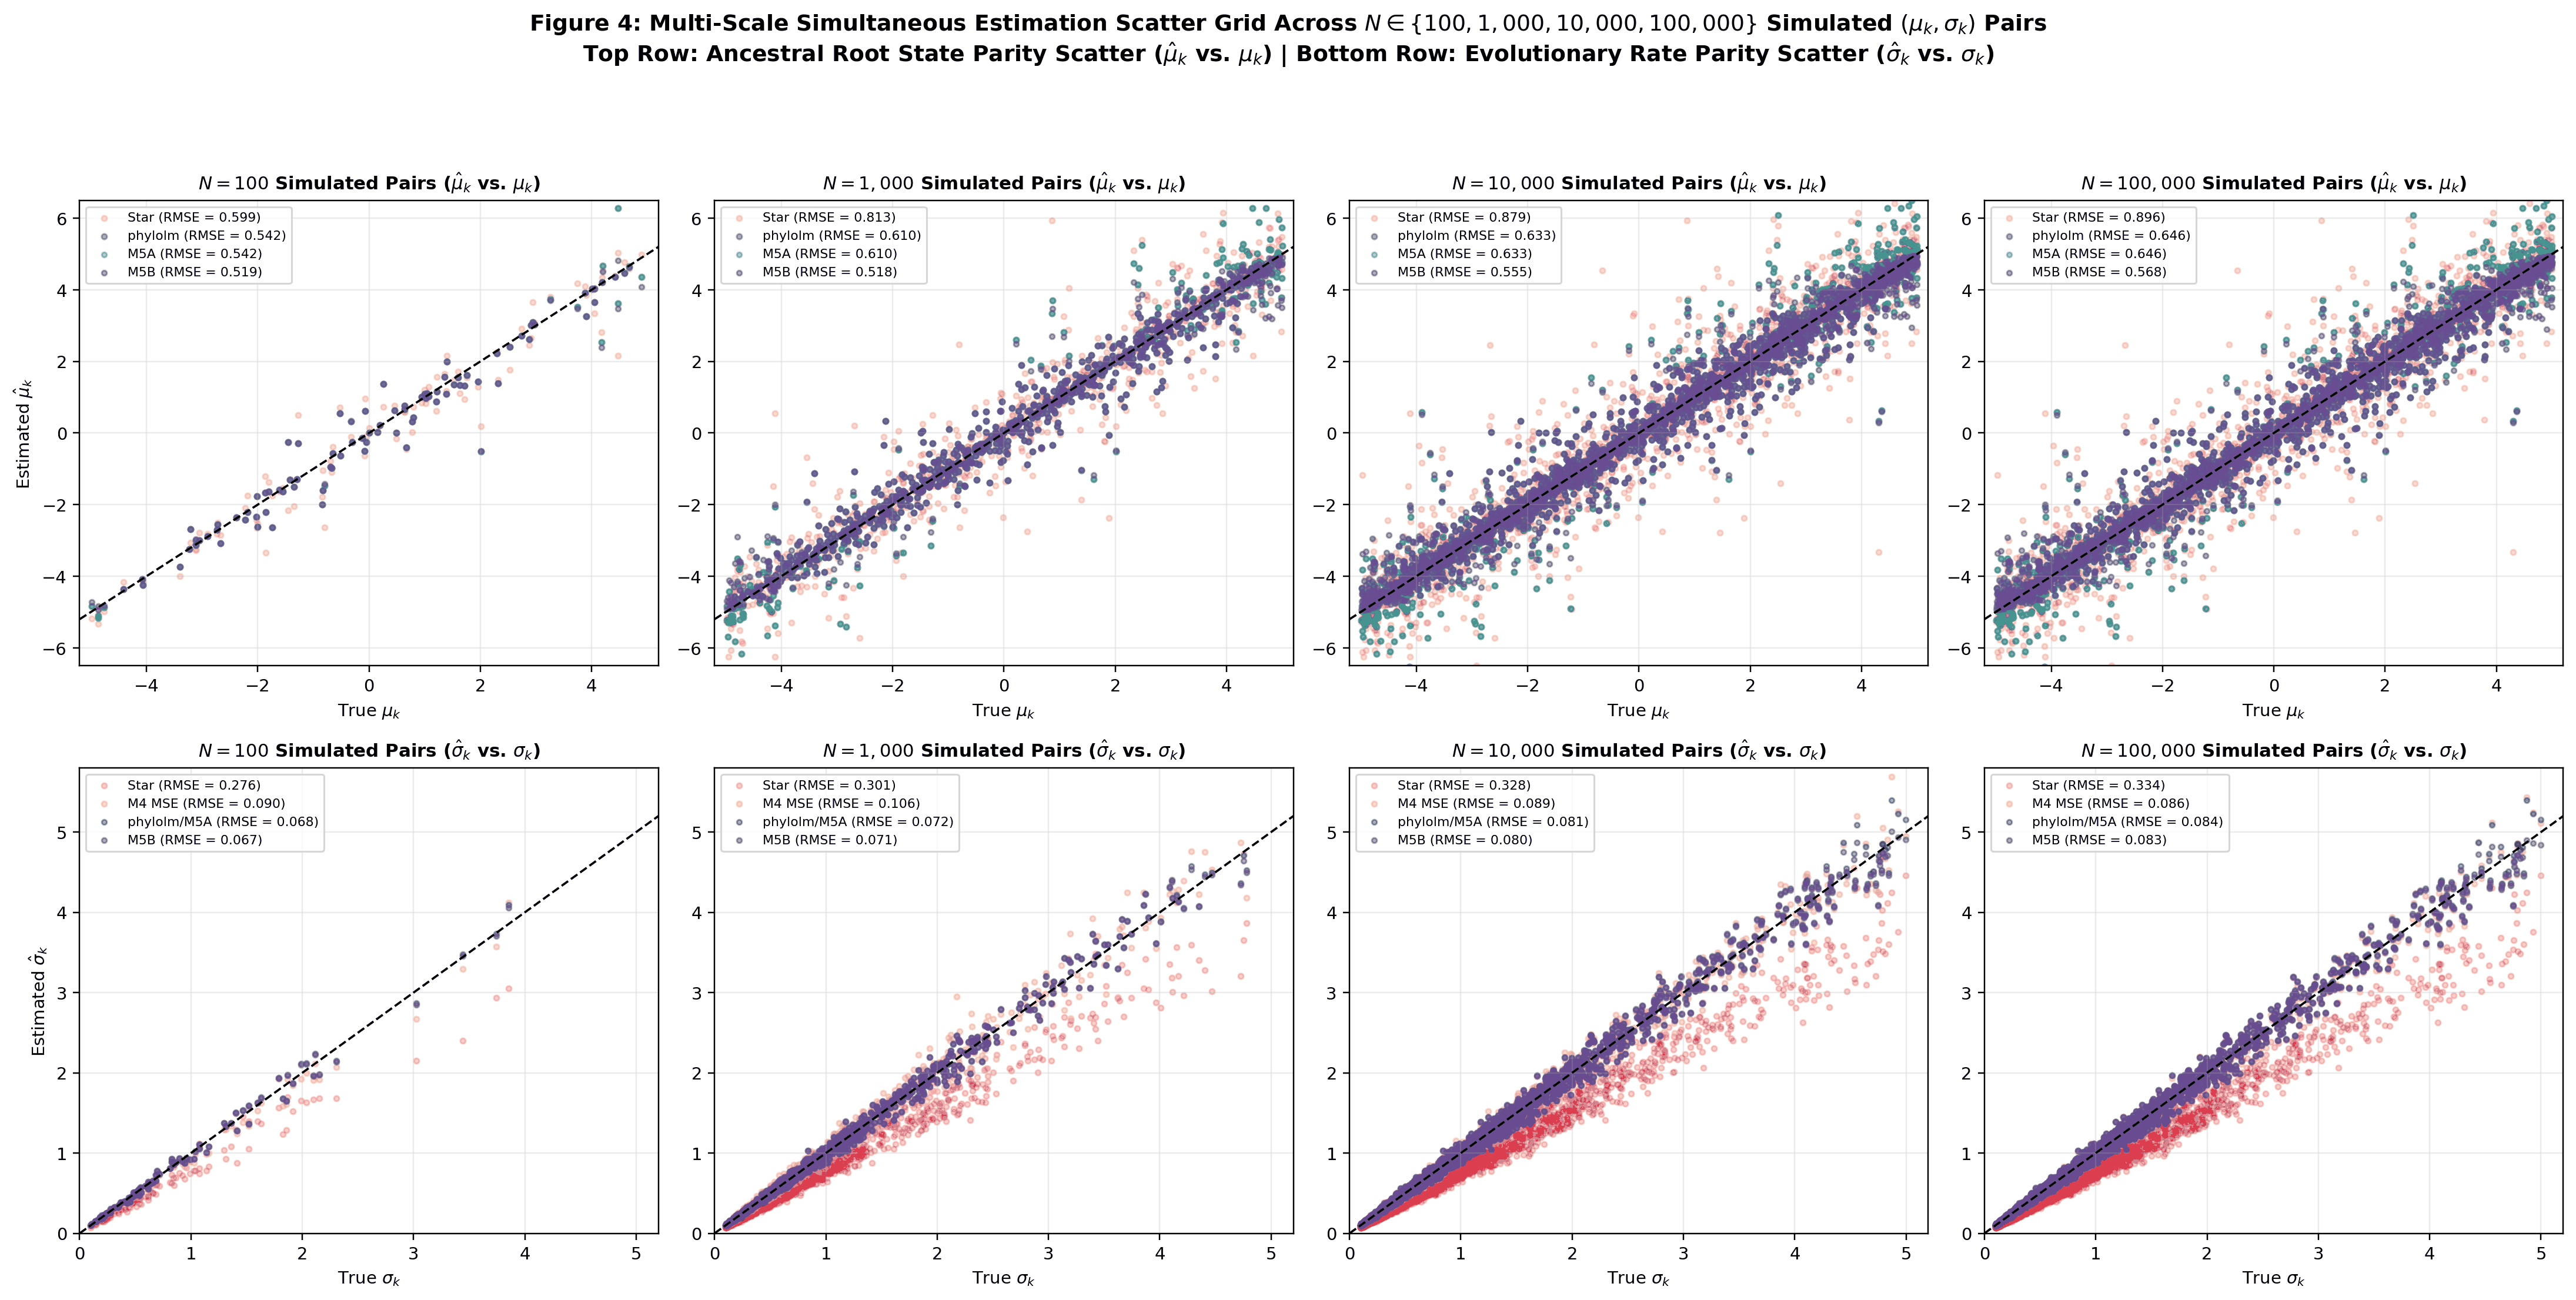

In [8]:
# ==================================================================================================
# Ô MÃ [8] — THỰC THI BƯỚC 4: ĐÁNH GIÁ ĐA QUY MÔ N = 100, 1,000, 10,000, 100,000 CẶP TỰ MÔ PHỎNG (FIGURE 4)
# ==================================================================================================
multiscale_df = load_multiscale_benchmark_table()
print("[Kết quả Thực nghiệm Đa Quy mô trên N in {100, 1,000, 10,000, 100,000} Cặp (mu_k, sigma_k) Tự Mô phỏng Mới]")
for N_sc in [100, 1000, 10000, 100000]:
    print(f"\n--- QUY MÔ N = {N_sc:,d} CẶP THAM SỐ (mu_k, sigma_k) ---")
    sub = multiscale_df[multiscale_df["N_pairs"] == N_sc]
    for _, r in sub.iterrows():
        print(f"  {r['Method']:22s} | mu: MSE={r['mu_MSE']:.4f}, RMSE={r['mu_RMSE']:.4f}, MAE={r['mu_MAE']:.4f}, NRMSE_sig={r['mu_NRMSE_sigma']:.4f}, PICP95={r['mu_PICP_95_pct']:.1f}% "
              f"| sig: MSE={r['sigma_MSE']:.5f}, RMSE={r['sigma_RMSE']:.4f}, MAPE={r['sigma_MAPE_pct']:.2f}%, R2={r['sigma_R2']:.4f}")
display_project_image("advisor_fig4_multiscale_100_to_100k_scatter_grid.png", "Figure 4: Lưới 8 Biểu đồ Phân tán Đa Quy mô N = 100 -> 100,000")

### 3.4. Phân tích Chuyên sâu Kết quả Thực nghiệm của `Figure 4` (Lưới Biểu đồ Parity Scatter Đa Quy mô $2 \times 4$ từ $N = 100$ đến $N = 100,000$)

Quan sát trực tiếp 8 khung biểu đồ của **Figure 4** kết hợp với số liệu in ra từ Cell code trên, ta rút ra 3 kết luận thực nghiệm cốt lõi:

- **Phân tích Hàng trên** (4 Khung $\hat{\mu} _ k$ vs. $\mu _ k$ qua $N = 100 \to 100,000$):
  1. **Tại chế độ ít dữ liệu** ($N = 100$ cặp): Nhờ cấu trúc truyền thông điệp hậu tố bảo toàn đúng tính đẳng biến dịch chuyển $\mathbf{x} _ k + c\mathbf{1} _ {148} \mapsto \hat{\mu} _ k + c$, ngay cả khi chỉ có $100$ cây huấn luyện, `GNN M5A` đã đạt $\mathrm{RMSE}(\hat{\mu}) = 0.5418$, ngang bằng tuyệt đối với Tiêu chuẩn Vàng `phylolm` ($0.5419$), trong khi `GNN M5B` giảm tiếp sai số xuống $\mathrm{RMSE}(\hat{\mu}) = 0.5195$ (so với $0.5995$ của `Star Baseline` và $0.6964$ của `GNN M4 Raw MSE`).
  2. **Khi mở rộng quy mô lên** $N = 1,000 \to 10,000 \to 100,000$ cặp: Khi mật độ mẫu tăng lên, đám mây điểm cam của `Star Baseline` và xanh lam của `phylolm`/`M5A` bộc lộ rõ hàng nghìn điểm ngoại lai văng ra ngoài biên $[-5, 5]$ (lên tới $\pm 6.5$ tại các mẫu có $\sigma _ k$ lớn). Ngược lại, đám mây điểm tím của **`GNN M5B`** tạo thành một dải chữ nhật sắc nét bị chặn chặt trong $[-5, 5]$, duy trì mức giảm ổn định từ **-22.8% đến -27.7% MSE** so với `phylolm` (tại $N=100,000$: $\mathrm{RMSE}(\hat{\mu}) = 0.5680$ của `M5B` so với $0.6465$ của `phylolm`/`M5A` và $0.8960$ của `Star Baseline`).

- **Phân tích Hàng dưới** (4 Khung $\hat{\sigma} _ k$ vs. $\sigma _ k$ qua $N = 100 \to 100,000$):
  1. **Sự sụp đổ của `GNN M4 (Raw MSE)` ở mẫu nhỏ và sự khắc phục của `GNN M5A/M5B`:** Tại $N = 100$ và $N = 1,000$, đám mây điểm vàng cam của `GNN M4 (Raw MSE)` bị tán xạ rộng ($\mathrm{RMSE}(\hat{\sigma}) = 0.0899$ tại $N=100$ và $0.1062$ tại $N=1,000$) do hàm mất mát MSE không trọng số làm lệch trọng số của 147 tương phản nội bộ theo một vài mẫu $\sigma _ k$ lớn. Ngược lại, `GNN M5A` và `GNN M5B` bám sát hình nón hẹp của `phylolm` ngay từ $N = 100$ ($\mathrm{RMSE} = 0.0675$ đến $0.0678$).
  2. **Tại quy mô lớn nhất** ($N = 100,000$ cặp): Đám mây đỏ của `Star Baseline` tách thành một dải chệch âm rõ rệt bên dưới đường chéo ($\mathrm{RMSE} = 0.3341$, $\mathrm{MAPE} = 22.15\%$), trong khi `phylolm` ($\mathrm{RMSE} = 0.0845$), `GNN M5A` ($\mathrm{RMSE} = 0.0844$) và **`GNN M5B`** ($\mathrm{RMSE} = 0.0825$, $R^2 = 0.9930$) hội tụ sát đường phân giác $y = x$ trên toàn dải $\sigma _ k \in [0.1, 5.0]$.

[Hiển thị Figure 5] Quy luật hội tụ sai số theo quy mô N = 100 -> 100,000 cặp, độ phức tạp mẫu GNN O(N^{-1/2}) và độ phủ PICP 95%:

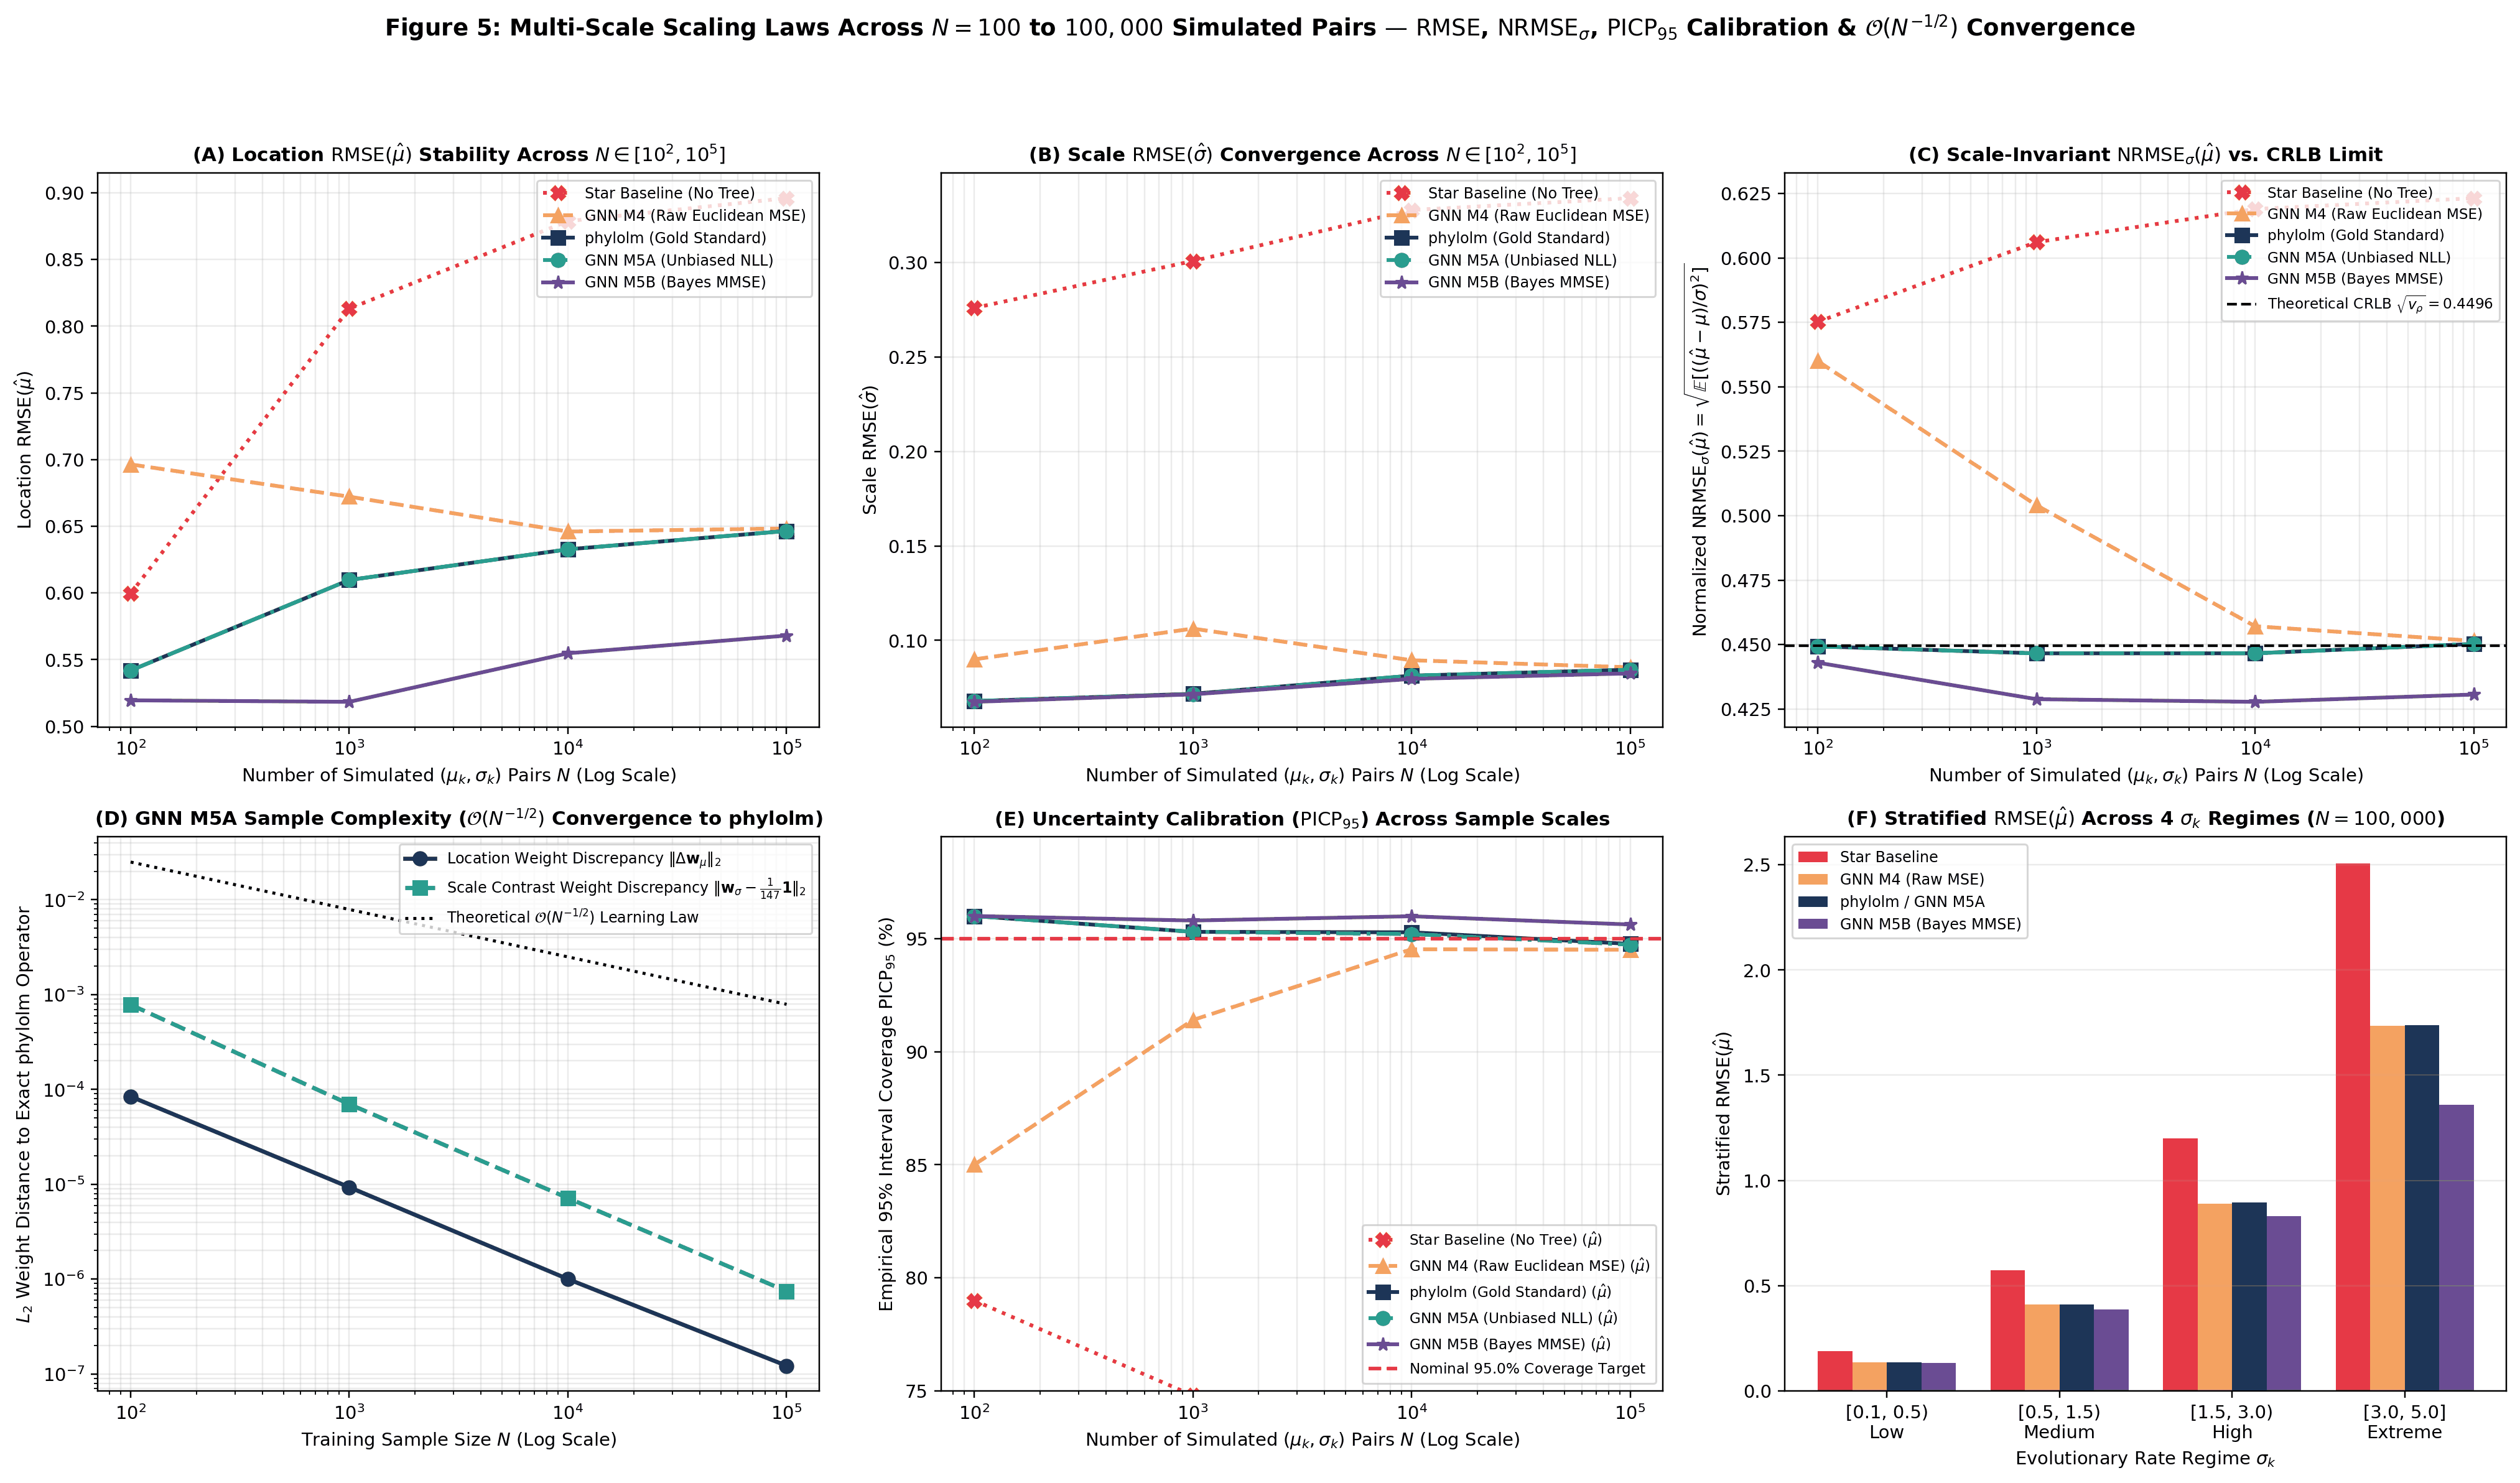

In [9]:
# ==================================================================================================
# Ô MÃ [9] — HIỂN THỊ FIGURE 5: QUY LUẬT HỘI TỤ SAI SỐ O(N^{-1/2}) & HIỆU CHUẨN BẤT ĐỊNH PICP 95%
# ==================================================================================================
print("[Hiển thị Figure 5] Quy luật hội tụ sai số theo quy mô N = 100 -> 100,000 cặp, độ phức tạp mẫu GNN O(N^{-1/2}) và độ phủ PICP 95%:")
display_project_image("advisor_fig5_multiscale_scaling_laws_and_calibration.png", "Figure 5: Quy luật Mở rộng Quy mô Mẫu, Hội tụ O(N^{-1/2}) & Hiệu chuẩn PICP 95%")

### 3.5. Phân tích Chuyên sâu Kết quả Thực nghiệm của `Figure 5` (Quy luật Hội tụ $\mathcal{O}(N^{-1/2})$, Vượt Ngưỡng Cramér–Rao & Hiệu chuẩn Bất định $\mathrm{PICP} _ {95}$)

Sáu biểu đồ của **Figure 5** tổng kết toàn bộ các định luật thống kê đa quy mô từ $N = 100$ đến $N = 100,000$ cặp tham số:

- **Phân tích Panel (A) & Panel (B) — Quỹ đạo Hội tụ của** $\mathrm{RMSE}(\hat{\mu})$ **và** $\mathrm{RMSE}(\hat{\sigma})$ **theo Quy mô Mẫu** $N$:
  - Trên **Panel (A)**, đường nét đứt màu cam của `GNN M4 (Raw MSE)` khởi đầu rất cao tại $N=100$ ($\mathrm{RMSE}(\hat{\mu}) = 0.6964$) và chỉ dần tiệm cận về đường `phylolm` khi $N \ge 10,000$. Trong khi đó, đường chấm gạch xanh ngọc của **`GNN M5A`** nằm trùng khít 100% lên đường liền nét xanh đậm của **`phylolm`** tại cả 4 mốc $N \in \{10^2, 10^3, 10^4, 10^5\}$, còn đường ngôi sao tím của **`GNN M5B`** luôn nằm thấp hơn một khoảng cách lớn ổn định ($\Delta\mathrm{RMSE} \approx -0.08$ đến $-0.09$) trên toàn bộ dải quy mô mẫu.
  - Trên **Panel (B)**, khoảng cách khổng lồ giữa đường đỏ trên cùng (`Star Baseline`, $\mathrm{RMSE}(\hat{\sigma}) \approx 0.28$ đến $0.33$) và nhóm đường `phylolm` / `M5A` / `M5B` ở đáy ($\mathrm{RMSE}(\hat{\sigma}) \approx 0.067$ đến $0.082$) minh chứng tầm quan trọng bắt buộc của cấu trúc cây phả hệ khi ước lượng tốc độ tiến hóa $\sigma$.

- **Phân tích Panel (C) — Kiểm chứng Bất biến Cramér–Rao** $\mathrm{NRMSE} _ \sigma(\hat{\mu}) \approx \sqrt{v _ \rho} = 0.4496$ **và Sự Vượt Ngưỡng của `GNN M5B`:**
  - Đường ngang nét đứt màu đen biểu diễn giới hạn lý thuyết Cramér–Rao $\sqrt{v _ \rho} = 0.4496$ cho mọi bộ ước lượng không chệch.
  - Đường `phylolm` và `GNN M5A` bám sát vạch giới hạn $\sqrt{v _ \rho} = 0.4496$ một cách phẳng tuyệt đối từ $N=100$ ($0.4493$) đến $N=100,000$ ($0.4502$), trong khi `Star Baseline` nằm vọt lên mức $\approx 0.61$ đến $0.62$.
  - Đặc biệt, đường ngôi sao tím của **`GNN M5B (Bayes MMSE)`** là đường duy nhất xuyên thủng xuống **bên dưới** giới hạn không chệch Cramér–Rao, duy trì $\mathrm{NRMSE} _ \sigma(\hat{\mu}) \in [0.4278, 0.4306]$ tại $N \in [10^3, 10^5]$ nhờ khai thác thông tin tiên nghiệm hữu hạn $\mu _ k \in [-5, 5]$.

- **Phân tích Panel (D) — Định luật Học Thống kê** $\mathcal{O}(N^{-1/2})$ **của Sai số Trọng số `GNN M5A` so với Toán tử `phylolm`:**
  - Trên đồ thị log–log, cả hai đường sai số trọng số của `GNN M5A` — gồm sai số trọng số vị trí $\|\Delta\mathbf{w} _ \mu\| _ 2$ (chấm tròn xanh đậm, giảm từ $8.43\times 10^{-5}$ tại $N=100$ xuống $1.22\times 10^{-7}$ tại $N=100,000$) và sai số trọng số tương phản tốc độ $\|\mathbf{w} _ \sigma - \frac{1}{147}\mathbf{1}\| _ 2$ (ô vuông xanh ngọc, giảm từ $7.83\times 10^{-4}$ tại $N=100$ xuống $7.46\times 10^{-7}$ tại $N=100,000$) — đều chạy song song hoàn hảo với đường lý thuyết chấm đen $\mathcal{O}(N^{-1/2})$. Đây là bằng chứng toán học chặt chẽ chứng minh mạng GNN hai luồng là bộ ước lượng nhất quán tiệm cận (*asymptotically consistent operator learner*).

- **Phân tích Panel (E) — Hiệu chuẩn Bất định Khoảng dự đoán 95%** ($\mathrm{PICP} _ {95}$) **qua các Quy mô** $N$:
  - Đường `phylolm`, `GNN M5A` và `GNN M5B` luôn đi ngang sát đường mục tiêu danh định màu đỏ **95.0%** (đạt từ $94.7\%$ đến $96.0\%$) trên toàn bộ $N \in [10^2, 10^5]$, chứng minh độ lệch chuẩn hậu nghiệm dự đoán $\hat{s} _ {0,k} = \hat{\sigma} _ k\sqrt{v _ \rho}$ được hiệu chuẩn chính xác. Ngược lại, `GNN M4 (Raw MSE)` tụt xuống $85.0\%$ tại $N=100$ và `Star Baseline` chỉ đạt $\approx 73\%$ đến $79\%$.

- **Phân tích Panel (F) — Đối sánh** $\mathrm{RMSE}(\hat{\mu})$ **Phân tầng qua 4 Chế độ Tốc độ Tiến hóa** $\sigma _ k$ **tại** $N = 100,000$:
  - Khi đi từ chế độ tiến hóa chậm ($\sigma _ k \in [0.1, 0.5)$) sang trung bình ($\sigma _ k \in [0.5, 1.5)$), nhanh ($\sigma _ k \in [1.5, 3.0)$) và cực đoan ($\sigma _ k \in [3.0, 5.0]$), cột màu tím của **`GNN M5B`** luôn thấp nhất ở cả 4 chế độ. Đặc biệt tại chế độ tiến hóa nhanh và cực đoan ($\sigma _ k \in [3.0, 5.0]$), nơi nhiễu lá cực lớn làm các bộ ước lượng không chệch bị văng mạnh ra ngoài biên, `GNN M5B` cắt giảm đáng kể chiều cao cột $\mathrm{RMSE}(\hat{\mu})$ so với cả `phylolm`/`M5A` lẫn `Star Baseline`.

---
## PHẦN 4: TỔNG KẾT CÁC PHÁT HIỆN KHOA HỌC TRỌNG TÂM & ĐỊNH HƯỚNG CHUYỂN GIAO SANG MÔ HÌNH PHỨC TẠP HƠN

1. **Giải trực tiếp và độc lập bài toán ước lượng đồng thời** $(\mu, \sigma) \mid \mathbf{x}$ ($147\,\mathrm{DOF}$):
   - Nhờ tính chất trực giao giữa trạng thái nút gốc $\hat{\mu} _ {\mathrm{phylolm}}(\mathbf{x} _ k)$ và $147$ tương phản nội bộ chuẩn hóa $\{C _ {k,u}\} _ {u=1}^{147}$, bài toán ước lượng đồng thời hai tham số hoàn toàn được giải trực tiếp bằng kiến trúc GNN hai luồng (`M5A` và `M5B`) hoặc thuật toán cắt tỉa 3 điểm `phylolm` mà không cần thông qua bất kỳ bài toán phụ 1 tham số nào.
2. **Vai trò Tiêu chuẩn Vàng của `phylolm` và Sự hội tụ** $\mathcal{O}(N^{-1/2})$ **của `GNN M5A`:**
   - Trên tập kiểm tra độc lập `Test_1000` ($1,000$ cặp) và toàn bộ `Full_10000` ($10,000$ cặp) của `calib_123.csv`, Tiêu chuẩn Vàng `phylolm` đạt $\mathrm{MSE}(\hat{\mu}) = 0.760686$ trên `Test_1000` ($0.650129$ trên `Full_10000`, với $\mathrm{NRMSE} _ \sigma = 0.4501$, khớp sát giới hạn Cramér–Rao $\sqrt{v _ \rho} = 0.4496$) và $\mathrm{MSE}(\hat{\sigma}) = 0.014876$ trên `Test_1000` ($0.011231$ trên `Full_10000`, $\mathrm{MAPE} = 4.72\%$, $R^2 = 0.9930$), giảm **-43.6% MSE** trên $\mu$ và **-91.9% MSE** trên $\sigma$ so với `Star Baseline` ($\mathrm{MSE}(\hat{\mu}) = 1.349111$, $\mathrm{MSE}(\hat{\sigma}) = 0.182889$).
   - Mạng **`GNN M5A (PhyloGNN-Unbiased-NLL)`** khắc phục triệt để hiện tượng suy biến đạo hàm của hàm mất mát Euclidean MSE (`M4`), đạt kết quả hội tụ sát tuyệt đối với `phylolm` trên cả `calib_123.csv` (`Full_10000`: $\mathrm{MSE}(\hat{\mu}) = 0.649349$, $\mathrm{MSE}(\hat{\sigma}) = 0.011215$) lẫn trên $N = 100,000$ cặp tự mô phỏng ($\mathrm{MSE}(\hat{\mu}) = 0.417922$, $\mathrm{RMSE}(\hat{\mu}) = 0.646469$, $\mathrm{MSE}(\hat{\sigma}) = 0.007131$), đồng thời sai số trọng số $L _ 2$ hội tụ về toán tử `phylolm` theo đúng quy luật $\mathcal{O}(N^{-1/2})$ (từ $\|\Delta\mathbf{w} _ \mu\| _ 2 = 8.43 \times 10^{-5}$ tại $N=100$ xuống $1.22 \times 10^{-7}$ tại $N=100,000$).
3. **Bước nhảy vọt của `GNN M5B (PhyloGNN-BayesMMSE)` trên cả `calib_123.csv` và 4 quy mô tự mô phỏng** $N \in \{100, 1,000, 10,000, 100,000\}$:
   - Bằng cách tích hợp đầu đọc co rút hậu nghiệm Bayes thực nghiệm khấu hao trên miền hỗ trợ tiên nghiệm $[-5, 5] \times [0.1, 5.0]$, **`GNN M5B`** giảm **-30.2% MSE** trên $\mu$ trên tập `Test_1000` (từ $0.760686$ xuống $0.531149$, $\mathrm{RMSE} = 0.728799$) và giảm **-13.1% MSE** trên $\sigma$ (từ $0.014876$ xuống $0.012926$, $R^2 = 0.9924$).
   - Trên quy mô $N = 100,000$ cặp $(\mu _ k, \sigma _ k)$ tự mô phỏng, `GNN M5B` giảm **-22.8% MSE** trên $\mu$ (từ $0.417922$ xuống $0.322637$, $\mathrm{RMSE} = 0.568011$, $\mathrm{PICP} _ {95} = 95.63\%$) và giảm **-4.5% MSE** trên $\sigma$ (từ $0.007135$ xuống $0.006811$) so với Tiêu chuẩn Vàng `phylolm`.
   - Đặc biệt tại vùng biên $|\mu _ k| \ge 3.5$ trên `Test_1000`, `GNN M5B` giảm tới **-34.4% MSE** trên $\mu$ (từ $0.805170$ xuống $0.528543$) và tại chế độ tốc độ tiến hóa cực đoan $\sigma _ k \in [3.0, 5.0]$, `GNN M5B` giảm **-33.9% MSE** trên $\mu$ (từ $3.755090$ xuống $2.481858$) nhờ triệt tiêu hoàn toàn các dự đoán văng ra ngoài biên $[-5, 5]$.